# 02. Multimodal Data Preprocessing

## Multimodal Medicinal Plant Leaf Retrieval
### Using Visual and Textual Features

---

## 1. Overview

This notebook prepares the medicinal plant leaf dataset
for visual and textual feature extraction.

Based on the previous Exploratory Data Analysis (EDA),
the original dataset contains 105 image-text pairs
across five medicinal plant classes.

After identifying one redundant image copy,
104 candidate records remain for preprocessing.

## 2. Dataset Summary

| Indicator | Value |
|---|---:|
| Original images | 105 |
| Plant classes | 5 |
| Valid images | 105 |
| Corrupted images | 0 |
| Redundant image copies | 1 |
| Preprocessing candidates | 104 |
| Records requiring manual review | 47 |
| Modalities | 2 |

## 3. Objectives

- Prepare and validate preprocessing candidates.
- Preserve the original dataset.
- Standardize image dimensions.
- Preserve the original leaf aspect ratio.
- Separate leaf objects from image backgrounds.
- Inspect image preprocessing quality.
- Clean and normalize textual descriptions.
- Preserve image-text associations.
- Prepare the dataset for feature extraction.

## 4. Image Preprocessing Pipeline

1. Image loading
2. Image resizing with aspect ratio preservation
3. Padding to 256 x 256 pixels
4. Leaf segmentation
5. Image quality inspection
6. Color space conversion
7. Processed image and mask storage

Noise filtering will only be applied when necessary.

## 5. Text Preprocessing Pipeline

1. Text loading
2. Case folding
3. Text cleaning
4. Whitespace normalization
5. Tokenization
6. Text quality inspection

Stemming and stopword removal are not applied
by default to preserve morphological information.

## 6. Target Feature Extraction

### Image Modality

- HSV Histogram: Color features
- GLCM: Texture features
- Hu Moments: Shape features

### Text Modality

- TF-IDF: Textual features

## 7. Expected Outputs

- Preprocessed leaf images
- Binary leaf segmentation masks
- Cleaned textual descriptions
- Processed multimodal metadata
- Preprocessing visualizations
- Preprocessing quality report

## 8. Data Quality Considerations

Records requiring manual verification are retained
as preprocessing candidates.

Their botanical labels and textual descriptions
must be reviewed before final retrieval evaluation.

The original dataset remains unchanged.

In [1]:
# ==================================================
# IMPORT LIBRARIES
# ==================================================

# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# File and directory management
import os
from pathlib import Path

# Image loading and processing
import cv2
from PIL import Image, ImageOps

# Image processing and segmentation
from skimage import filters, morphology, measure

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import unicodedata
from collections import Counter

# File integrity verification
import hashlib

# Progress monitoring
from tqdm.auto import tqdm

# Notebook display
from IPython.display import display

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
cv2.setRNGSeed(RANDOM_STATE)

# Visualization configuration
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120

# Enable progress bar for Pandas
tqdm.pandas()

print("=" * 60)
print("All preprocessing libraries imported successfully!")
print("=" * 60)

# Display library versions
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version  : {np.__version__}")
print(f"OpenCV version : {cv2.__version__}")

All preprocessing libraries imported successfully!
Pandas version : 3.1.1
NumPy version  : 2.5.5
OpenCV version : 5.1.0


In [2]:
# ==================================================
# DATASET PATH CONFIGURATION
# ==================================================

# 1. Determine project root directory
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


# 2. Dataset directories
DATASET_DIR = PROJECT_ROOT / "dataset"
RAW_DIR = DATASET_DIR / "raw"
PROCESSED_DIR = DATASET_DIR / "processed"


# 3. Input metadata files
ORIGINAL_METADATA = DATASET_DIR / "metadata.csv"

CANDIDATE_METADATA = (
    PROCESSED_DIR /
    "metadata_preprocessing_candidates.csv"
)


# 4. Output preprocessing directories
PROCESSED_IMAGE_DIR = PROCESSED_DIR / "images"
MASK_DIR = PROCESSED_DIR / "masks"


# 5. Output metadata file
PROCESSED_METADATA = (
    PROCESSED_DIR / "metadata_processed.csv"
)


# 6. Results directories
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"


# 7. Validate input files and directories
required_inputs = {
    "Raw Dataset": RAW_DIR,
    "Original Metadata": ORIGINAL_METADATA,
    "Candidate Metadata": CANDIDATE_METADATA
}

print("DATASET PATH CONFIGURATION")
print("=" * 60)

print("\n1. PROJECT ROOT")
print(PROJECT_ROOT)

print("\n2. INPUT PATH VALIDATION")

missing_inputs = []

for name, path in required_inputs.items():

    exists = (
        path.is_dir()
        if name == "Raw Dataset"
        else path.is_file()
    )

    status = "OK" if exists else "NOT FOUND"

    print(f"[{status}] {name}")
    print(f"    {path}")

    if not exists:
        missing_inputs.append(name)


# Stop execution if required inputs are missing
if missing_inputs:

    raise FileNotFoundError(
        f"Required inputs not found: {missing_inputs}"
    )


# 8. Create output directories
output_directories = {
    "Processed Directory": PROCESSED_DIR,
    "Processed Images": PROCESSED_IMAGE_DIR,
    "Binary Masks": MASK_DIR,
    "Results Directory": RESULTS_DIR,
    "Figures Directory": FIGURES_DIR,
    "Metrics Directory": METRICS_DIR
}

print("\n3. OUTPUT DIRECTORY CONFIGURATION")

for name, path in output_directories.items():

    path.mkdir(
        parents=True,
        exist_ok=True
    )

    print(f"[OK] {name}")
    print(f"    {path}")


# 9. Display output metadata destination
print("\n4. OUTPUT METADATA")

print(f"Processed metadata:")
print(f"    {PROCESSED_METADATA}")


# 10. Final configuration summary
print("\n5. CONFIGURATION SUMMARY")
print("=" * 60)

print("[PASS] All required input paths are valid.")
print("[PASS] All output directories are ready.")

print("\nDataset path configuration completed successfully!")

DATASET PATH CONFIGURATION

1. PROJECT ROOT
D:\Project\Multimodal_Leaf_Retrieval

2. INPUT PATH VALIDATION
[OK] Raw Dataset
    D:\Project\Multimodal_Leaf_Retrieval\dataset\raw
[OK] Original Metadata
    D:\Project\Multimodal_Leaf_Retrieval\dataset\metadata.csv
[OK] Candidate Metadata
    D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_preprocessing_candidates.csv

3. OUTPUT DIRECTORY CONFIGURATION
[OK] Processed Directory
    D:\Project\Multimodal_Leaf_Retrieval\dataset\processed
[OK] Processed Images
    D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\images
[OK] Binary Masks
    D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\masks
[OK] Results Directory
    D:\Project\Multimodal_Leaf_Retrieval\results
[OK] Figures Directory
    D:\Project\Multimodal_Leaf_Retrieval\results\figures
[OK] Metrics Directory
    D:\Project\Multimodal_Leaf_Retrieval\results\metrics

4. OUTPUT METADATA
Processed metadata:
    D:\Project\Multimodal_Leaf_Retrieval\dataset\proces

In [3]:
# ==================================================
# LOAD PREPROCESSING CANDIDATES
# ==================================================

print("LOAD PREPROCESSING CANDIDATES")
print("=" * 60)


# 1. Load candidate metadata
df = pd.read_csv(
    CANDIDATE_METADATA,
    encoding="utf-8-sig"
)

# Preserve initial candidate metadata
df_original = df.copy()


# 2. Display dataset information
print("\n1. DATASET INFORMATION")

print(f"Total records : {len(df)}")
print(f"Total columns : {df.shape[1]}")
print(f"Total classes : {df['kelas'].nunique()}")
print(f"Dataset shape : {df.shape}")


# 3. Validate required columns
required_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur",
    "deskripsi_lengkap",
    "image_hash",
    "quality_status",
    "review_candidate"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

print("\n2. COLUMN VALIDATION")

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("[OK] All required columns are available.")


# 4. Display sample metadata
print("\n3. SAMPLE METADATA")

display(
    df[
        [
            "nama_file",
            "kelas",
            "tampilan_daun",
            "deskripsi_lengkap",
            "quality_status"
        ]
    ].head()
)


# 5. Analyze class distribution after deduplication
print("\n4. CLASS DISTRIBUTION")

class_counts = (
    df["kelas"]
    .value_counts()
    .sort_index()
)

class_distribution = pd.DataFrame({
    "Number of Images": class_counts,
    "Percentage (%)": (
        class_counts / len(df) * 100
    ).round(2)
})

display(class_distribution)


# 6. Analyze dataset quality status
print("\n5. DATASET QUALITY STATUS")

quality_counts = df[
    "quality_status"
].value_counts()

quality_distribution = pd.DataFrame({
    "Number of Records": quality_counts,
    "Percentage (%)": (
        quality_counts / len(df) * 100
    ).round(2)
})

display(quality_distribution)


# 7. Resolve image paths
df["absolute_image_path"] = df[
    "image_path"
].apply(
    lambda path: PROJECT_ROOT / Path(str(path))
)


# 8. Validate image availability
df["image_exists"] = df[
    "absolute_image_path"
].apply(
    lambda path: path.is_file()
)

valid_images = int(
    df["image_exists"].sum()
)

missing_images = int(
    (~df["image_exists"]).sum()
)

print("\n6. IMAGE PATH VALIDATION")

print(f"Available images : {valid_images}")
print(f"Missing images   : {missing_images}")

if missing_images == 0:

    print("[OK] All candidate images are available.")

else:

    display(
        df.loc[
            ~df["image_exists"],
            [
                "nama_file",
                "kelas",
                "absolute_image_path"
            ]
        ]
    )


# 9. Validate textual descriptions
text_descriptions = (
    df["deskripsi_lengkap"]
    .fillna("")
    .astype(str)
    .str.strip()
)

empty_descriptions = int(
    text_descriptions.eq("").sum()
)

available_descriptions = (
    len(df) - empty_descriptions
)

print("\n7. TEXT DESCRIPTION VALIDATION")

print(
    f"Available descriptions : "
    f"{available_descriptions}"
)

print(
    f"Empty descriptions     : "
    f"{empty_descriptions}"
)

if empty_descriptions == 0:

    print("[OK] All textual descriptions are available.")

else:

    display(
        df.loc[
            text_descriptions.eq(""),
            ["nama_file", "kelas"]
        ]
    )


# 10. Verify duplicate image hashes
valid_hashes = df[
    "image_hash"
].dropna()

duplicate_hashes = int(
    valid_hashes.duplicated().sum()
)

missing_hashes = int(
    df["image_hash"].isna().sum()
)

print("\n8. DUPLICATE HASH VALIDATION")

print(f"Unique image hashes : {valid_hashes.nunique()}")
print(f"Duplicate hashes    : {duplicate_hashes}")
print(f"Missing hashes      : {missing_hashes}")

if duplicate_hashes == 0 and missing_hashes == 0:

    print("[OK] Candidate image hashes are complete and unique.")


# 11. Validate image-text pairs
valid_pairs = int(
    (
        df["image_exists"]
        & text_descriptions.ne("")
    ).sum()
)

print("\n9. MULTIMODAL PAIR VALIDATION")

print(f"Total candidates       : {len(df)}")
print(f"Complete image-text pairs : {valid_pairs}")
print(f"Incomplete pairs       : {len(df) - valid_pairs}")


# 12. Final validation summary
print("\n10. VALIDATION SUMMARY")
print("=" * 60)

if (
    len(df) > 0
    and missing_images == 0
    and empty_descriptions == 0
    and duplicate_hashes == 0
    and missing_hashes == 0
):

    print("[PASS] Candidate dataset passed integrity checks.")

else:

    print("[WARNING] Candidate dataset requires further inspection.")

print(
    "\nRecords requiring manual verification : "
    f"{df['quality_status'].eq('Needs Review').sum()}"
)

print("\nCandidate metadata loaded successfully!")

LOAD PREPROCESSING CANDIDATES

1. DATASET INFORMATION
Total records : 104
Total columns : 17
Total classes : 5
Dataset shape : (104, 17)

2. COLUMN VALIDATION
[OK] All required columns are available.

3. SAMPLE METADATA


,nama_file,kelas,tampilan_daun,deskripsi_lengkap,quality_status
0,mangkok 10.jpeg,Mangkok,belakang,"Daun berwarna hijau tua, berbentuk membulat, d...",Needs Review
1,mangkok 11.png,Mangkok,belakang,"Daun berwarna hijau kekuningan, berbentuk memb...",Ready
2,mangkok 12.png,Mangkok,belakang,"Daun berwarna hijau zaitun, berbentuk membulat...",Ready
3,mangkok 13.png,Mangkok,belakang,"Daun berwarna hijau sedang, berbentuk membulat...",Ready
4,mangkok 14.png,Mangkok,belakang,"Daun berwarna hijau kekuningan, berbentuk memb...",Ready



4. CLASS DISTRIBUTION


,Number of Images,Percentage (%)
kelas,,
Mangkok,20,19.23
Salam,19,18.27
Sambang Darah,20,19.23
Sirih,20,19.23
Tapak Kuda,25,24.04



5. DATASET QUALITY STATUS


,Number of Records,Percentage (%)
quality_status,,
Ready,57,54.81
Needs Review,47,45.19



6. IMAGE PATH VALIDATION
Available images : 104
Missing images   : 0
[OK] All candidate images are available.

7. TEXT DESCRIPTION VALIDATION
Available descriptions : 104
Empty descriptions     : 0
[OK] All textual descriptions are available.

8. DUPLICATE HASH VALIDATION
Unique image hashes : 104
Duplicate hashes    : 0
Missing hashes      : 0
[OK] Candidate image hashes are complete and unique.

9. MULTIMODAL PAIR VALIDATION
Total candidates       : 104
Complete image-text pairs : 104
Incomplete pairs       : 0

10. VALIDATION SUMMARY
[PASS] Candidate dataset passed integrity checks.

Records requiring manual verification : 47

Candidate metadata loaded successfully!


In [4]:
# ==================================================
# DATASET CLEANING AND VERIFICATION
# ==================================================

print("DATASET CLEANING AND VERIFICATION")
print("=" * 60)


# 1. Create working dataset
df_working = df.copy()

initial_records = len(df_working)

print("\n1. INITIAL DATASET")
print(f"Initial candidate records : {initial_records}")


# 2. Normalize metadata fields
metadata_text_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur",
    "deskripsi_lengkap"
]

for column in metadata_text_columns:

    df_working[column] = (
        df_working[column]
        .fillna("")
        .astype(str)
        .str.strip()
    )


# 3. Normalize class labels
class_mapping = {
    "mangkok": "Mangkok",
    "salam": "Salam",
    "sambang darah": "Sambang Darah",
    "sirih": "Sirih",
    "tapak kuda": "Tapak Kuda"
}

df_working["kelas"] = (
    df_working["kelas"]
    .str.lower()
    .replace(class_mapping)
)


# 4. Normalize leaf view labels
view_mapping = {
    "foto depan": "depan",
    "foto belakang": "belakang",
    "front": "depan",
    "back": "belakang",
    "front view": "depan",
    "back view": "belakang"
}

df_working["tampilan_daun"] = (
    df_working["tampilan_daun"]
    .str.lower()
    .replace(view_mapping)
)


# 5. Verify actual image hashes
def verify_image_hash(image_path):

    try:

        sha256 = hashlib.sha256()

        with open(image_path, "rb") as file:

            for block in iter(
                lambda: file.read(65536),
                b""
            ):

                sha256.update(block)

        return sha256.hexdigest()

    except (OSError, TypeError):

        return None


print("\n2. IMAGE INTEGRITY VERIFICATION")

df_working["current_image_hash"] = (
    df_working["absolute_image_path"]
    .progress_apply(verify_image_hash)
)

df_working["hash_verified"] = (
    df_working["current_image_hash"].notna()
    & df_working["current_image_hash"].eq(
        df_working["image_hash"]
    )
)

verified_hashes = int(
    df_working["hash_verified"].sum()
)

failed_hashes = int(
    (~df_working["hash_verified"]).sum()
)

print(f"Verified image hashes : {verified_hashes}")
print(f"Failed verification   : {failed_hashes}")


# 6. Validate essential metadata
essential_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "deskripsi_lengkap"
]

df_working["metadata_complete"] = (
    df_working[essential_columns]
    .ne("")
    .all(axis=1)
)


# 7. Validate class and view labels
expected_classes = {
    "Mangkok",
    "Salam",
    "Sambang Darah",
    "Sirih",
    "Tapak Kuda"
}

expected_views = {
    "depan",
    "belakang"
}

df_working["valid_class"] = (
    df_working["kelas"]
    .isin(expected_classes)
)

df_working["valid_view"] = (
    df_working["tampilan_daun"]
    .isin(expected_views)
)


# 8. Detect remaining exact duplicates
df_working["remaining_duplicate"] = (
    df_working["current_image_hash"].notna()
    & df_working["current_image_hash"]
    .duplicated(keep=False)
)


# 9. Refresh image availability
df_working["image_exists"] = (
    df_working["absolute_image_path"]
    .apply(lambda path: path.is_file())
)


# 10. Determine technical eligibility
df_working["technical_valid"] = (
    df_working["image_exists"]
    & df_working["hash_verified"]
    & df_working["metadata_complete"]
    & df_working["valid_class"]
    & df_working["valid_view"]
    & ~df_working["remaining_duplicate"]
)


# 11. Preserve manual review status
df_working["manual_review_required"] = (
    df_working["quality_status"]
    .eq("Needs Review")
)


# 12. Assign preprocessing eligibility status
df_working["preprocessing_status"] = np.select(
    [
        ~df_working["technical_valid"],
        df_working["manual_review_required"]
    ],
    [
        "Blocked",
        "Eligible - Pending Review"
    ],
    default="Eligible - Technical Checks Passed"
)


# 13. Create verification summary
verification_summary = pd.DataFrame({
    "Validation Indicator": [
        "Initial candidate records",
        "Available image files",
        "Verified image hashes",
        "Complete essential metadata",
        "Valid class labels",
        "Valid leaf view labels",
        "Remaining duplicate records",
        "Technically valid records",
        "Records requiring manual review",
        "Blocked records"
    ],

    "Count": [
        initial_records,
        df_working["image_exists"].sum(),
        df_working["hash_verified"].sum(),
        df_working["metadata_complete"].sum(),
        df_working["valid_class"].sum(),
        df_working["valid_view"].sum(),
        df_working["remaining_duplicate"].sum(),
        df_working["technical_valid"].sum(),
        df_working["manual_review_required"].sum(),
        (~df_working["technical_valid"]).sum()
    ]
})

print("\n3. VERIFICATION SUMMARY")

display(verification_summary)


# 14. Inspect blocked records
blocked_records = df_working[
    ~df_working["technical_valid"]
].copy()

print("\n4. BLOCKED RECORDS")

if blocked_records.empty:

    print("[OK] No technically invalid records detected.")

else:

    display(
        blocked_records[
            [
                "nama_file",
                "kelas",
                "image_exists",
                "hash_verified",
                "metadata_complete",
                "valid_class",
                "valid_view",
                "remaining_duplicate"
            ]
        ]
    )


# 15. Inspect records requiring manual review
manual_review_records = df_working[
    df_working["manual_review_required"]
].copy()

print("\n5. MANUAL REVIEW RECORDS")

print(
    f"Records requiring manual review: "
    f"{len(manual_review_records)}"
)

if not manual_review_records.empty:

    display(
        manual_review_records[
            [
                "nama_file",
                "kelas",
                "tampilan_daun",
                "catatan_verifikasi",
                "preprocessing_status"
            ]
        ].head(10)
    )


# 16. Prepare technically eligible dataset
df_clean = df_working[
    df_working["technical_valid"]
].copy().reset_index(drop=True)


# 17. Analyze cleaned candidate distribution
clean_class_counts = (
    df_clean["kelas"]
    .value_counts()
    .sort_index()
)

clean_distribution = pd.DataFrame({
    "Number of Images": clean_class_counts,

    "Percentage (%)": (
        clean_class_counts
        / len(df_clean) * 100
    ).round(2)
})

print("\n6. CLEANED CANDIDATE DISTRIBUTION")

display(clean_distribution)


# 18. Save verification reports
verification_summary.to_csv(
    METRICS_DIR / "19_dataset_verification_summary.csv",
    index=False
)

df_working.to_csv(
    METRICS_DIR / "20_dataset_verification_details.csv",
    index=False,
    encoding="utf-8-sig"
)

manual_review_records.to_csv(
    METRICS_DIR / "21_manual_review_records.csv",
    index=False,
    encoding="utf-8-sig"
)

blocked_records.to_csv(
    METRICS_DIR / "22_blocked_records.csv",
    index=False,
    encoding="utf-8-sig"
)


# 19. Save technically eligible metadata
df_clean.drop(
    columns=["absolute_image_path"]
).to_csv(
    PROCESSED_DIR / "metadata_verified_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)


# 20. Final verification summary
print("\n7. FINAL CLEANING SUMMARY")
print("=" * 60)

print(f"Initial candidates      : {initial_records}")
print(f"Blocked records         : {len(blocked_records)}")
print(f"Eligible candidates     : {len(df_clean)}")

print(
    f"Pending manual review   : "
    f"{df_clean['manual_review_required'].sum()}"
)

print(
    f"Technical checks passed : "
    f"{(~df_clean['manual_review_required']).sum()}"
)

if df_clean.empty:

    raise ValueError(
        "No eligible records available for preprocessing."
    )

if len(blocked_records) == 0:

    print("\n[PASS] All candidates passed technical validation.")

else:

    print("\n[WARNING] Some records have been blocked.")

if df_clean["manual_review_required"].any():

    print(
        "[REVIEW] Manual verification is still required "
        "before final evaluation."
    )

print("\nOriginal dataset has not been modified.")

print(
    "\nDataset cleaning and verification "
    "completed successfully!"
)

DATASET CLEANING AND VERIFICATION

1. INITIAL DATASET
Initial candidate records : 104

2. IMAGE INTEGRITY VERIFICATION


  0%|          | 0/104 [00:00<?, ?it/s]

Verified image hashes : 104
Failed verification   : 0

3. VERIFICATION SUMMARY


,Validation Indicator,Count
0,Initial candidate records,104
1,Available image files,104
2,Verified image hashes,104
3,Complete essential metadata,104
4,Valid class labels,104
5,Valid leaf view labels,104
6,Remaining duplicate records,0
7,Technically valid records,104
8,Records requiring manual review,47
9,Blocked records,0



4. BLOCKED RECORDS
[OK] No technically invalid records detected.

5. MANUAL REVIEW RECORDS
Records requiring manual review: 47


,nama_file,kelas,tampilan_daun,catatan_verifikasi,preprocessing_status
0,mangkok 10.jpeg,Mangkok,belakang,Tampilan mengikuti folder; verifikasi sisi dau...,Eligible - Pending Review
6,mangkok 6.jpeg,Mangkok,belakang,Tampilan mengikuti folder; verifikasi sisi dau...,Eligible - Pending Review
7,mangkok 7.jpeg,Mangkok,belakang,Detail visual terbatas; periksa foto resolusi ...,Eligible - Pending Review
8,mangkok 8.jpeg,Mangkok,belakang,Tampilan mengikuti folder; verifikasi sisi dau...,Eligible - Pending Review
9,mangkok 9.jpeg,Mangkok,belakang,Tampilan mengikuti folder; verifikasi sisi dau...,Eligible - Pending Review
26,daun salam 6.jpeg,Salam,belakang,Detail visual terbatas; periksa foto resolusi ...,Eligible - Pending Review
27,daun salam 7.jpeg,Salam,belakang,NaN,Eligible - Pending Review
28,daun salam 9.jpeg,Salam,belakang,Detail visual terbatas; periksa foto resolusi ...,Eligible - Pending Review
31,daun salam 2.jpeg,Salam,depan,Detail visual terbatas; periksa foto resolusi ...,Eligible - Pending Review
40,sambang darah 11.png,Sambang Darah,belakang,Warna berbeda dari foto belakang merah; verifi...,Eligible - Pending Review



6. CLEANED CANDIDATE DISTRIBUTION


,Number of Images,Percentage (%)
kelas,,
Mangkok,20,19.23
Salam,19,18.27
Sambang Darah,20,19.23
Sirih,20,19.23
Tapak Kuda,25,24.04



7. FINAL CLEANING SUMMARY
Initial candidates      : 104
Blocked records         : 0
Eligible candidates     : 104
Pending manual review   : 47
Technical checks passed : 57

[PASS] All candidates passed technical validation.
[REVIEW] Manual verification is still required before final evaluation.

Original dataset has not been modified.

Dataset cleaning and verification completed successfully!


In [5]:
# ==================================================
# IMAGE PREPROCESSING CONFIGURATION
# ==================================================

print("IMAGE PREPROCESSING CONFIGURATION")
print("=" * 60)


# 1. Image size configuration
TARGET_WIDTH = 256
TARGET_HEIGHT = 256

TARGET_SIZE = (
    TARGET_WIDTH,
    TARGET_HEIGHT
)

PRESERVE_ASPECT_RATIO = True

# White background padding (RGB)
PADDING_COLOR = (255, 255, 255)


# 2. Image interpolation configuration
DOWNSCALE_INTERPOLATION = cv2.INTER_AREA
UPSCALE_INTERPOLATION = cv2.INTER_CUBIC


# 3. Noise filtering configuration
APPLY_DENOISING = False
MEDIAN_KERNEL_SIZE = 3


# 4. Leaf segmentation configuration
APPLY_SEGMENTATION = True

SEGMENTATION_METHOD = "Adaptive Selection"

# Candidate segmentation methods
SEGMENTATION_METHODS = [
    "HSV Thresholding",
    "Otsu Thresholding",
    "GrabCut"
]


# 5. Morphological operation configuration
MORPH_KERNEL_SIZE = 3

MORPH_KERNEL = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (MORPH_KERNEL_SIZE, MORPH_KERNEL_SIZE)
)

OPENING_ITERATIONS = 1
CLOSING_ITERATIONS = 1

KEEP_LARGEST_COMPONENT = True


# 6. Segmentation quality inspection
# Initial review thresholds, not automatic exclusion rules

MIN_FOREGROUND_RATIO = 0.05
MAX_FOREGROUND_RATIO = 0.90


# 7. Output configuration
IMAGE_OUTPUT_FORMAT = ".png"
MASK_OUTPUT_FORMAT = ".png"

MASK_FOREGROUND_VALUE = 255
MASK_BACKGROUND_VALUE = 0


# 8. Visualization configuration
PREVIEW_SAMPLES_PER_CLASS = 2

EXPECTED_CLASSES = [
    "Mangkok",
    "Salam",
    "Sambang Darah",
    "Sirih",
    "Tapak Kuda"
]


# 9. Validate configuration
assert TARGET_WIDTH > 0
assert TARGET_HEIGHT > 0

assert MEDIAN_KERNEL_SIZE >= 3
assert MEDIAN_KERNEL_SIZE % 2 == 1

assert MORPH_KERNEL_SIZE >= 3
assert MORPH_KERNEL_SIZE % 2 == 1

assert (
    0 < MIN_FOREGROUND_RATIO
    < MAX_FOREGROUND_RATIO < 1
)


# 10. Create configuration summary
preprocessing_config = pd.DataFrame({
    "Parameter": [
        "Target image size",
        "Preserve aspect ratio",
        "Padding color",
        "Downscale interpolation",
        "Upscale interpolation",
        "Apply denoising",
        "Median kernel size",
        "Apply segmentation",
        "Segmentation method",
        "Morphological kernel size",
        "Opening iterations",
        "Closing iterations",
        "Keep largest component",
        "Minimum foreground ratio",
        "Maximum foreground ratio",
        "Image output format",
        "Mask output format",
        "Preview samples per class",
        "Random state"
    ],

    "Value": [
        f"{TARGET_WIDTH} x {TARGET_HEIGHT}",
        PRESERVE_ASPECT_RATIO,
        str(PADDING_COLOR),
        "INTER_AREA",
        "INTER_CUBIC",
        APPLY_DENOISING,
        MEDIAN_KERNEL_SIZE,
        APPLY_SEGMENTATION,
        SEGMENTATION_METHOD,
        MORPH_KERNEL_SIZE,
        OPENING_ITERATIONS,
        CLOSING_ITERATIONS,
        KEEP_LARGEST_COMPONENT,
        MIN_FOREGROUND_RATIO,
        MAX_FOREGROUND_RATIO,
        IMAGE_OUTPUT_FORMAT,
        MASK_OUTPUT_FORMAT,
        PREVIEW_SAMPLES_PER_CLASS,
        RANDOM_STATE
    ]
})


# 11. Display configuration
print("\n1. PREPROCESSING PARAMETERS")

display(preprocessing_config)


# 12. Save configuration table
preprocessing_config.to_csv(
    METRICS_DIR / "23_preprocessing_configuration.csv",
    index=False
)


# 13. Save machine-readable configuration
import json

config = {
    "target_width": TARGET_WIDTH,
    "target_height": TARGET_HEIGHT,
    "preserve_aspect_ratio": PRESERVE_ASPECT_RATIO,
    "padding_color": list(PADDING_COLOR),

    "downscale_interpolation": "INTER_AREA",
    "upscale_interpolation": "INTER_CUBIC",

    "apply_denoising": APPLY_DENOISING,
    "median_kernel_size": MEDIAN_KERNEL_SIZE,

    "apply_segmentation": APPLY_SEGMENTATION,
    "segmentation_method": SEGMENTATION_METHOD,
    "candidate_segmentation_methods": SEGMENTATION_METHODS,

    "morph_kernel_size": MORPH_KERNEL_SIZE,
    "morph_kernel_shape": "ELLIPSE",
    "opening_iterations": OPENING_ITERATIONS,
    "closing_iterations": CLOSING_ITERATIONS,
    "keep_largest_component": KEEP_LARGEST_COMPONENT,

    "min_foreground_ratio": MIN_FOREGROUND_RATIO,
    "max_foreground_ratio": MAX_FOREGROUND_RATIO,

    "image_output_format": IMAGE_OUTPUT_FORMAT,
    "mask_output_format": MASK_OUTPUT_FORMAT,

    "mask_foreground_value": MASK_FOREGROUND_VALUE,
    "mask_background_value": MASK_BACKGROUND_VALUE,

    "preview_samples_per_class": PREVIEW_SAMPLES_PER_CLASS,
    "random_state": RANDOM_STATE
}

CONFIG_PATH = (
    PROCESSED_DIR / "preprocessing_config.json"
)

with open(CONFIG_PATH, "w", encoding="utf-8") as file:

    json.dump(
        config,
        file,
        indent=4
    )


# 14. Final configuration summary
print("\n2. CONFIGURATION SUMMARY")
print("=" * 60)

print(f"Candidate records   : {len(df_clean)}")
print(f"Target image size   : {TARGET_SIZE}")
print(f"Aspect ratio        : {PRESERVE_ASPECT_RATIO}")
print(f"Denoising enabled   : {APPLY_DENOISING}")
print(f"Segmentation enabled: {APPLY_SEGMENTATION}")
print(f"Segmentation method : {SEGMENTATION_METHOD}")

print("\nConfiguration saved to:")
print(CONFIG_PATH)

print("\n[PASS] Image preprocessing configuration is ready.")

IMAGE PREPROCESSING CONFIGURATION

1. PREPROCESSING PARAMETERS


,Parameter,Value
0,Target image size,256 x 256
1,Preserve aspect ratio,True
2,Padding color,"(255, 255, 255)"
3,Downscale interpolation,INTER_AREA
4,Upscale interpolation,INTER_CUBIC
5,Apply denoising,False
6,Median kernel size,3
7,Apply segmentation,True
8,Segmentation method,Adaptive Selection
9,Morphological kernel size,3



2. CONFIGURATION SUMMARY
Candidate records   : 104
Target image size   : (256, 256)
Aspect ratio        : True
Denoising enabled   : False
Segmentation enabled: True
Segmentation method : Adaptive Selection

Configuration saved to:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\preprocessing_config.json

[PASS] Image preprocessing configuration is ready.


IMAGE RESIZING WITH ASPECT RATIO PRESERVATION

1. SINGLE IMAGE RESIZING TEST
File name : mangkok 10.jpeg
Class     : Mangkok


,Parameter,Value
0,original_width,960.0
1,original_height,1280.0
2,scale,0.2
3,resized_width,192.0
4,resized_height,256.0
5,output_width,256.0
6,output_height,256.0
7,pad_left,32.0
8,pad_right,32.0
9,pad_top,0.0


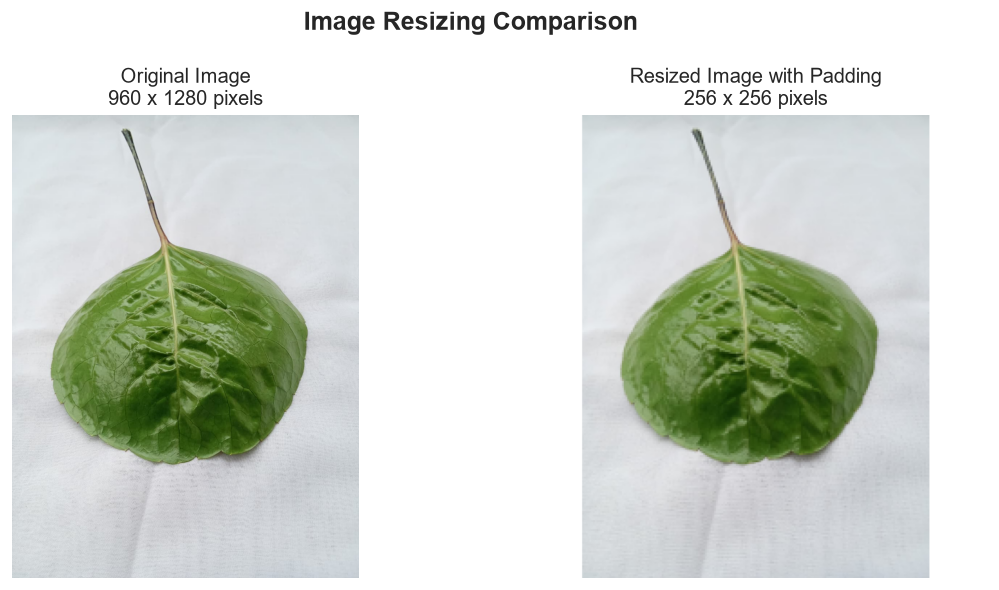


2. RESIZING TEST PER CLASS


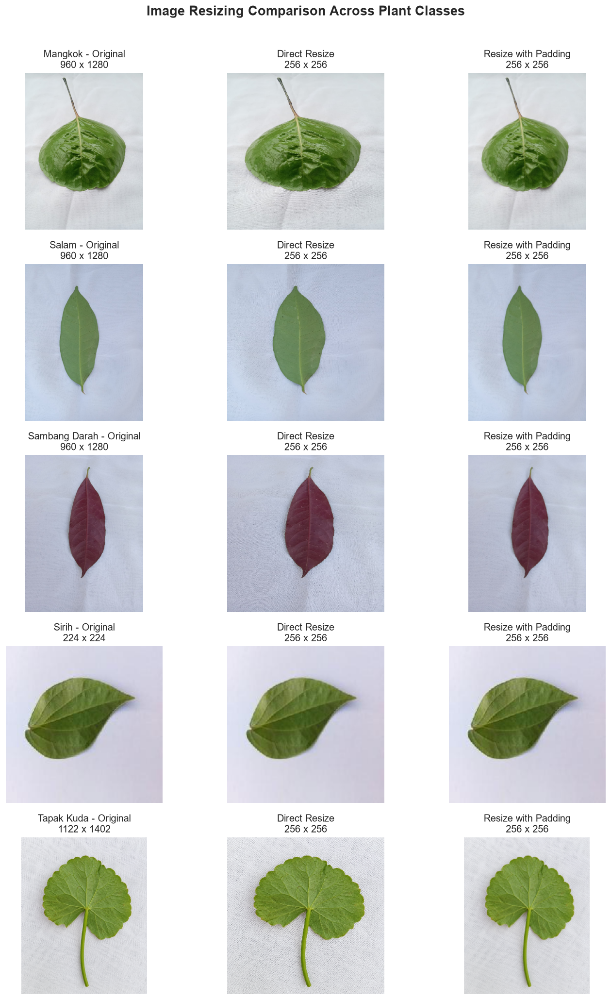


3. RESIZING TEST RESULTS


,kelas,original_width,original_height,resized_width,resized_height,output_width,output_height,scale
0,Mangkok,960,1280,192,256,256,256,0.2000
1,Salam,960,1280,192,256,256,256,0.2000
2,Sambang Darah,960,1280,192,256,256,256,0.2000
3,Sirih,224,224,256,256,256,256,1.1429
4,Tapak Kuda,1122,1402,205,256,256,256,0.1826



4. OUTPUT DIMENSION VALIDATION
Tested images       : 5
Valid output size   : 5
Invalid output size : 0

5. RESIZING SUMMARY
[PASS] All tested images have valid dimensions.
Target image size : (256, 256)
Aspect ratio preservation : Enabled
Padding color : White (255, 255, 255)

Original images have not been modified.
Batch image preprocessing has not been performed.

Image resizing test completed successfully!


In [6]:
# ==================================================
# IMAGE RESIZING WITH ASPECT RATIO PRESERVATION
# ==================================================

print("IMAGE RESIZING WITH ASPECT RATIO PRESERVATION")
print("=" * 60)


# 1. Function to load image in RGB format
def load_image(image_path):

    with Image.open(image_path) as img:

        # Correct image orientation using EXIF metadata
        img = ImageOps.exif_transpose(img)

        # Convert image to RGB
        img = img.convert("RGB")

        image = np.array(img)

    return image


# 2. Function to resize image while preserving aspect ratio
def resize_with_padding(
    image,
    target_size=TARGET_SIZE,
    padding_color=PADDING_COLOR
):

    # Get original image dimensions
    original_height, original_width = image.shape[:2]

    target_width, target_height = target_size

    # Calculate scaling factor
    scale = min(
        target_width / original_width,
        target_height / original_height
    )

    # Calculate new dimensions
    new_width = max(
        1,
        round(original_width * scale)
    )

    new_height = max(
        1,
        round(original_height * scale)
    )

    # Select interpolation method
    if scale < 1:

        interpolation = DOWNSCALE_INTERPOLATION

    else:

        interpolation = UPSCALE_INTERPOLATION

    # Resize image
    resized_image = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=interpolation
    )

    # Calculate padding
    pad_left = (
        target_width - new_width
    ) // 2

    pad_right = (
        target_width - new_width
        - pad_left
    )

    pad_top = (
        target_height - new_height
    ) // 2

    pad_bottom = (
        target_height - new_height
        - pad_top
    )

    # Add padding to reach target dimensions
    padded_image = cv2.copyMakeBorder(
        resized_image,
        pad_top,
        pad_bottom,
        pad_left,
        pad_right,
        borderType=cv2.BORDER_CONSTANT,
        value=padding_color
    )

    # Store resizing information
    resize_info = {
        "original_width": original_width,
        "original_height": original_height,
        "scale": scale,
        "resized_width": new_width,
        "resized_height": new_height,
        "output_width": padded_image.shape[1],
        "output_height": padded_image.shape[0],
        "pad_left": pad_left,
        "pad_right": pad_right,
        "pad_top": pad_top,
        "pad_bottom": pad_bottom
    }

    return padded_image, resize_info


# 3. Test resizing on one sample image
print("\n1. SINGLE IMAGE RESIZING TEST")

sample_row = df_clean.iloc[0]

sample_image = load_image(
    sample_row["absolute_image_path"]
)

sample_resized, sample_resize_info = (
    resize_with_padding(sample_image)
)

print(f"File name : {sample_row['nama_file']}")
print(f"Class     : {sample_row['kelas']}")

display(
    pd.DataFrame(
        sample_resize_info.items(),
        columns=["Parameter", "Value"]
    )
)


# 4. Compare original and resized images
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 5)
)

axes[0].imshow(sample_image)

axes[0].set_title(
    "Original Image\n"
    f"{sample_image.shape[1]} x "
    f"{sample_image.shape[0]} pixels"
)

axes[0].axis("off")


axes[1].imshow(sample_resized)

axes[1].set_title(
    "Resized Image with Padding\n"
    f"{sample_resized.shape[1]} x "
    f"{sample_resized.shape[0]} pixels"
)

axes[1].axis("off")

plt.suptitle(
    "Image Resizing Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_single_image_resizing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 5. Test resizing on samples from every class
print("\n2. RESIZING TEST PER CLASS")

resize_test_records = []

plant_classes = sorted(
    df_clean["kelas"].unique()
)

fig, axes = plt.subplots(
    len(plant_classes),
    3,
    figsize=(12, 3.5 * len(plant_classes)),
    squeeze=False
)

for row_index, plant_class in enumerate(
    plant_classes
):

    # Select one reproducible sample per class
    sample = df_clean[
        df_clean["kelas"].eq(plant_class)
    ].sample(
        n=1,
        random_state=RANDOM_STATE
    ).iloc[0]

    # Load original image
    original_image = load_image(
        sample["absolute_image_path"]
    )

    # Direct resize for comparison only
    direct_resized = cv2.resize(
        original_image,
        TARGET_SIZE,
        interpolation=cv2.INTER_LINEAR
    )

    # Aspect-ratio-preserving resize
    padded_image, resize_info = (
        resize_with_padding(original_image)
    )

    # Store test information
    resize_test_records.append({
        "nama_file": sample["nama_file"],
        "kelas": plant_class,
        **resize_info
    })

    # Original image
    axes[row_index, 0].imshow(
        original_image
    )

    axes[row_index, 0].set_title(
        f"{plant_class} - Original\n"
        f"{original_image.shape[1]} x "
        f"{original_image.shape[0]}"
    )

    # Direct resize
    axes[row_index, 1].imshow(
        direct_resized
    )

    axes[row_index, 1].set_title(
        "Direct Resize\n256 x 256"
    )

    # Resize with padding
    axes[row_index, 2].imshow(
        padded_image
    )

    axes[row_index, 2].set_title(
        "Resize with Padding\n256 x 256"
    )

    for ax in axes[row_index]:

        ax.axis("off")


fig.suptitle(
    "Image Resizing Comparison Across Plant Classes",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    FIGURES_DIR / "09_class_resizing_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 6. Create resizing test results
resize_test_df = pd.DataFrame(
    resize_test_records
)

print("\n3. RESIZING TEST RESULTS")

display(
    resize_test_df[
        [
            "kelas",
            "original_width",
            "original_height",
            "resized_width",
            "resized_height",
            "output_width",
            "output_height",
            "scale"
        ]
    ].round(4)
)


# 7. Validate output dimensions
resize_test_df["valid_output_size"] = (
    resize_test_df["output_width"].eq(
        TARGET_WIDTH
    )
    & resize_test_df["output_height"].eq(
        TARGET_HEIGHT
    )
)

valid_resize_count = int(
    resize_test_df["valid_output_size"].sum()
)

print("\n4. OUTPUT DIMENSION VALIDATION")

print(
    f"Tested images       : "
    f"{len(resize_test_df)}"
)

print(
    f"Valid output size   : "
    f"{valid_resize_count}"
)

print(
    f"Invalid output size : "
    f"{len(resize_test_df) - valid_resize_count}"
)


# 8. Save resizing test results
resize_test_df.to_csv(
    METRICS_DIR / "24_image_resizing_test.csv",
    index=False
)


# 9. Final summary
print("\n5. RESIZING SUMMARY")
print("=" * 60)

if resize_test_df["valid_output_size"].all():

    print("[PASS] All tested images have valid dimensions.")

else:

    print("[WARNING] Some images have invalid dimensions.")

print(f"Target image size : {TARGET_SIZE}")
print("Aspect ratio preservation : Enabled")
print("Padding color : White (255, 255, 255)")

print("\nOriginal images have not been modified.")
print("Batch image preprocessing has not been performed.")

print("\nImage resizing test completed successfully!")

LEAF SEGMENTATION

1. SINGLE IMAGE SEGMENTATION TEST
File name : mangkok 10.jpeg
Class     : Mangkok


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


,Parameter,Value
0,selected_method,HSV Thresholding
1,foreground_ratio,0.196365
2,valid_region_ratio,0.26182
3,border_ratio,0.0
4,quality_score,0.971773
5,quality_status,Passed Initial Check



2. SEGMENTATION METHOD COMPARISON


,Method,Foreground Ratio,Valid Region Ratio,Border Ratio,Quality Score,Quality Status,Selected
0,HSV Thresholding,0.1964,0.2618,0.0,0.9718,Passed Initial Check,True
1,Otsu Dark Foreground,0.1907,0.2543,0.0,0.9706,Passed Initial Check,False
2,Otsu Light Foreground,0.5552,0.7402,1.0,0.2565,Needs Review,False
3,GrabCut,0.7500,1.0000,1.0,-0.5825,Needs Review,False


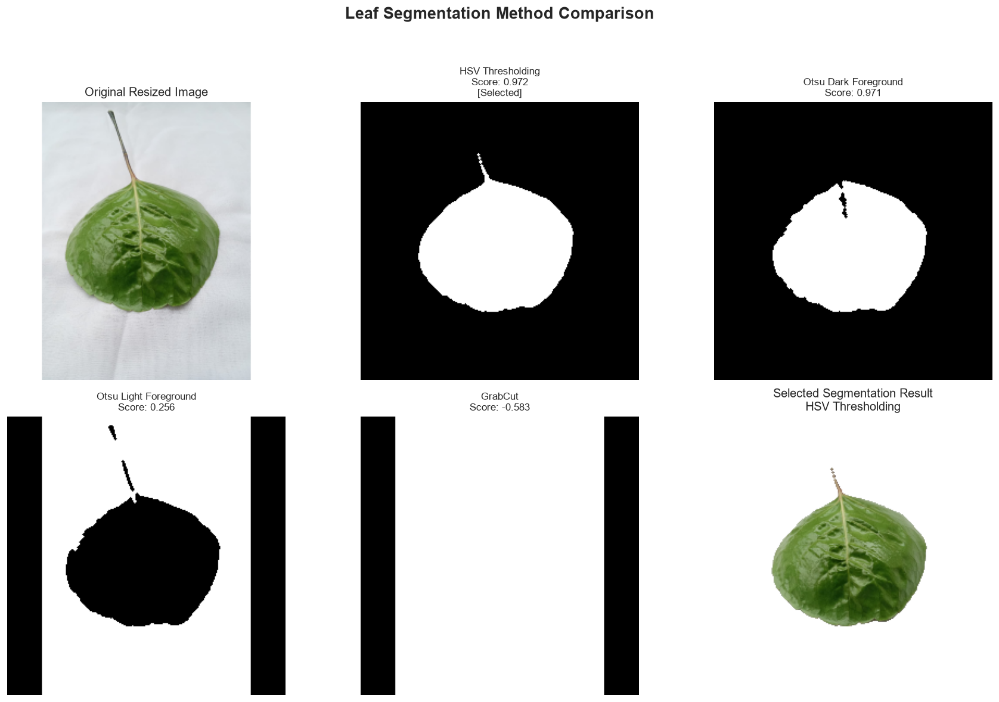


3. SEGMENTATION TEST PER CLASS


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


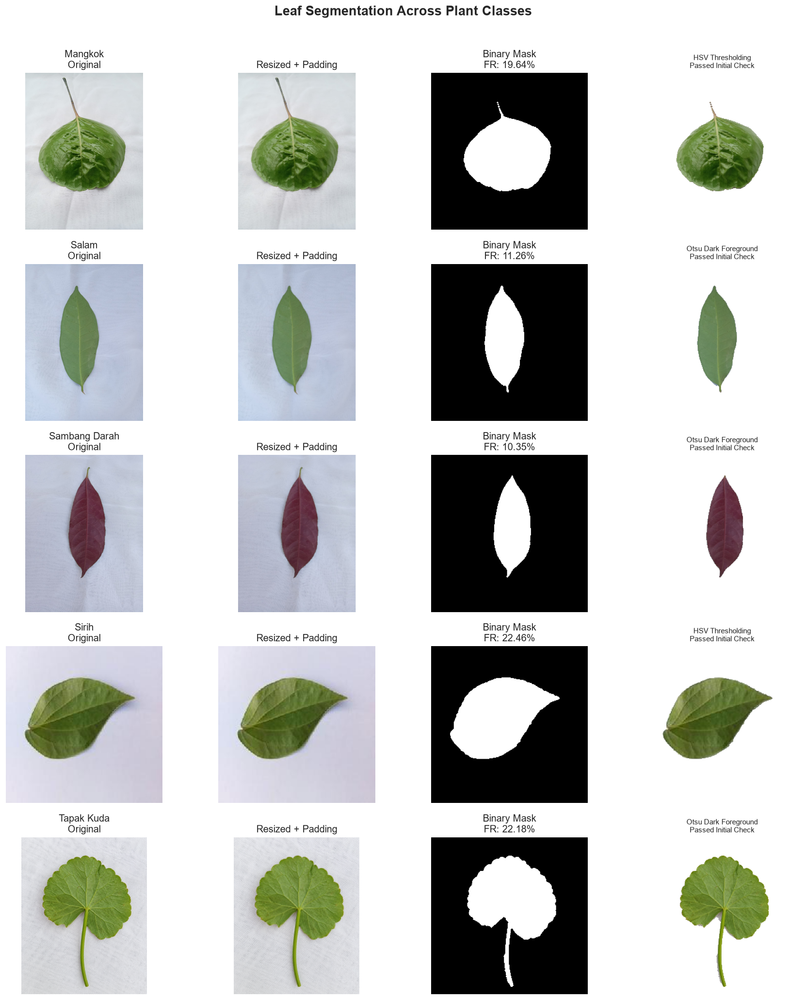


4. SEGMENTATION TEST RESULTS


,nama_file,kelas,selected_method,foreground_ratio,valid_region_ratio,border_ratio,quality_score,quality_status
0,mangkok 10.jpeg,Mangkok,HSV Thresholding,0.1964,0.2618,0.0,0.9718,Passed Initial Check
1,daun salam 10.jpeg,Salam,Otsu Dark Foreground,0.1126,0.1501,0.0,0.9550,Passed Initial Check
2,sambang darah 10.jpeg,Sambang Darah,Otsu Dark Foreground,0.1035,0.1380,0.0,0.9532,Passed Initial Check
3,Hijau_Sehat1.jpg,Sirih,HSV Thresholding,0.2246,0.2246,0.0,0.9662,Passed Initial Check
4,tapak kuda 19.png,Tapak Kuda,Otsu Dark Foreground,0.2218,0.2769,0.0,0.9740,Passed Initial Check



5. SEGMENTATION SUMMARY
Tested images        : 5
Passed initial check : 5
Needs review         : 0
Failed segmentation  : 0

Selected segmentation methods:


,Count
selected_method,
Otsu Dark Foreground,3
HSV Thresholding,2



[INFO] Visual inspection is required.
[INFO] Original images have not been modified.
[INFO] Batch segmentation has not been performed.

Leaf segmentation test completed!


In [7]:
# ==================================================
# LEAF SEGMENTATION
# ==================================================

print("LEAF SEGMENTATION")
print("=" * 60)


# ==================================================
# 1. CREATE VALID IMAGE REGION
# ==================================================

def create_valid_region(image, resize_info=None):

    height, width = image.shape[:2]

    valid_region = np.full(
        (height, width),
        255,
        dtype=np.uint8
    )

    # Exclude artificial padding
    if resize_info is not None:

        valid_region[:] = 0

        x1 = resize_info["pad_left"]
        y1 = resize_info["pad_top"]

        x2 = x1 + resize_info["resized_width"]
        y2 = y1 + resize_info["resized_height"]

        valid_region[y1:y2, x1:x2] = 255

    return valid_region


# ==================================================
# 2. HSV THRESHOLDING
# ==================================================

def segment_hsv(image, valid_region):

    # Convert RGB image to HSV
    hsv = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2HSV
    )

    # Green and yellow-green leaves
    green_mask = cv2.inRange(
        hsv,
        np.array([20, 30, 25]),
        np.array([100, 255, 255])
    )

    # Red leaves: lower hue range
    red_mask_1 = cv2.inRange(
        hsv,
        np.array([0, 35, 25]),
        np.array([20, 255, 255])
    )

    # Red and purple leaves: upper hue range
    red_mask_2 = cv2.inRange(
        hsv,
        np.array([125, 30, 20]),
        np.array([179, 255, 255])
    )

    # Combine color masks
    mask = cv2.bitwise_or(
        green_mask,
        red_mask_1
    )

    mask = cv2.bitwise_or(
        mask,
        red_mask_2
    )

    # Exclude padding
    mask = cv2.bitwise_and(
        mask,
        valid_region
    )

    return mask


# ==================================================
# 3. OTSU THRESHOLDING
# ==================================================

def segment_otsu(image, valid_region):

    # Convert RGB to grayscale
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    # Extract pixel values from the original image region
    valid_pixels = gray[valid_region > 0]

    if valid_pixels.size == 0:

        return np.zeros_like(gray)

    # Calculate Otsu threshold without padding
    threshold, _ = cv2.threshold(
        valid_pixels.reshape(-1, 1),
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Generate both foreground possibilities
    _, dark_mask = cv2.threshold(
        gray,
        threshold,
        255,
        cv2.THRESH_BINARY_INV
    )

    _, light_mask = cv2.threshold(
        gray,
        threshold,
        255,
        cv2.THRESH_BINARY
    )

    dark_mask = cv2.bitwise_and(
        dark_mask,
        valid_region
    )

    light_mask = cv2.bitwise_and(
        light_mask,
        valid_region
    )

    return dark_mask, light_mask


# ==================================================
# 4. GRABCUT SEGMENTATION
# ==================================================

def segment_grabcut(image, valid_region):

    height, width = image.shape[:2]

    # Convert RGB to BGR for OpenCV
    image_bgr = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2BGR
    )

    # Initialize GrabCut mask
    grabcut_mask = np.full(
        (height, width),
        cv2.GC_BGD,
        dtype=np.uint8
    )

    # Define valid image region
    ys, xs = np.where(valid_region > 0)

    if len(xs) == 0:

        return np.zeros(
            (height, width),
            dtype=np.uint8
        )

    x1, x2 = xs.min(), xs.max() + 1
    y1, y2 = ys.min(), ys.max() + 1

    region_width = x2 - x1
    region_height = y2 - y1

    margin_x = max(1, int(region_width * 0.03))
    margin_y = max(1, int(region_height * 0.03))

    # Mark original image region as probable background
    grabcut_mask[y1:y2, x1:x2] = cv2.GC_PR_BGD

    # Mark inner region as probable foreground
    grabcut_mask[
        y1 + margin_y:y2 - margin_y,
        x1 + margin_x:x2 - margin_x
    ] = cv2.GC_PR_FGD

    # Initialize background and foreground models
    bg_model = np.zeros(
        (1, 65),
        dtype=np.float64
    )

    fg_model = np.zeros(
        (1, 65),
        dtype=np.float64
    )

    try:

        cv2.setRNGSeed(RANDOM_STATE)

        cv2.grabCut(
            image_bgr,
            grabcut_mask,
            None,
            bg_model,
            fg_model,
            5,
            cv2.GC_INIT_WITH_MASK
        )

        # Convert GrabCut labels to binary mask
        mask = np.where(
            (
                grabcut_mask == cv2.GC_FGD
            ) | (
                grabcut_mask == cv2.GC_PR_FGD
            ),
            255,
            0
        ).astype(np.uint8)

        return cv2.bitwise_and(
            mask,
            valid_region
        )

    except cv2.error:

        return np.zeros(
            (height, width),
            dtype=np.uint8
        )


# ==================================================
# 5. CLEAN BINARY MASK
# ==================================================

def clean_binary_mask(mask, valid_region):

    # Ensure binary pixel values
    mask = np.where(
        mask > 0,
        255,
        0
    ).astype(np.uint8)

    # Morphological opening
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        MORPH_KERNEL,
        iterations=OPENING_ITERATIONS
    )

    # Morphological closing
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        MORPH_KERNEL,
        iterations=CLOSING_ITERATIONS
    )

    # Remove padding area
    mask = cv2.bitwise_and(
        mask,
        valid_region
    )

    # Keep the largest connected component
    if KEEP_LARGEST_COMPONENT:

        num_labels, labels, stats, _ = (
            cv2.connectedComponentsWithStats(
                mask,
                connectivity=8
            )
        )

        if num_labels > 1:

            largest_label = 1 + np.argmax(
                stats[1:, cv2.CC_STAT_AREA]
            )

            mask = np.where(
                labels == largest_label,
                255,
                0
            ).astype(np.uint8)

    # Fill small internal holes
    mask = morphology.remove_small_holes(
        mask.astype(bool),
        area_threshold=32
    ).astype(np.uint8) * 255

    # Ensure padding remains excluded
    mask = cv2.bitwise_and(
        mask,
        valid_region
    )

    return mask


# ==================================================
# 6. SEGMENTATION QUALITY SCORING
# ==================================================

def calculate_mask_quality(mask, valid_region):

    foreground_pixels = np.count_nonzero(mask)

    valid_pixels = np.count_nonzero(
        valid_region
    )

    if foreground_pixels == 0 or valid_pixels == 0:

        return {
            "foreground_ratio": 0.0,
            "valid_region_ratio": 0.0,
            "border_ratio": 0.0,
            "quality_score": -1.0,
            "quality_status": "Failed"
        }

    # Foreground ratio relative to the full image
    foreground_ratio = (
        foreground_pixels / mask.size
    )

    # Foreground ratio relative to non-padding area
    valid_region_ratio = (
        foreground_pixels / valid_pixels
    )

    # Identify border of the valid image region
    eroded_region = cv2.erode(
        valid_region,
        np.ones((5, 5), dtype=np.uint8),
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    border_region = cv2.subtract(
        valid_region,
        eroded_region
    )

    border_foreground = np.count_nonzero(
        cv2.bitwise_and(
            mask,
            border_region
        )
    )

    border_pixels = np.count_nonzero(
        border_region
    )

    border_ratio = (
        border_foreground / max(border_pixels, 1)
    )

    # Initial heuristic score
    quality_score = 1.0

    # Penalize masks outside the expected size range
    if foreground_ratio < MIN_FOREGROUND_RATIO:

        quality_score -= 0.8

    if foreground_ratio > MAX_FOREGROUND_RATIO:

        quality_score -= 0.8

    # Penalize masks covering almost the entire source image
    if valid_region_ratio > 0.95:

        quality_score -= 0.8

    # Penalize excessive foreground touching image borders
    quality_score -= 0.7 * border_ratio

    # Mild preference for a reasonable foreground area
    quality_score -= 0.15 * abs(
        valid_region_ratio - 0.45
    )

    # Initial quality status
    if (
        MIN_FOREGROUND_RATIO
        <= foreground_ratio
        <= MAX_FOREGROUND_RATIO
        and valid_region_ratio <= 0.95
        and border_ratio <= 0.35
    ):

        quality_status = "Passed Initial Check"

    else:

        quality_status = "Needs Review"

    return {
        "foreground_ratio": float(foreground_ratio),
        "valid_region_ratio": float(valid_region_ratio),
        "border_ratio": float(border_ratio),
        "quality_score": float(quality_score),
        "quality_status": quality_status
    }


# ==================================================
# 7. ADAPTIVE SEGMENTATION SELECTION
# ==================================================

def segment_leaf(image, resize_info=None):

    valid_region = create_valid_region(
        image,
        resize_info
    )

    # Generate candidate masks
    otsu_dark, otsu_light = segment_otsu(
        image,
        valid_region
    )

    candidate_masks = {
        "HSV Thresholding": segment_hsv(
            image,
            valid_region
        ),

        "Otsu Dark Foreground": otsu_dark,

        "Otsu Light Foreground": otsu_light,

        "GrabCut": segment_grabcut(
            image,
            valid_region
        )
    }

    segmentation_results = {}

    # Clean and evaluate each candidate
    for method, mask in candidate_masks.items():

        cleaned_mask = clean_binary_mask(
            mask,
            valid_region
        )

        quality = calculate_mask_quality(
            cleaned_mask,
            valid_region
        )

        segmentation_results[method] = {
            "mask": cleaned_mask,
            **quality
        }

    # Prefer candidates passing the initial checks
    passed_methods = [
        method
        for method, result
        in segmentation_results.items()
        if result["quality_status"]
        == "Passed Initial Check"
    ]

    available_methods = (
        passed_methods
        if passed_methods
        else list(segmentation_results.keys())
    )

    # Select the highest heuristic score
    best_method = max(
        available_methods,
        key=lambda method: (
            segmentation_results[method]["quality_score"]
        )
    )

    best_result = segmentation_results[
        best_method
    ]

    best_mask = best_result["mask"]

    # Create segmented RGB image
    segmented_image = np.full_like(
        image,
        255
    )

    segmented_image[best_mask > 0] = (
        image[best_mask > 0]
    )

    segmentation_info = {
        "selected_method": best_method,
        "foreground_ratio": best_result[
            "foreground_ratio"
        ],
        "valid_region_ratio": best_result[
            "valid_region_ratio"
        ],
        "border_ratio": best_result[
            "border_ratio"
        ],
        "quality_score": best_result[
            "quality_score"
        ],
        "quality_status": best_result[
            "quality_status"
        ]
    }

    return (
        segmented_image,
        best_mask,
        segmentation_info,
        segmentation_results
    )


# ==================================================
# 8. SINGLE IMAGE SEGMENTATION TEST
# ==================================================

print("\n1. SINGLE IMAGE SEGMENTATION TEST")

sample_row = df_clean.iloc[0]

original_image = load_image(
    sample_row["absolute_image_path"]
)

resized_image, resize_info = (
    resize_with_padding(original_image)
)

(
    segmented_image,
    best_mask,
    segmentation_info,
    segmentation_results
) = segment_leaf(
    resized_image,
    resize_info
)

print(f"File name : {sample_row['nama_file']}")
print(f"Class     : {sample_row['kelas']}")

display(
    pd.DataFrame(
        segmentation_info.items(),
        columns=["Parameter", "Value"]
    )
)


# ==================================================
# 9. COMPARE SEGMENTATION METHODS
# ==================================================

print("\n2. SEGMENTATION METHOD COMPARISON")

comparison_records = []

for method, result in segmentation_results.items():

    comparison_records.append({
        "Method": method,
        "Foreground Ratio": result[
            "foreground_ratio"
        ],
        "Valid Region Ratio": result[
            "valid_region_ratio"
        ],
        "Border Ratio": result[
            "border_ratio"
        ],
        "Quality Score": result[
            "quality_score"
        ],
        "Quality Status": result[
            "quality_status"
        ],
        "Selected": method == segmentation_info[
            "selected_method"
        ]
    })

comparison_df = pd.DataFrame(
    comparison_records
)

display(
    comparison_df.round(4)
)


# ==================================================
# 10. VISUALIZE SEGMENTATION COMPARISON
# ==================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10)
)

axes = axes.ravel()

# Original resized image
axes[0].imshow(resized_image)

axes[0].set_title(
    "Original Resized Image"
)

# Candidate masks
for index, (method, result) in enumerate(
    segmentation_results.items(),
    start=1
):

    axes[index].imshow(
        result["mask"],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    selected = (
        "\n[Selected]"
        if method == segmentation_info["selected_method"]
        else ""
    )

    axes[index].set_title(
        f"{method}\n"
        f"Score: {result['quality_score']:.3f}"
        f"{selected}",
        fontsize=10
    )

# Final segmented image
axes[5].imshow(segmented_image)

axes[5].set_title(
    "Selected Segmentation Result\n"
    f"{segmentation_info['selected_method']}"
)

for ax in axes:

    ax.axis("off")

fig.suptitle(
    "Leaf Segmentation Method Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURES_DIR / "10_segmentation_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# 11. TEST SEGMENTATION ACROSS PLANT CLASSES
# ==================================================

print("\n3. SEGMENTATION TEST PER CLASS")

segmentation_test_records = []

plant_classes = sorted(
    df_clean["kelas"].unique()
)

fig, axes = plt.subplots(
    len(plant_classes),
    4,
    figsize=(15, 3.5 * len(plant_classes)),
    squeeze=False
)

for row_index, plant_class in enumerate(
    plant_classes
):

    sample = df_clean[
        df_clean["kelas"].eq(plant_class)
    ].sample(
        n=1,
        random_state=RANDOM_STATE
    ).iloc[0]

    # Load original image
    original = load_image(
        sample["absolute_image_path"]
    )

    # Resize image
    resized, info = resize_with_padding(
        original
    )

    # Perform segmentation
    (
        segmented,
        mask,
        seg_info,
        _
    ) = segment_leaf(
        resized,
        info
    )

    # Store segmentation results
    segmentation_test_records.append({
        "nama_file": sample["nama_file"],
        "kelas": plant_class,
        **seg_info
    })

    # Original image
    axes[row_index, 0].imshow(original)

    axes[row_index, 0].set_title(
        f"{plant_class}\nOriginal"
    )

    # Resized image
    axes[row_index, 1].imshow(resized)

    axes[row_index, 1].set_title(
        "Resized + Padding"
    )

    # Binary mask
    axes[row_index, 2].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[row_index, 2].set_title(
        "Binary Mask\n"
        f"FR: {seg_info['foreground_ratio']:.2%}"
    )

    # Segmented image
    axes[row_index, 3].imshow(segmented)

    axes[row_index, 3].set_title(
        f"{seg_info['selected_method']}\n"
        f"{seg_info['quality_status']}",
        fontsize=9
    )

    for ax in axes[row_index]:

        ax.axis("off")

fig.suptitle(
    "Leaf Segmentation Across Plant Classes",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    FIGURES_DIR / "11_class_segmentation_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# 12. DISPLAY SEGMENTATION TEST RESULTS
# ==================================================

segmentation_test_df = pd.DataFrame(
    segmentation_test_records
)

print("\n4. SEGMENTATION TEST RESULTS")

display(
    segmentation_test_df.round(4)
)


# ==================================================
# 13. SAVE SEGMENTATION TEST RESULTS
# ==================================================

comparison_df.to_csv(
    METRICS_DIR / "25_segmentation_method_comparison.csv",
    index=False
)

segmentation_test_df.to_csv(
    METRICS_DIR / "26_segmentation_test_results.csv",
    index=False
)


# ==================================================
# 14. FINAL SEGMENTATION SUMMARY
# ==================================================

print("\n5. SEGMENTATION SUMMARY")
print("=" * 60)

passed_count = int(
    segmentation_test_df["quality_status"]
    .eq("Passed Initial Check")
    .sum()
)

review_count = int(
    segmentation_test_df["quality_status"]
    .eq("Needs Review")
    .sum()
)

failed_count = int(
    segmentation_test_df["quality_status"]
    .eq("Failed")
    .sum()
)

print(f"Tested images        : {len(segmentation_test_df)}")
print(f"Passed initial check : {passed_count}")
print(f"Needs review         : {review_count}")
print(f"Failed segmentation  : {failed_count}")

print("\nSelected segmentation methods:")

display(
    segmentation_test_df[
        "selected_method"
    ].value_counts().to_frame("Count")
)

print("\n[INFO] Visual inspection is required.")
print("[INFO] Original images have not been modified.")
print("[INFO] Batch segmentation has not been performed.")

print("\nLeaf segmentation test completed!")

IMAGE QUALITY INSPECTION

1. INSPECTING ALL CANDIDATE IMAGES


Inspecting images:   0%|          | 0/104 [00:00<?, ?it/s]

C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(



2. IMAGE QUALITY STATISTICS


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


,blur_score,mean_brightness,contrast,foreground_ratio,border_ratio,quality_score
count,104.0000,104.0000,104.0000,104.0000,104.0000,104.0000
mean,381.6591,99.7191,18.6599,0.2226,0.0501,0.8985
std,270.1487,28.2553,7.1000,0.1500,0.2137,0.2208
min,21.8187,45.2696,5.3068,0.0088,0.0000,0.1343
25%,183.1186,80.5388,13.4619,0.1171,0.0000,0.9510
50%,333.8176,96.0227,18.1147,0.2043,0.0000,0.9642
75%,504.5760,116.4709,24.3213,0.2620,0.0000,0.9752
max,1430.5121,198.9177,35.9719,0.7116,1.0000,0.9994


... (6 outputs left out)


6. IMAGE QUALITY PER CLASS


inspection_status,Passed Initial Check,Needs Review,Failed
kelas,,,
Mangkok,19,1,0
Salam,9,10,0
Sambang Darah,7,13,0
Sirih,15,5,0
Tapak Kuda,14,11,0



7. IMAGES REQUIRING INSPECTION


,nama_file,kelas,selected_method,blur_score,mean_brightness,contrast,foreground_ratio,inspection_status,quality_issues
7,mangkok 7.jpeg,Mangkok,HSV Thresholding,480.3876,101.2649,14.9378,0.0670,Needs Review,Low contrast
20,daun salam 10.jpeg,Salam,Otsu Dark Foreground,88.9498,118.9530,7.3613,0.1126,Needs Review,Potential blur; Low contrast
24,daun salam 14.png,Salam,Otsu Dark Foreground,393.9646,114.0834,13.5115,0.1772,Needs Review,Low contrast
26,daun salam 6.jpeg,Salam,Otsu Dark Foreground,21.8187,153.1421,5.3068,0.0672,Needs Review,Potential blur; Low contrast
27,daun salam 7.jpeg,Salam,HSV Thresholding,94.6966,103.4401,10.4761,0.1510,Needs Review,Potential blur; Low contrast
28,daun salam 9.jpeg,Salam,Otsu Light Foreground,26.8630,175.7482,11.3314,0.7072,Needs Review,Segmentation requires review; Potential blur; ...
29,daun salam 1.jpeg,Salam,Otsu Dark Foreground,99.4860,71.5111,9.1249,0.0970,Needs Review,Potential blur; Low contrast
31,daun salam 2.jpeg,Salam,HSV Thresholding,76.5766,72.4079,9.3742,0.0350,Needs Review,Segmentation requires review; Potential blur; ...
32,daun salam 3.jpeg,Salam,Otsu Dark Foreground,78.7764,79.5020,9.6953,0.0656,Needs Review,Potential blur; Low contrast
33,daun salam 4.jpeg,Salam,Otsu Dark Foreground,82.2474,75.9435,9.6190,0.0964,Needs Review,Potential blur; Low contrast


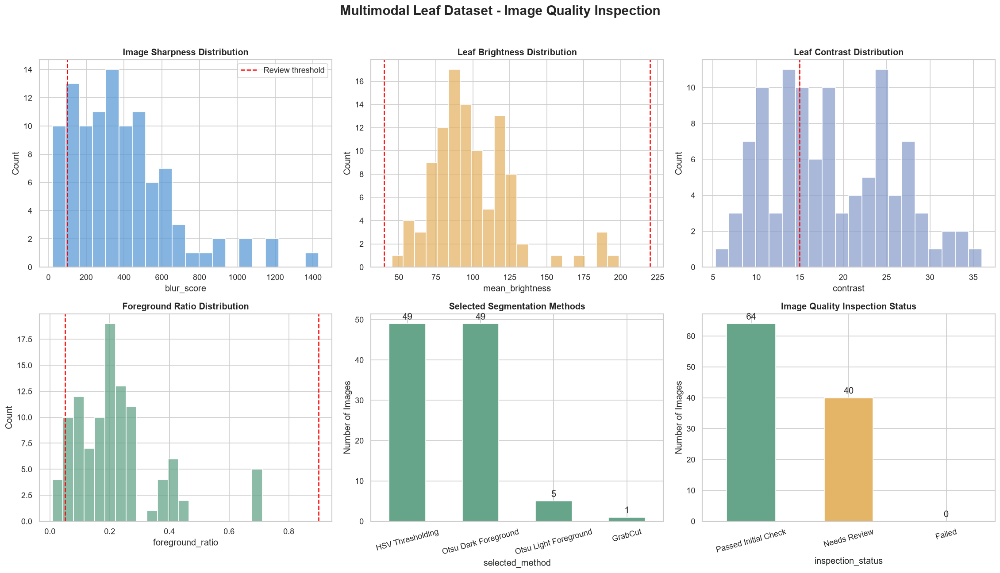


8. FINAL IMAGE QUALITY SUMMARY
Total inspected images : 104
Passed initial check   : 64
Needs review           : 40
Failed inspections     : 0
Potentially blurry     : 13
Low brightness         : 0
High brightness        : 0
Low contrast           : 40

Selected segmentation methods:


,Number of Images
selected_method,
HSV Thresholding,49
Otsu Dark Foreground,49
Otsu Light Foreground,5
GrabCut,1



[REVIEW] Some images require manual visual inspection.

Original dataset has not been modified.
Processed images have not been saved permanently.

Image quality inspection completed successfully!


In [8]:
# ==================================================
# IMAGE QUALITY INSPECTION
# ==================================================

print("IMAGE QUALITY INSPECTION")
print("=" * 60)


# ==================================================
# 1. QUALITY INSPECTION CONFIGURATION
# ==================================================

# Initial inspection thresholds
BLUR_THRESHOLD = 100.0

MIN_BRIGHTNESS = 40
MAX_BRIGHTNESS = 220

MIN_CONTRAST = 15.0

MAX_BORDER_RATIO = 0.35

MIN_MASK_PIXELS = 100


# ==================================================
# 2. CALCULATE IMAGE QUALITY
# ==================================================

def calculate_image_quality(image, mask):

    # Convert RGB image to grayscale
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    # Extract foreground pixels
    foreground_pixels = gray[mask > 0]

    foreground_count = len(
        foreground_pixels
    )

    # Handle empty or insufficient masks
    if foreground_count < MIN_MASK_PIXELS:

        return {
            "blur_score": np.nan,
            "mean_brightness": np.nan,
            "contrast": np.nan,
            "foreground_pixels": foreground_count,
            "is_blurry": False,
            "is_dark": False,
            "is_bright": False,
            "is_low_contrast": False,
            "quality_measurable": False
        }

    # Erode mask to exclude object boundaries
    inner_mask = cv2.erode(
        mask,
        np.ones((3, 3), dtype=np.uint8),
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    # Calculate Laplacian response
    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_64F
    )

    # Measure sharpness inside the leaf area
    laplacian_pixels = laplacian[
        inner_mask > 0
    ]

    if laplacian_pixels.size >= MIN_MASK_PIXELS:

        blur_score = float(
            laplacian_pixels.var()
        )

    else:

        blur_score = np.nan

    # Calculate mean brightness
    mean_brightness = float(
        foreground_pixels.mean()
    )

    # Calculate image contrast
    contrast = float(
        foreground_pixels.std()
    )

    # Identify potential quality issues
    is_blurry = (
        pd.notna(blur_score)
        and blur_score < BLUR_THRESHOLD
    )

    is_dark = (
        mean_brightness < MIN_BRIGHTNESS
    )

    is_bright = (
        mean_brightness > MAX_BRIGHTNESS
    )

    is_low_contrast = (
        contrast < MIN_CONTRAST
    )

    return {
        "blur_score": blur_score,
        "mean_brightness": mean_brightness,
        "contrast": contrast,
        "foreground_pixels": foreground_count,
        "is_blurry": is_blurry,
        "is_dark": is_dark,
        "is_bright": is_bright,
        "is_low_contrast": is_low_contrast,
        "quality_measurable": pd.notna(blur_score)
    }


# ==================================================
# 3. INSPECT INDIVIDUAL IMAGE
# ==================================================

def inspect_image(row):

    # Load original RGB image
    original_image = load_image(
        row["absolute_image_path"]
    )

    # Optional noise filtering
    if APPLY_DENOISING:

        original_image = cv2.medianBlur(
            original_image,
            MEDIAN_KERNEL_SIZE
        )

    # Resize with aspect ratio preservation
    resized_image, resize_info = (
        resize_with_padding(original_image)
    )

    # Perform adaptive leaf segmentation
    (
        segmented_image,
        mask,
        segmentation_info,
        _
    ) = segment_leaf(
        resized_image,
        resize_info
    )

    # Calculate image quality
    image_quality = calculate_image_quality(
        resized_image,
        mask
    )

    # Check output dimensions
    valid_dimensions = (
        resized_image.shape[:2]
        == (TARGET_HEIGHT, TARGET_WIDTH)
    )

    # Check binary mask values
    unique_mask_values = np.unique(mask)

    valid_binary_mask = set(
        unique_mask_values
    ).issubset({0, 255})

    # Check mask dimensions
    valid_mask_dimensions = (
        mask.shape
        == (TARGET_HEIGHT, TARGET_WIDTH)
    )

    # Identify segmentation issues
    segmentation_failed = (
        segmentation_info["quality_status"]
        == "Failed"
        or image_quality["foreground_pixels"]
        < MIN_MASK_PIXELS
    )

    segmentation_needs_review = (
        segmentation_info["quality_status"]
        != "Passed Initial Check"
        or segmentation_info["border_ratio"]
        > MAX_BORDER_RATIO
    )

    # Collect quality issues
    quality_issues = []

    if not valid_dimensions:

        quality_issues.append(
            "Invalid image dimensions"
        )

    if not valid_binary_mask:

        quality_issues.append(
            "Invalid binary mask"
        )

    if not valid_mask_dimensions:

        quality_issues.append(
            "Invalid mask dimensions"
        )

    if segmentation_failed:

        quality_issues.append(
            "Segmentation failed"
        )

    elif segmentation_needs_review:

        quality_issues.append(
            "Segmentation requires review"
        )

    if not image_quality["quality_measurable"]:

        quality_issues.append(
            "Insufficient pixels for quality measurement"
        )

    if image_quality["is_blurry"]:

        quality_issues.append(
            "Potential blur"
        )

    if image_quality["is_dark"]:

        quality_issues.append(
            "Low brightness"
        )

    if image_quality["is_bright"]:

        quality_issues.append(
            "High brightness"
        )

    if image_quality["is_low_contrast"]:

        quality_issues.append(
            "Low contrast"
        )

    # Determine image inspection status
    if (
        not valid_dimensions
        or not valid_binary_mask
        or not valid_mask_dimensions
        or segmentation_failed
    ):

        inspection_status = "Failed"

    elif quality_issues:

        inspection_status = "Needs Review"

    else:

        inspection_status = "Passed Initial Check"

    # Return inspection results
    return {
        "nama_file": row["nama_file"],
        "image_path": row["image_path"],
        "kelas": row["kelas"],
        "tampilan_daun": row["tampilan_daun"],

        **segmentation_info,
        **image_quality,

        "valid_dimensions": valid_dimensions,
        "valid_binary_mask": valid_binary_mask,
        "valid_mask_dimensions": valid_mask_dimensions,

        "segmentation_failed": segmentation_failed,

        "inspection_status": inspection_status,

        "quality_issues": (
            "; ".join(quality_issues)
            if quality_issues
            else "None"
        )
    }


# ==================================================
# 4. INSPECT ENTIRE DATASET
# ==================================================

print("\n1. INSPECTING ALL CANDIDATE IMAGES")

inspection_records = []

for _, row in tqdm(
    df_clean.iterrows(),
    total=len(df_clean),
    desc="Inspecting images"
):

    try:

        inspection_result = inspect_image(row)

    except Exception as error:

        inspection_result = {
            "nama_file": row["nama_file"],
            "image_path": row["image_path"],
            "kelas": row["kelas"],
            "tampilan_daun": row["tampilan_daun"],
            "inspection_status": "Failed",
            "quality_issues": str(error)
        }

    inspection_records.append(
        inspection_result
    )


# Convert inspection results to DataFrame
image_quality_df = pd.DataFrame(
    inspection_records
)

# Ensure expected columns remain available
# even if some inspection processes fail
numeric_columns = [
    "blur_score",
    "mean_brightness",
    "contrast",
    "foreground_ratio",
    "valid_region_ratio",
    "border_ratio",
    "quality_score",
    "foreground_pixels"
]

boolean_columns = [
    "is_blurry",
    "is_dark",
    "is_bright",
    "is_low_contrast",
    "segmentation_failed"
]

for column in numeric_columns:

    if column not in image_quality_df.columns:

        image_quality_df[column] = np.nan

for column in boolean_columns:

    if column not in image_quality_df.columns:

        image_quality_df[column] = False

if "selected_method" not in image_quality_df.columns:

    image_quality_df["selected_method"] = pd.NA


# ==================================================
# 5. IMAGE QUALITY STATISTICS
# ==================================================

print("\n2. IMAGE QUALITY STATISTICS")

quality_statistics = image_quality_df[
    [
        "blur_score",
        "mean_brightness",
        "contrast",
        "foreground_ratio",
        "border_ratio",
        "quality_score"
    ]
].describe().round(4)

display(quality_statistics)


# ==================================================
# 6. SEGMENTATION METHOD DISTRIBUTION
# ==================================================

print("\n3. SEGMENTATION METHOD DISTRIBUTION")

method_distribution = (
    image_quality_df["selected_method"]
    .value_counts()
    .to_frame("Number of Images")
)

display(method_distribution)


# ==================================================
# 7. INSPECTION STATUS SUMMARY
# ==================================================

print("\n4. IMAGE QUALITY STATUS")

inspection_counts = (
    image_quality_df["inspection_status"]
    .value_counts()
    .reindex(
        [
            "Passed Initial Check",
            "Needs Review",
            "Failed"
        ],
        fill_value=0
    )
)

inspection_summary = pd.DataFrame({
    "Number of Images": inspection_counts,

    "Percentage (%)": (
        inspection_counts
        / len(image_quality_df)
        * 100
    ).round(2)
})

display(inspection_summary)


# ==================================================
# 8. QUALITY ISSUE SUMMARY
# ==================================================

def count_quality_flag(column):

    return int(
        image_quality_df[column]
        .eq(True)
        .sum()
    )


quality_issue_summary = pd.DataFrame({
    "Quality Indicator": [
        "Total inspected images",
        "Potentially blurry images",
        "Low brightness images",
        "High brightness images",
        "Low contrast images",
        "Foreground ratio below minimum",
        "Foreground ratio above maximum",
        "Excessive border ratio",
        "Segmentation failures",
        "Images requiring review",
        "Failed inspections"
    ],

    "Count": [
        len(image_quality_df),

        count_quality_flag("is_blurry"),

        count_quality_flag("is_dark"),

        count_quality_flag("is_bright"),

        count_quality_flag("is_low_contrast"),

        image_quality_df["foreground_ratio"]
        .lt(MIN_FOREGROUND_RATIO).sum(),

        image_quality_df["foreground_ratio"]
        .gt(MAX_FOREGROUND_RATIO).sum(),

        image_quality_df["border_ratio"]
        .gt(MAX_BORDER_RATIO).sum(),

        count_quality_flag("segmentation_failed"),

        inspection_counts["Needs Review"],

        inspection_counts["Failed"]
    ]
})

print("\n5. QUALITY ISSUE SUMMARY")

display(quality_issue_summary)


# ==================================================
# 9. ANALYZE QUALITY PER CLASS
# ==================================================

print("\n6. IMAGE QUALITY PER CLASS")

class_quality_summary = pd.crosstab(
    image_quality_df["kelas"],
    image_quality_df["inspection_status"]
).reindex(
    columns=[
        "Passed Initial Check",
        "Needs Review",
        "Failed"
    ],
    fill_value=0
)

display(class_quality_summary)


# ==================================================
# 10. DISPLAY PROBLEMATIC IMAGES
# ==================================================

print("\n7. IMAGES REQUIRING INSPECTION")

quality_review_df = image_quality_df[
    image_quality_df["inspection_status"]
    .ne("Passed Initial Check")
].copy()

if quality_review_df.empty:

    print(
        "[OK] No image quality issues detected "
        "by the initial inspection rules."
    )

else:

    display(
        quality_review_df[
            [
                "nama_file",
                "kelas",
                "selected_method",
                "blur_score",
                "mean_brightness",
                "contrast",
                "foreground_ratio",
                "inspection_status",
                "quality_issues"
            ]
        ].round(4)
    )


# ==================================================
# 11. VISUALIZE IMAGE QUALITY DISTRIBUTION
# ==================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 11)
)

# Blur score distribution
sns.histplot(
    data=image_quality_df,
    x="blur_score",
    bins=20,
    color="#5B9BD5",
    ax=axes[0, 0]
)

axes[0, 0].axvline(
    BLUR_THRESHOLD,
    color="red",
    linestyle="--",
    label="Review threshold"
)

axes[0, 0].set_title(
    "Image Sharpness Distribution",
    fontweight="bold"
)

axes[0, 0].legend()


# Brightness distribution
sns.histplot(
    data=image_quality_df,
    x="mean_brightness",
    bins=20,
    color="#E5B567",
    ax=axes[0, 1]
)

axes[0, 1].axvline(
    MIN_BRIGHTNESS,
    color="red",
    linestyle="--"
)

axes[0, 1].axvline(
    MAX_BRIGHTNESS,
    color="red",
    linestyle="--"
)

axes[0, 1].set_title(
    "Leaf Brightness Distribution",
    fontweight="bold"
)


# Contrast distribution
sns.histplot(
    data=image_quality_df,
    x="contrast",
    bins=20,
    color="#8DA0CB",
    ax=axes[0, 2]
)

axes[0, 2].axvline(
    MIN_CONTRAST,
    color="red",
    linestyle="--"
)

axes[0, 2].set_title(
    "Leaf Contrast Distribution",
    fontweight="bold"
)


# Foreground ratio distribution
sns.histplot(
    data=image_quality_df,
    x="foreground_ratio",
    bins=20,
    color="#66A58A",
    ax=axes[1, 0]
)

axes[1, 0].axvline(
    MIN_FOREGROUND_RATIO,
    color="red",
    linestyle="--"
)

axes[1, 0].axvline(
    MAX_FOREGROUND_RATIO,
    color="red",
    linestyle="--"
)

axes[1, 0].set_title(
    "Foreground Ratio Distribution",
    fontweight="bold"
)


# Segmentation method distribution
if not method_distribution.empty:

    method_distribution["Number of Images"].plot(
        kind="bar",
        color="#66A58A",
        rot=15,
        ax=axes[1, 1]
    )

    for container in axes[1, 1].containers:

        axes[1, 1].bar_label(
            container,
            padding=3
        )

axes[1, 1].set_title(
    "Selected Segmentation Methods",
    fontweight="bold"
)

axes[1, 1].set_ylabel(
    "Number of Images"
)


# Image quality status distribution
inspection_counts.plot(
    kind="bar",
    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],
    rot=15,
    ax=axes[1, 2]
)

axes[1, 2].set_title(
    "Image Quality Inspection Status",
    fontweight="bold"
)

axes[1, 2].set_ylabel(
    "Number of Images"
)

for container in axes[1, 2].containers:

    axes[1, 2].bar_label(
        container,
        padding=3
    )


fig.suptitle(
    "Multimodal Leaf Dataset - Image Quality Inspection",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    FIGURES_DIR / "12_image_quality_inspection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# 12. SAVE INSPECTION RESULTS
# ==================================================

image_quality_df.to_csv(
    METRICS_DIR / "27_image_quality_details.csv",
    index=False,
    encoding="utf-8-sig"
)

quality_statistics.to_csv(
    METRICS_DIR / "28_image_quality_statistics.csv"
)

inspection_summary.to_csv(
    METRICS_DIR / "29_image_quality_summary.csv"
)

quality_issue_summary.to_csv(
    METRICS_DIR / "30_image_quality_issues.csv",
    index=False
)

quality_review_df.to_csv(
    METRICS_DIR / "31_image_quality_review.csv",
    index=False,
    encoding="utf-8-sig"
)

class_quality_summary.to_csv(
    METRICS_DIR / "32_image_quality_per_class.csv"
)


# ==================================================
# 13. FINAL INSPECTION SUMMARY
# ==================================================

print("\n8. FINAL IMAGE QUALITY SUMMARY")
print("=" * 60)

print(
    f"Total inspected images : "
    f"{len(image_quality_df)}"
)

print(
    f"Passed initial check   : "
    f"{inspection_counts['Passed Initial Check']}"
)

print(
    f"Needs review           : "
    f"{inspection_counts['Needs Review']}"
)

print(
    f"Failed inspections     : "
    f"{inspection_counts['Failed']}"
)

print(
    f"Potentially blurry     : "
    f"{count_quality_flag('is_blurry')}"
)

print(
    f"Low brightness         : "
    f"{count_quality_flag('is_dark')}"
)

print(
    f"High brightness        : "
    f"{count_quality_flag('is_bright')}"
)

print(
    f"Low contrast           : "
    f"{count_quality_flag('is_low_contrast')}"
)

print("\nSelected segmentation methods:")

display(method_distribution)

if inspection_counts["Failed"] > 0:

    print(
        "\n[WARNING] Some images failed "
        "the inspection process."
    )

elif inspection_counts["Needs Review"] > 0:

    print(
        "\n[REVIEW] Some images require "
        "manual visual inspection."
    )

else:

    print(
        "\n[PASS] All images passed "
        "the initial quality checks."
    )

print("\nOriginal dataset has not been modified.")
print("Processed images have not been saved permanently.")

print("\nImage quality inspection completed successfully!")

PROBLEMATIC SEGMENTATION VISUALIZATION

1. PROBLEMATIC SEGMENTATION SUMMARY
Total candidate images : 104
Problematic images     : 9


,nama_file,kelas,selected_method,foreground_ratio,border_ratio,quality_issues
0,daun salam 2.jpeg,Salam,HSV Thresholding,0.0350,0.0000,Segmentation requires review; Potential blur; ...
1,daun salam 9.jpeg,Salam,Otsu Light Foreground,0.7072,0.9859,Segmentation requires review; Potential blur; ...
2,sambang darah 1.jpeg,Sambang Darah,Otsu Light Foreground,0.7108,1.0000,Segmentation requires review; Potential blur; ...
3,sambang darah 6.jpeg,Sambang Darah,Otsu Dark Foreground,0.0330,0.0000,Segmentation requires review; Potential blur; ...
4,sirih 1.jpeg,Sirih,Otsu Light Foreground,0.7049,1.0000,Segmentation requires review; Potential blur; ...
5,tapak kuda 11.jpeg,Tapak Kuda,Otsu Light Foreground,0.7116,0.9775,Segmentation requires review; Potential blur; ...
6,tapak kuda 13.jpeg,Tapak Kuda,Otsu Dark Foreground,0.0088,0.0000,Segmentation requires review; Low contrast
7,tapak kuda 5.jpeg,Tapak Kuda,HSV Thresholding,0.0255,0.0000,Segmentation requires review; Low contrast
8,tapak kuda 8.jpeg,Tapak Kuda,Otsu Light Foreground,0.7081,1.0000,Segmentation requires review; Potential blur; ...



2. SEGMENTATION PROBLEM CATEGORIES


,Number of Images
problem_category,
Excessive Border,5
Small Foreground,4



3. VISUALIZING PROBLEMATIC IMAGES


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


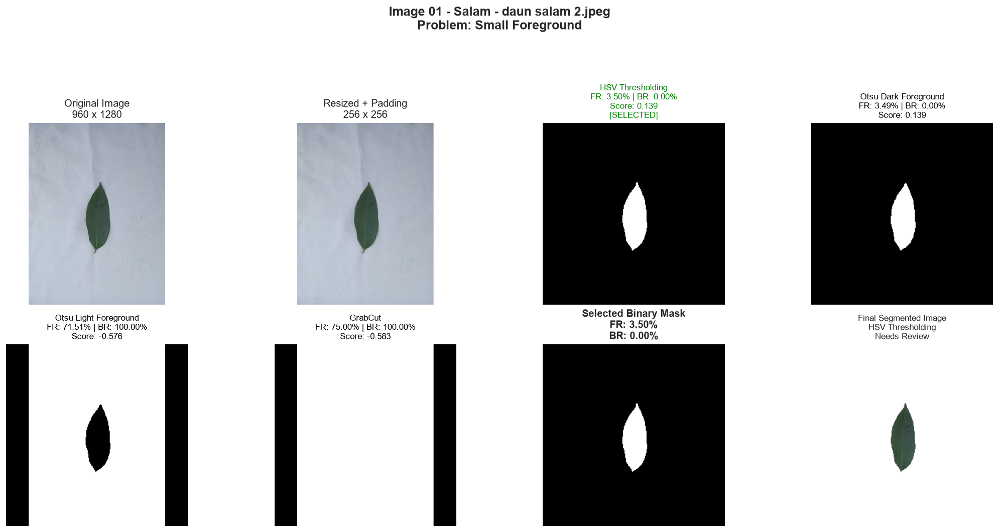

[OK] Visualization saved: 01_daun_salam_2.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


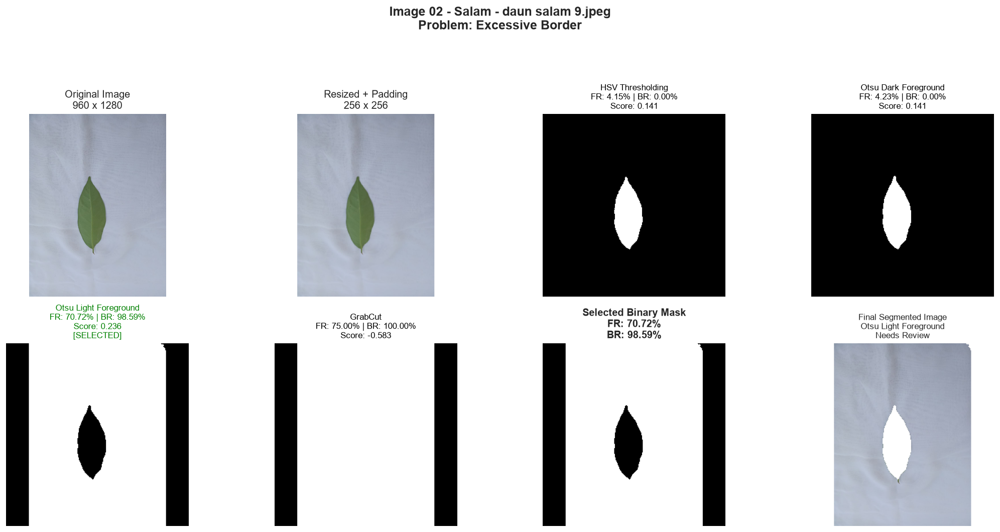

[OK] Visualization saved: 02_daun_salam_9.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


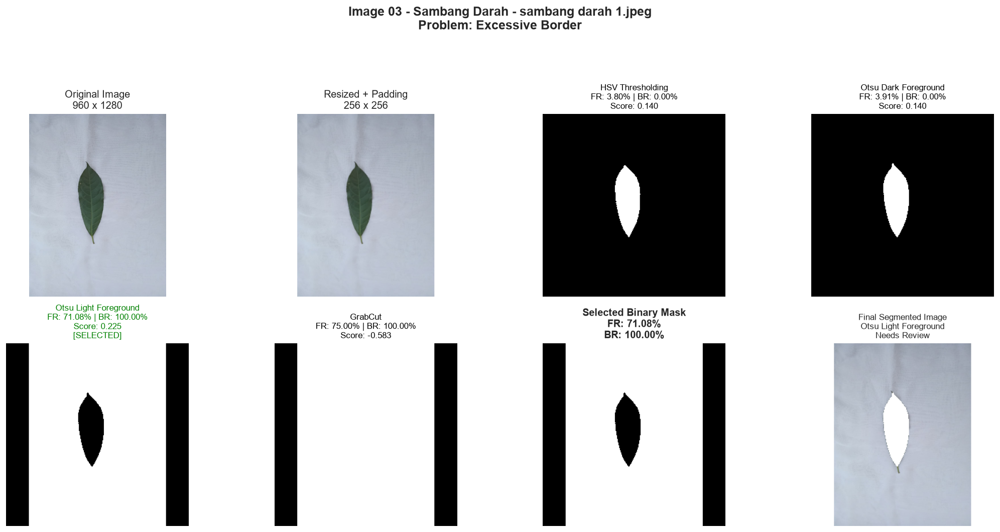

[OK] Visualization saved: 03_sambang_darah_1.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


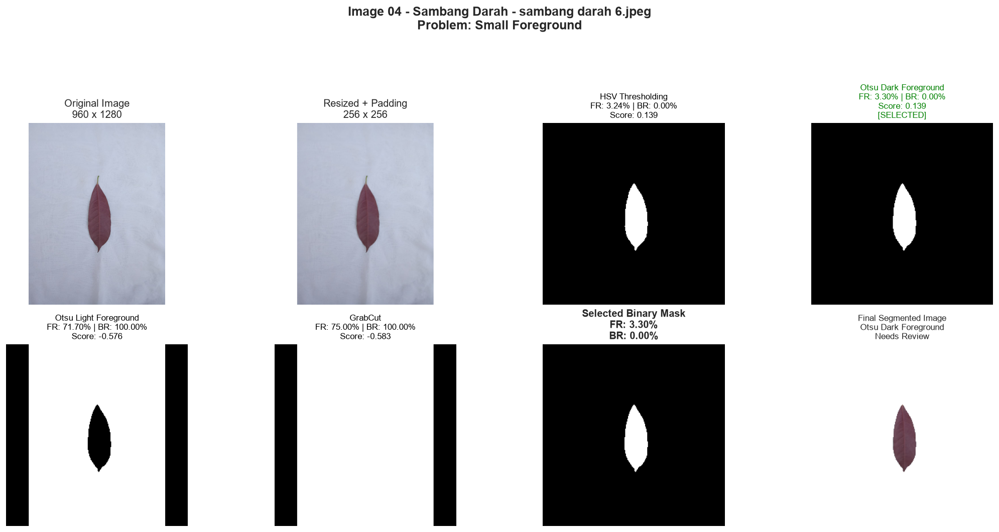

[OK] Visualization saved: 04_sambang_darah_6.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


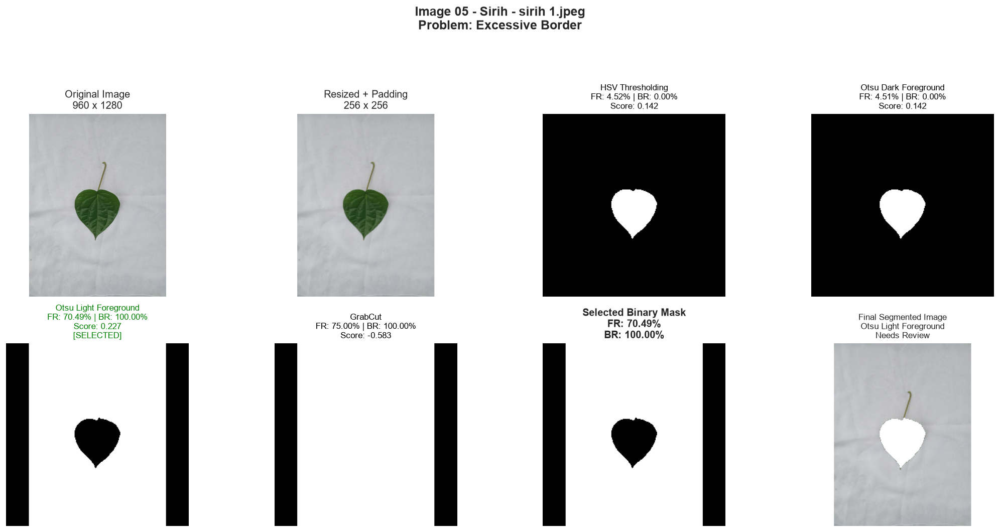

[OK] Visualization saved: 05_sirih_1.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


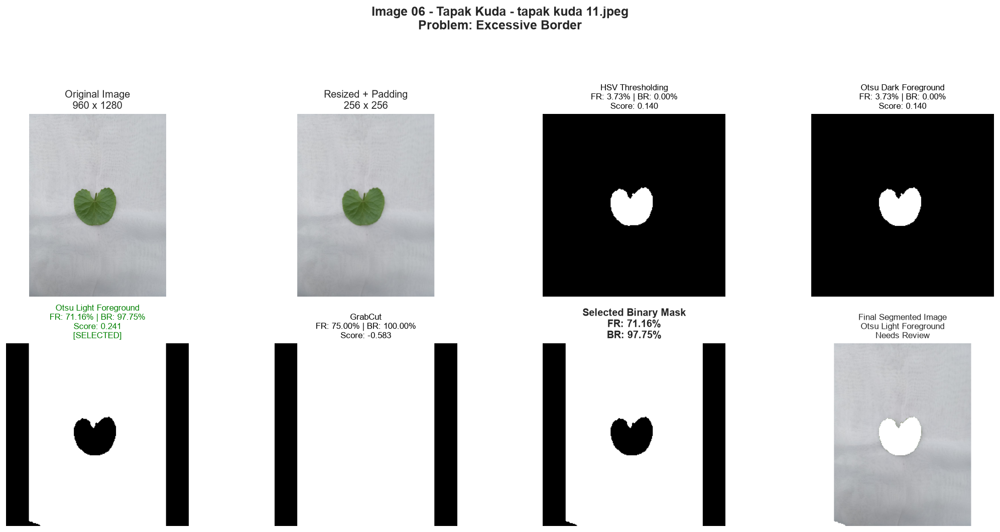

[OK] Visualization saved: 06_tapak_kuda_11.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


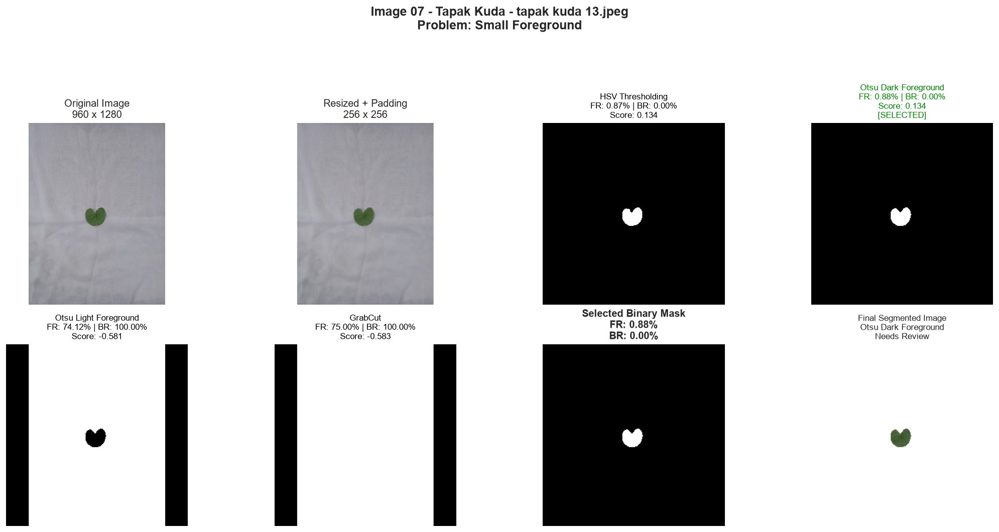

[OK] Visualization saved: 07_tapak_kuda_13.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


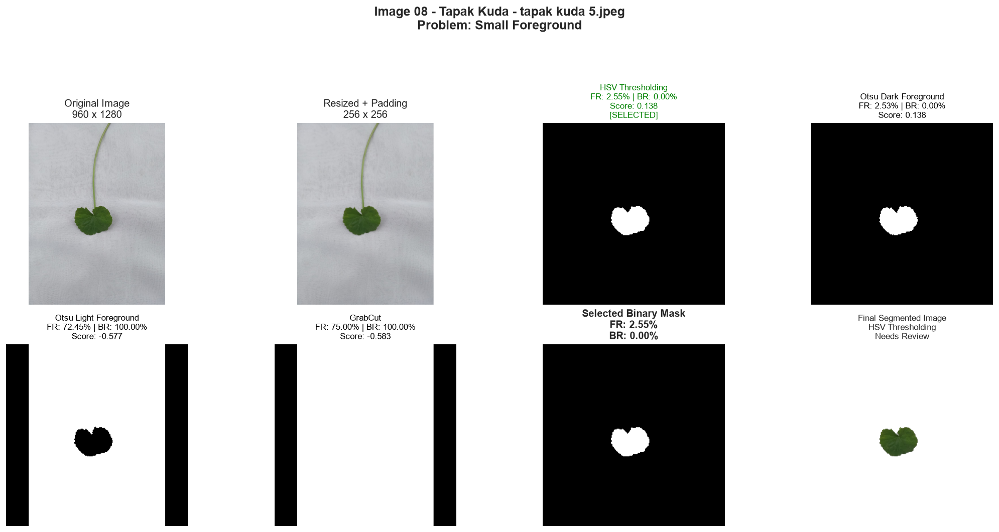

[OK] Visualization saved: 08_tapak_kuda_5.png


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


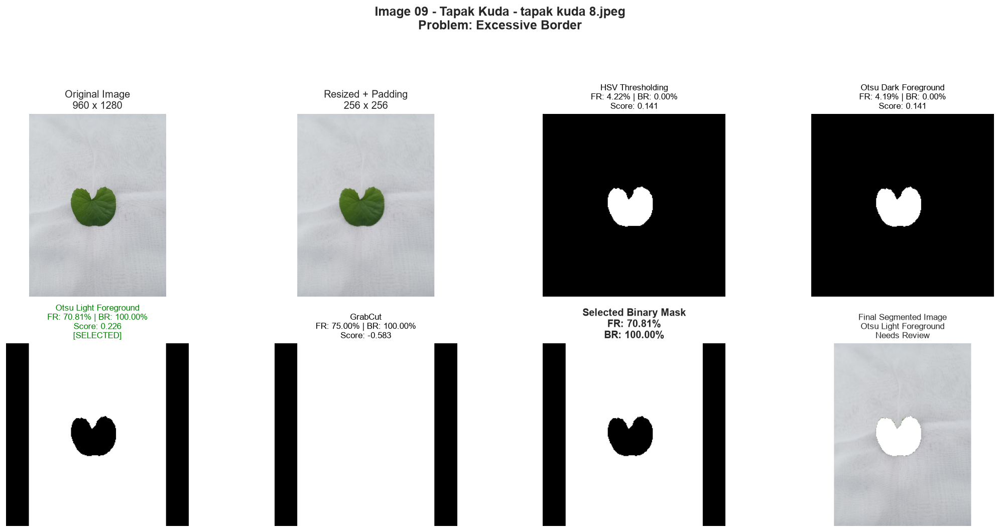

[OK] Visualization saved: 09_tapak_kuda_8.png

4. SEGMENTATION METHOD COMPARISON TABLE


,nama_file,image_path,kelas,tampilan_daun,problem_category,method,foreground_ratio,valid_region_ratio,border_ratio,quality_score,quality_status,is_selected
0,daun salam 2.jpeg,dataset/raw/daun_salam/foto depan/daun salam 2...,Salam,depan,Small Foreground,HSV Thresholding,0.0350,0.0466,0.0000,0.1395,Needs Review,True
1,daun salam 2.jpeg,dataset/raw/daun_salam/foto depan/daun salam 2...,Salam,depan,Small Foreground,Otsu Dark Foreground,0.0349,0.0466,0.0000,0.1395,Needs Review,False
2,daun salam 2.jpeg,dataset/raw/daun_salam/foto depan/daun salam 2...,Salam,depan,Small Foreground,Otsu Light Foreground,0.7151,0.9534,1.0000,-0.5755,Needs Review,False
3,daun salam 2.jpeg,dataset/raw/daun_salam/foto depan/daun salam 2...,Salam,depan,Small Foreground,GrabCut,0.7500,1.0000,1.0000,-0.5825,Needs Review,False
4,daun salam 9.jpeg,dataset/raw/daun_salam/foto belakang/daun sala...,Salam,belakang,Excessive Border,HSV Thresholding,0.0415,0.0553,0.0000,0.1408,Needs Review,False
5,daun salam 9.jpeg,dataset/raw/daun_salam/foto belakang/daun sala...,Salam,belakang,Excessive Border,Otsu Dark Foreground,0.0423,0.0563,0.0000,0.1410,Needs Review,False
6,daun salam 9.jpeg,dataset/raw/daun_salam/foto belakang/daun sala...,Salam,belakang,Excessive Border,Otsu Light Foreground,0.7072,0.9430,0.9859,0.2359,Needs Review,True
7,daun salam 9.jpeg,dataset/raw/daun_salam/foto belakang/daun sala...,Salam,belakang,Excessive Border,GrabCut,0.7500,1.0000,1.0000,-0.5825,Needs Review,False
8,sambang darah 1.jpeg,dataset/raw/daun_sambang_darah/foto depan/samb...,Sambang Darah,depan,Excessive Border,HSV Thresholding,0.0380,0.0507,0.0000,0.1401,Needs Review,False
9,sambang darah 1.jpeg,dataset/raw/daun_sambang_darah/foto depan/samb...,Sambang Darah,depan,Excessive Border,Otsu Dark Foreground,0.0391,0.0522,0.0000,0.1403,Needs Review,False



5. COMBINED SEGMENTATION OVERVIEW


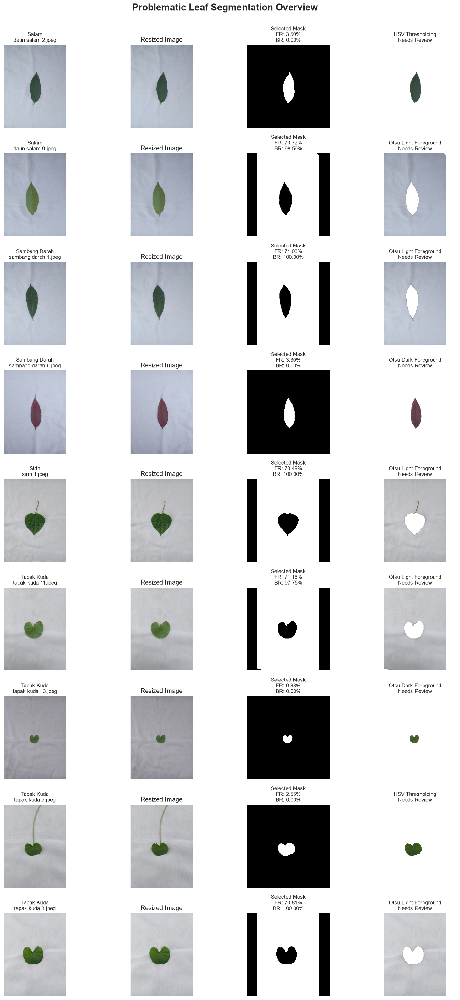


6. FINAL SEGMENTATION REVIEW SUMMARY
Total candidate images    : 104
Problematic images        : 9
Successfully visualized   : 9
Unvisualized images       : 0
Method comparisons        : 36

Visualization directory:
D:\Project\Multimodal_Leaf_Retrieval\results\figures\segmentation_review

[INFO] No images have been removed.
[INFO] Segmentation algorithm has not been modified.
[INFO] Manual visual inspection is required.

Problematic segmentation visualization completed!


In [9]:
# ==================================================
# PROBLEMATIC SEGMENTATION VISUALIZATION
# ==================================================

print("PROBLEMATIC SEGMENTATION VISUALIZATION")
print("=" * 60)


# ==================================================
# 1. IDENTIFY PROBLEMATIC SEGMENTATION
# ==================================================

problematic_segmentation_df = image_quality_df[
    (
        image_quality_df["foreground_ratio"]
        .lt(MIN_FOREGROUND_RATIO)
    )
    | (
        image_quality_df["foreground_ratio"]
        .gt(MAX_FOREGROUND_RATIO)
    )
    | (
        image_quality_df["border_ratio"]
        .gt(MAX_BORDER_RATIO)
    )
    | (
        image_quality_df["segmentation_failed"]
        .eq(True)
    )
    | (
        image_quality_df["inspection_status"]
        .eq("Failed")
    )
].copy()


# Sort problematic images
problematic_segmentation_df = (
    problematic_segmentation_df
    .sort_values(["kelas", "nama_file"])
    .reset_index(drop=True)
)

print("\n1. PROBLEMATIC SEGMENTATION SUMMARY")

print(f"Total candidate images : {len(df_clean)}")

print(
    f"Problematic images     : "
    f"{len(problematic_segmentation_df)}"
)


# Display problematic image details
display(
    problematic_segmentation_df[
        [
            "nama_file",
            "kelas",
            "selected_method",
            "foreground_ratio",
            "border_ratio",
            "quality_issues"
        ]
    ].round(4)
)


# ==================================================
# 2. DEFINE SEGMENTATION PROBLEM CATEGORY
# ==================================================

def identify_segmentation_problem(row):

    problems = []

    if row["foreground_ratio"] < MIN_FOREGROUND_RATIO:

        problems.append("Small Foreground")

    if row["foreground_ratio"] > MAX_FOREGROUND_RATIO:

        problems.append("Large Foreground")

    if row["border_ratio"] > MAX_BORDER_RATIO:

        problems.append("Excessive Border")

    if row["segmentation_failed"] == True:

        problems.append("Segmentation Failed")

    if row["inspection_status"] == "Failed":

        problems.append("Inspection Failed")

    return (
        "; ".join(problems)
        if problems
        else "Requires Inspection"
    )


problematic_segmentation_df["problem_category"] = (
    problematic_segmentation_df.apply(
        identify_segmentation_problem,
        axis=1
    )
)


print("\n2. SEGMENTATION PROBLEM CATEGORIES")

display(
    problematic_segmentation_df[
        "problem_category"
    ].value_counts().to_frame("Number of Images")
)


# ==================================================
# 3. CREATE OUTPUT DIRECTORY
# ==================================================

SEGMENTATION_REVIEW_DIR = (
    FIGURES_DIR / "segmentation_review"
)

SEGMENTATION_REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================
# 4. VISUALIZE ALL SEGMENTATION METHODS
# ==================================================

print("\n3. VISUALIZING PROBLEMATIC IMAGES")

segmentation_comparison_records = []

# Store segmentation results for later inspection
problematic_segmentation_results = {}


for image_index, (_, review_row) in enumerate(
    problematic_segmentation_df.iterrows(),
    start=1
):

    # Match image using the full relative path
    matching_rows = df_clean[
        df_clean["image_path"].eq(
            review_row["image_path"]
        )
    ]

    if len(matching_rows) != 1:

        print(
            f"[WARNING] Cannot uniquely locate: "
            f"{review_row['nama_file']}"
        )

        continue

    sample_row = matching_rows.iloc[0]

    try:

        # Load original image
        original_image = load_image(
            sample_row["absolute_image_path"]
        )

        # Apply the same denoising configuration
        # used during Cell 9
        working_image = original_image.copy()

        if APPLY_DENOISING:

            working_image = cv2.medianBlur(
                working_image,
                MEDIAN_KERNEL_SIZE
            )

        # Resize image
        resized_image, resize_info = (
            resize_with_padding(working_image)
        )

        # Perform adaptive segmentation
        (
            segmented_image,
            selected_mask,
            segmentation_info,
            candidate_results
        ) = segment_leaf(
            resized_image,
            resize_info
        )

    except Exception as error:

        print(
            f"[ERROR] {review_row['nama_file']}: "
            f"{error}"
        )

        continue


    # Store results for later refinement
    problematic_segmentation_results[
        sample_row["image_path"]
    ] = {
        "original_image": original_image,
        "resized_image": resized_image,
        "resize_info": resize_info,
        "selected_mask": selected_mask,
        "segmented_image": segmented_image,
        "segmentation_info": segmentation_info,
        "candidate_results": candidate_results
    }


    # Create comparison figure
    fig, axes = plt.subplots(
        2, 4,
        figsize=(18, 9)
    )

    axes = axes.ravel()


    # --------------------------------------------------
    # Original image
    # --------------------------------------------------

    axes[0].imshow(original_image)

    axes[0].set_title(
        "Original Image\n"
        f"{original_image.shape[1]} x "
        f"{original_image.shape[0]}"
    )


    # --------------------------------------------------
    # Resized image
    # --------------------------------------------------

    axes[1].imshow(resized_image)

    axes[1].set_title(
        "Resized + Padding\n"
        f"{TARGET_WIDTH} x {TARGET_HEIGHT}"
    )


    # --------------------------------------------------
    # Candidate segmentation masks
    # --------------------------------------------------

    methods = [
        "HSV Thresholding",
        "Otsu Dark Foreground",
        "Otsu Light Foreground",
        "GrabCut"
    ]

    for method_index, method in enumerate(
        methods,
        start=2
    ):

        result = candidate_results[method]

        candidate_mask = result["mask"]

        is_selected = (
            method
            == segmentation_info["selected_method"]
        )

        axes[method_index].imshow(
            candidate_mask,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        selected_label = (
            "\n[SELECTED]"
            if is_selected
            else ""
        )

        axes[method_index].set_title(
            f"{method}\n"
            f"FR: {result['foreground_ratio']:.2%} | "
            f"BR: {result['border_ratio']:.2%}\n"
            f"Score: {result['quality_score']:.3f}"
            f"{selected_label}",
            fontsize=10,
            color="green" if is_selected else "black"
        )

        # Store comparison details
        segmentation_comparison_records.append({
            "nama_file": sample_row["nama_file"],
            "image_path": sample_row["image_path"],
            "kelas": sample_row["kelas"],
            "tampilan_daun": sample_row["tampilan_daun"],
            "problem_category": review_row[
                "problem_category"
            ],
            "method": method,
            "foreground_ratio": result[
                "foreground_ratio"
            ],
            "valid_region_ratio": result[
                "valid_region_ratio"
            ],
            "border_ratio": result[
                "border_ratio"
            ],
            "quality_score": result[
                "quality_score"
            ],
            "quality_status": result[
                "quality_status"
            ],
            "is_selected": is_selected
        })


    # --------------------------------------------------
    # Selected binary mask
    # --------------------------------------------------

    axes[6].imshow(
        selected_mask,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[6].set_title(
        "Selected Binary Mask\n"
        f"FR: {segmentation_info['foreground_ratio']:.2%}\n"
        f"BR: {segmentation_info['border_ratio']:.2%}",
        fontweight="bold"
    )


    # --------------------------------------------------
    # Final segmented image
    # --------------------------------------------------

    axes[7].imshow(segmented_image)

    axes[7].set_title(
        "Final Segmented Image\n"
        f"{segmentation_info['selected_method']}\n"
        f"{segmentation_info['quality_status']}",
        fontsize=10
    )


    # Remove axis labels
    for ax in axes:

        ax.axis("off")


    # Main figure title
    fig.suptitle(
        f"Image {image_index:02d} - "
        f"{sample_row['kelas']} - "
        f"{sample_row['nama_file']}\n"
        f"Problem: {review_row['problem_category']}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.92]
    )


    # Create safe filename
    safe_filename = re.sub(
        r"[^a-zA-Z0-9_-]+",
        "_",
        Path(sample_row["nama_file"]).stem
    )

    output_path = (
        SEGMENTATION_REVIEW_DIR
        / f"{image_index:02d}_{safe_filename}.png"
    )


    # Save individual comparison
    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(
        f"[OK] Visualization saved: "
        f"{output_path.name}"
    )


# ==================================================
# 5. CREATE COMPARISON TABLE
# ==================================================

comparison_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "tampilan_daun",
    "problem_category",
    "method",
    "foreground_ratio",
    "valid_region_ratio",
    "border_ratio",
    "quality_score",
    "quality_status",
    "is_selected"
]

problematic_method_comparison_df = pd.DataFrame(
    segmentation_comparison_records,
    columns=comparison_columns
)

print("\n4. SEGMENTATION METHOD COMPARISON TABLE")

display(
    problematic_method_comparison_df.round(4)
)


# ==================================================
# 6. CREATE COMBINED SEGMENTATION OVERVIEW
# ==================================================

print("\n5. COMBINED SEGMENTATION OVERVIEW")

n_problematic = len(
    problematic_segmentation_results
)

if n_problematic > 0:

    fig, axes = plt.subplots(
        n_problematic,
        4,
        figsize=(14, 3 * n_problematic),
        squeeze=False
    )

    for row_index, (image_path, result) in enumerate(
        problematic_segmentation_results.items()
    ):

        sample_row = df_clean[
            df_clean["image_path"].eq(image_path)
        ].iloc[0]

        info = result["segmentation_info"]

        # Original image
        axes[row_index, 0].imshow(
            result["original_image"]
        )

        axes[row_index, 0].set_title(
            f"{sample_row['kelas']}\n"
            f"{sample_row['nama_file']}",
            fontsize=10
        )

        # Resized image
        axes[row_index, 1].imshow(
            result["resized_image"]
        )

        axes[row_index, 1].set_title(
            "Resized Image"
        )

        # Selected binary mask
        axes[row_index, 2].imshow(
            result["selected_mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row_index, 2].set_title(
            "Selected Mask\n"
            f"FR: {info['foreground_ratio']:.2%}\n"
            f"BR: {info['border_ratio']:.2%}",
            fontsize=10
        )

        # Final segmentation
        axes[row_index, 3].imshow(
            result["segmented_image"]
        )

        axes[row_index, 3].set_title(
            f"{info['selected_method']}\n"
            f"{info['quality_status']}",
            fontsize=10
        )

        for ax in axes[row_index]:

            ax.axis("off")


    fig.suptitle(
        "Problematic Leaf Segmentation Overview",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.98]
    )

    plt.savefig(
        FIGURES_DIR /
        "13_problematic_segmentation_overview.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

else:

    print("No problematic segmentation to visualize.")


# ==================================================
# 7. SAVE SEGMENTATION REVIEW RESULTS
# ==================================================

problematic_segmentation_df.to_csv(
    METRICS_DIR /
    "33_problematic_segmentation_records.csv",
    index=False,
    encoding="utf-8-sig"
)

problematic_method_comparison_df.to_csv(
    METRICS_DIR /
    "34_problematic_segmentation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


# ==================================================
# 8. FINAL SUMMARY
# ==================================================

print("\n6. FINAL SEGMENTATION REVIEW SUMMARY")
print("=" * 60)

print(
    f"Total candidate images    : "
    f"{len(df_clean)}"
)

print(
    f"Problematic images        : "
    f"{len(problematic_segmentation_df)}"
)

print(
    f"Successfully visualized   : "
    f"{n_problematic}"
)

print(
    f"Unvisualized images       : "
    f"{len(problematic_segmentation_df) - n_problematic}"
)

print(
    f"Method comparisons        : "
    f"{len(problematic_method_comparison_df)}"
)

print("\nVisualization directory:")
print(SEGMENTATION_REVIEW_DIR)

print("\n[INFO] No images have been removed.")

print("[INFO] Segmentation algorithm has not been modified.")

print("[INFO] Manual visual inspection is required.")

print("\nProblematic segmentation visualization completed!")

SEGMENTATION REFINEMENT

1. REFINEMENT TEST ON PROBLEMATIC IMAGES


Refining segmentation:   0%|          | 0/9 [00:00<?, ?it/s]

C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(



2. SEGMENTATION REFINEMENT COMPARISON


,nama_file,kelas,old_method,new_method,old_foreground_ratio,new_foreground_ratio,old_border_ratio,new_border_ratio,border_issue_resolved,new_quality_status
0,daun salam 2.jpeg,Salam,HSV Thresholding,HSV Thresholding,0.0350,0.0350,0.0000,0.0,False,Needs Review
1,daun salam 9.jpeg,Salam,Otsu Light Foreground,Otsu Dark Foreground,0.7072,0.0423,0.9859,0.0,True,Needs Review
2,sambang darah 1.jpeg,Sambang Darah,Otsu Light Foreground,Otsu Dark Foreground,0.7108,0.0391,1.0000,0.0,True,Needs Review
3,sambang darah 6.jpeg,Sambang Darah,Otsu Dark Foreground,Otsu Dark Foreground,0.0330,0.0330,0.0000,0.0,False,Needs Review
4,sirih 1.jpeg,Sirih,Otsu Light Foreground,HSV Thresholding,0.7049,0.0452,1.0000,0.0,True,Needs Review
5,tapak kuda 11.jpeg,Tapak Kuda,Otsu Light Foreground,HSV Thresholding,0.7116,0.0373,0.9775,0.0,True,Needs Review
6,tapak kuda 13.jpeg,Tapak Kuda,Otsu Dark Foreground,Otsu Dark Foreground,0.0088,0.0088,0.0000,0.0,False,Needs Review
7,tapak kuda 5.jpeg,Tapak Kuda,HSV Thresholding,HSV Thresholding,0.0255,0.0255,0.0000,0.0,False,Needs Review
8,tapak kuda 8.jpeg,Tapak Kuda,Otsu Light Foreground,HSV Thresholding,0.7081,0.0422,1.0000,0.0,True,Needs Review



3. BEFORE AND AFTER REFINEMENT


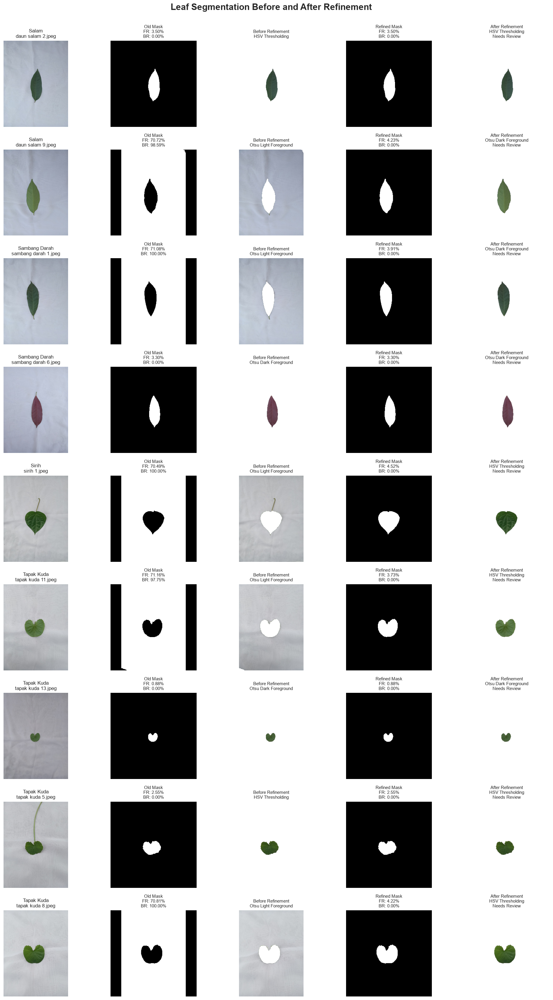


4. REINSPECTING ENTIRE DATASET


Validating refined masks:   0%|          | 0/104 [00:00<?, ?it/s]

C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(



5. DATASET-WIDE REFINEMENT COMPARISON


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


,Indicator,Before Refinement,After Refinement,Difference
0,Total inspected images,104,104,0
1,Foreground ratio below 5%,4,9,5
2,Excessive border ratio,5,0,-5
3,Passed initial check,64,64,0
4,Needs review,40,40,0
5,Failed inspections,0,0,0



6. REGRESSION CHECK
Previously passed images : 64
Status regressions       : 0
[OK] No status regression detected.


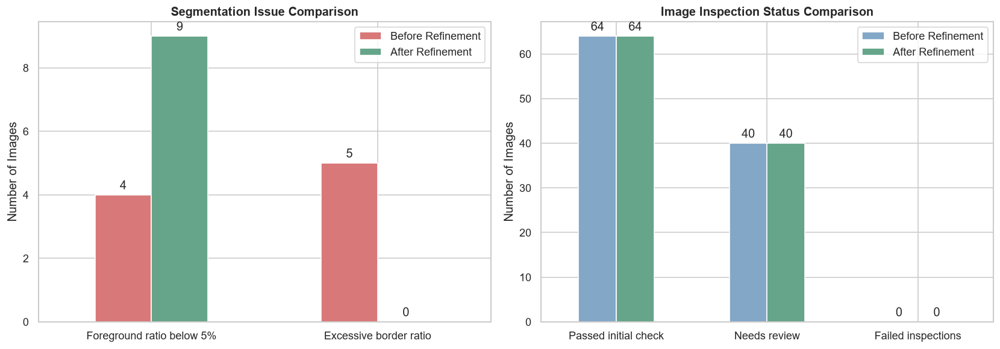


7. FINAL REFINEMENT SUMMARY
Total candidate images : 104
Problematic images tested : 9
Excessive border before : 5
Excessive border after  : 0
Small foreground after  : 9
Border issues resolved  : 5
Selected masks changed  : 5
Status regressions      : 0
Failed inspections      : 0

[INFO] Original dataset has not been modified.
[INFO] Small foreground objects remain available for visual review.
[INFO] Visual verification is required before batch preprocessing.

Segmentation refinement completed!


In [10]:
# ==================================================
# SEGMENTATION REFINEMENT
# ==================================================

print("SEGMENTATION REFINEMENT")
print("=" * 60)


# ==================================================
# 1. REFINED SEGMENTATION CONFIGURATION
# ==================================================

REFINED_MIN_MASK_PIXELS = 100

REFINED_MAX_BORDER_RATIO = 0.35

REFINED_MAX_VALID_REGION_RATIO = 0.90

SMALL_FOREGROUND_REVIEW_RATIO = 0.05

# Heuristic scoring weights
BORDER_PENALTY_WEIGHT = 1.5

AREA_PENALTY_WEIGHT = 0.10

PREFERRED_FOREGROUND_RATIO = 0.20


# ==================================================
# 2. CALCULATE REFINED MASK QUALITY
# ==================================================

def calculate_refined_mask_quality(
    mask,
    valid_region
):

    # Reuse original mask measurements
    original_quality = calculate_mask_quality(
        mask,
        valid_region
    )

    foreground_pixels = int(
        np.count_nonzero(mask)
    )

    foreground_ratio = original_quality[
        "foreground_ratio"
    ]

    valid_region_ratio = original_quality[
        "valid_region_ratio"
    ]

    border_ratio = original_quality[
        "border_ratio"
    ]

    # Check minimum foreground pixels
    sufficient_pixels = (
        foreground_pixels
        >= REFINED_MIN_MASK_PIXELS
    )

    # Check excessive foreground at image boundaries
    acceptable_border = (
        border_ratio
        <= REFINED_MAX_BORDER_RATIO
    )

    # Prevent selecting almost the entire source image
    acceptable_region = (
        valid_region_ratio
        <= REFINED_MAX_VALID_REGION_RATIO
    )

    # Check mask eligibility
    eligible_mask = (
        sufficient_pixels
        and acceptable_border
        and acceptable_region
    )

    # Calculate refined heuristic score
    refined_score = 1.0

    # Stronger penalty for border coverage
    refined_score -= (
        BORDER_PENALTY_WEIGHT
        * border_ratio
    )

    # Mild area preference
    refined_score -= (
        AREA_PENALTY_WEIGHT
        * abs(
            valid_region_ratio
            - PREFERRED_FOREGROUND_RATIO
        )
    )

    # Do not strongly penalize small foreground objects
    # as long as the number of foreground pixels
    # is technically sufficient

    if not sufficient_pixels:

        refined_score -= 2.0

    if not acceptable_region:

        refined_score -= 1.0

    # Determine refined quality status
    if not sufficient_pixels:

        quality_status = "Failed"

    elif not eligible_mask:

        quality_status = "Needs Review"

    elif (
        foreground_ratio
        < SMALL_FOREGROUND_REVIEW_RATIO
    ):

        quality_status = "Needs Review"

    else:

        quality_status = "Passed Initial Check"

    return {
        "foreground_pixels": foreground_pixels,

        "foreground_ratio": float(
            foreground_ratio
        ),

        "valid_region_ratio": float(
            valid_region_ratio
        ),

        "border_ratio": float(
            border_ratio
        ),

        "quality_score": float(
            refined_score
        ),

        "eligible_mask": bool(
            eligible_mask
        ),

        "quality_status": quality_status
    }


# ==================================================
# 3. REFINED ADAPTIVE SEGMENTATION
# ==================================================

def segment_leaf_refined(
    image,
    resize_info=None
):

    # Create valid source image region
    valid_region = create_valid_region(
        image,
        resize_info
    )

    # Generate Otsu candidates
    otsu_dark, otsu_light = segment_otsu(
        image,
        valid_region
    )

    # Generate all candidate masks
    candidate_masks = {
        "HSV Thresholding": segment_hsv(
            image,
            valid_region
        ),

        "Otsu Dark Foreground": otsu_dark,

        "Otsu Light Foreground": otsu_light,

        "GrabCut": segment_grabcut(
            image,
            valid_region
        )
    }

    refined_results = {}

    # Clean and evaluate each candidate
    for method, raw_mask in candidate_masks.items():

        cleaned_mask = clean_binary_mask(
            raw_mask,
            valid_region
        )

        refined_quality = (
            calculate_refined_mask_quality(
                cleaned_mask,
                valid_region
            )
        )

        refined_results[method] = {
            "mask": cleaned_mask,
            **refined_quality
        }

    # Identify eligible candidates
    eligible_methods = [
        method
        for method, result
        in refined_results.items()
        if result["eligible_mask"]
    ]

    # Preserve previously successful masks
    (
        _,
        original_mask,
        original_info,
        _
    ) = segment_leaf(
        image,
        resize_info
    )

    original_method = original_info[
        "selected_method"
    ]

    # Keep original selection if it passed
    # and remains eligible under refined rules
    preserve_original = (
        original_info["quality_status"]
        == "Passed Initial Check"

        and refined_results[original_method][
            "eligible_mask"
        ]
    )

    if preserve_original:

        best_method = original_method

        selection_reason = (
            "Preserved original valid selection"
        )

    elif eligible_methods:

        # Select the highest score only among
        # eligible candidate masks
        best_method = max(
            eligible_methods,
            key=lambda method: (
                refined_results[method][
                    "quality_score"
                ]
            )
        )

        selection_reason = (
            "Selected eligible refined mask"
        )

    else:

        # Fallback selection for manual inspection
        best_method = max(
            refined_results,
            key=lambda method: (
                refined_results[method][
                    "quality_score"
                ]
            )
        )

        selection_reason = (
            "Fallback - no eligible mask"
        )

    # Retrieve selected result
    best_result = refined_results[
        best_method
    ]

    best_mask = best_result["mask"]

    # Create segmented RGB image
    segmented_image = np.full_like(
        image,
        255
    )

    segmented_image[best_mask > 0] = (
        image[best_mask > 0]
    )

    # Store segmentation information
    segmentation_info = {
        "selected_method": best_method,

        "foreground_pixels": best_result[
            "foreground_pixels"
        ],

        "foreground_ratio": best_result[
            "foreground_ratio"
        ],

        "valid_region_ratio": best_result[
            "valid_region_ratio"
        ],

        "border_ratio": best_result[
            "border_ratio"
        ],

        "quality_score": best_result[
            "quality_score"
        ],

        "eligible_mask": best_result[
            "eligible_mask"
        ],

        "quality_status": best_result[
            "quality_status"
        ],

        "selection_reason": selection_reason,

        "original_method": original_method,

        "method_changed": (
            best_method != original_method
        )
    }

    # Ensure fallback remains marked for review
    if not eligible_methods:

        if (
            best_result["foreground_pixels"]
            >= REFINED_MIN_MASK_PIXELS
        ):

            segmentation_info[
                "quality_status"
            ] = "Needs Review"

        else:

            segmentation_info[
                "quality_status"
            ] = "Failed"

    return (
        segmented_image,
        best_mask,
        segmentation_info,
        refined_results
    )


# ==================================================
# 4. TEST REFINEMENT ON PROBLEMATIC IMAGES
# ==================================================

print("\n1. REFINEMENT TEST ON PROBLEMATIC IMAGES")

refinement_records = []

refinement_visual_results = {}

for _, review_row in tqdm(
    problematic_segmentation_df.iterrows(),
    total=len(problematic_segmentation_df),
    desc="Refining segmentation"
):

    # Locate image metadata
    matching_rows = df_clean[
        df_clean["image_path"].eq(
            review_row["image_path"]
        )
    ]

    if len(matching_rows) != 1:

        print(
            f"[WARNING] Cannot locate "
            f"{review_row['nama_file']}"
        )

        continue

    row = matching_rows.iloc[0]

    # Load original image
    original_image = load_image(
        row["absolute_image_path"]
    )

    working_image = original_image.copy()

    if APPLY_DENOISING:

        working_image = cv2.medianBlur(
            working_image,
            MEDIAN_KERNEL_SIZE
        )

    # Resize image
    resized_image, resize_info = (
        resize_with_padding(
            working_image
        )
    )

    # Original segmentation
    (
        original_segmented,
        original_mask,
        original_info,
        _
    ) = segment_leaf(
        resized_image,
        resize_info
    )

    # Refined segmentation
    (
        refined_segmented,
        refined_mask,
        refined_info,
        refined_candidates
    ) = segment_leaf_refined(
        resized_image,
        resize_info
    )

    # Detect previous excessive border coverage
    old_excessive_border = (
        original_info["border_ratio"]
        > REFINED_MAX_BORDER_RATIO
    )

    # Detect refined excessive border coverage
    new_excessive_border = (
        refined_info["border_ratio"]
        > REFINED_MAX_BORDER_RATIO
    )

    # Check whether excessive border issue
    # has been resolved by the new rules
    border_issue_resolved = (
        old_excessive_border
        and not new_excessive_border
        and refined_info["eligible_mask"]
    )

    # Record whether the selected mask changed
    mask_changed = not np.array_equal(
        original_mask,
        refined_mask
    )

    refinement_records.append({
        "nama_file": row["nama_file"],
        "image_path": row["image_path"],
        "kelas": row["kelas"],

        "old_method": original_info[
            "selected_method"
        ],

        "new_method": refined_info[
            "selected_method"
        ],

        "old_foreground_ratio": original_info[
            "foreground_ratio"
        ],

        "new_foreground_ratio": refined_info[
            "foreground_ratio"
        ],

        "old_border_ratio": original_info[
            "border_ratio"
        ],

        "new_border_ratio": refined_info[
            "border_ratio"
        ],

        "old_quality_status": original_info[
            "quality_status"
        ],

        "new_quality_status": refined_info[
            "quality_status"
        ],

        "eligible_mask": refined_info[
            "eligible_mask"
        ],

        "method_changed": refined_info[
            "method_changed"
        ],

        "mask_changed": mask_changed,

        "border_issue_resolved": (
            border_issue_resolved
        ),

        "selection_reason": refined_info[
            "selection_reason"
        ]
    })

    refinement_visual_results[
        row["image_path"]
    ] = {
        "nama_file": row["nama_file"],
        "kelas": row["kelas"],

        "original_image": original_image,

        "old_mask": original_mask,
        "old_segmented": original_segmented,

        "new_mask": refined_mask,
        "new_segmented": refined_segmented,

        "old_info": original_info,
        "new_info": refined_info
    }


# Convert results into DataFrame
refinement_df = pd.DataFrame(
    refinement_records
)

print("\n2. SEGMENTATION REFINEMENT COMPARISON")

if not refinement_df.empty:

    display(
        refinement_df[
            [
                "nama_file",
                "kelas",
                "old_method",
                "new_method",
                "old_foreground_ratio",
                "new_foreground_ratio",
                "old_border_ratio",
                "new_border_ratio",
                "border_issue_resolved",
                "new_quality_status"
            ]
        ].round(4)
    )

else:

    print("No problematic images available for refinement.")


# ==================================================
# 5. BEFORE AND AFTER VISUALIZATION
# ==================================================

print("\n3. BEFORE AND AFTER REFINEMENT")

n_images = len(
    refinement_visual_results
)

if n_images > 0:

    fig, axes = plt.subplots(
        n_images,
        5,
        figsize=(17, 3.2 * n_images),
        squeeze=False
    )

    for row_index, result in enumerate(
        refinement_visual_results.values()
    ):

        old_info = result["old_info"]

        new_info = result["new_info"]

        # Original image
        axes[row_index, 0].imshow(
            result["original_image"]
        )

        axes[row_index, 0].set_title(
            f"{result['kelas']}\n"
            f"{result['nama_file']}",
            fontsize=10
        )

        # Old mask
        axes[row_index, 1].imshow(
            result["old_mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row_index, 1].set_title(
            "Old Mask\n"
            f"FR: {old_info['foreground_ratio']:.2%}\n"
            f"BR: {old_info['border_ratio']:.2%}",
            fontsize=9
        )

        # Old segmentation
        axes[row_index, 2].imshow(
            result["old_segmented"]
        )

        axes[row_index, 2].set_title(
            "Before Refinement\n"
            f"{old_info['selected_method']}",
            fontsize=9
        )

        # Refined mask
        axes[row_index, 3].imshow(
            result["new_mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row_index, 3].set_title(
            "Refined Mask\n"
            f"FR: {new_info['foreground_ratio']:.2%}\n"
            f"BR: {new_info['border_ratio']:.2%}",
            fontsize=9
        )

        # Refined segmentation
        axes[row_index, 4].imshow(
            result["new_segmented"]
        )

        axes[row_index, 4].set_title(
            "After Refinement\n"
            f"{new_info['selected_method']}\n"
            f"{new_info['quality_status']}",
            fontsize=9
        )

        for ax in axes[row_index]:

            ax.axis("off")

    fig.suptitle(
        "Leaf Segmentation Before and After Refinement",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.98]
    )

    plt.savefig(
        FIGURES_DIR /
        "14_segmentation_refinement_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ==================================================
# 6. REINSPECT ENTIRE DATASET
# ==================================================

print("\n4. REINSPECTING ENTIRE DATASET")

refined_inspection_records = []

for _, row in tqdm(
    df_clean.iterrows(),
    total=len(df_clean),
    desc="Validating refined masks"
):

    try:

        # Load and resize original image
        image = load_image(
            row["absolute_image_path"]
        )

        if APPLY_DENOISING:

            image = cv2.medianBlur(
                image,
                MEDIAN_KERNEL_SIZE
            )

        resized, resize_info = (
            resize_with_padding(image)
        )

        # Apply refined segmentation
        (
            segmented,
            mask,
            seg_info,
            _
        ) = segment_leaf_refined(
            resized,
            resize_info
        )

        # Recalculate image quality
        image_quality = calculate_image_quality(
            resized,
            mask
        )

        # Collect review issues
        issues = []

        if not seg_info["eligible_mask"]:

            issues.append(
                "Ineligible segmentation mask"
            )

        if (
            seg_info["foreground_ratio"]
            < SMALL_FOREGROUND_REVIEW_RATIO
        ):

            issues.append(
                "Small foreground"
            )

        if (
            seg_info["border_ratio"]
            > REFINED_MAX_BORDER_RATIO
        ):

            issues.append(
                "Excessive border ratio"
            )

        if image_quality["is_blurry"]:

            issues.append(
                "Potential blur"
            )

        if image_quality["is_low_contrast"]:

            issues.append(
                "Low contrast"
            )

        if image_quality["is_dark"]:

            issues.append(
                "Low brightness"
            )

        if image_quality["is_bright"]:

            issues.append(
                "High brightness"
            )

        if not image_quality[
            "quality_measurable"
        ]:

            issues.append(
                "Insufficient pixels for quality measurement"
            )

        # Validate image and mask structure
        valid_dimensions = (
            resized.shape[:2]
            == (TARGET_HEIGHT, TARGET_WIDTH)
        )

        valid_mask_dimensions = (
            mask.shape
            == (TARGET_HEIGHT, TARGET_WIDTH)
        )

        valid_binary_mask = set(
            np.unique(mask)
        ).issubset({0, 255})

        if not valid_dimensions:

            issues.append(
                "Invalid image dimensions"
            )

        if not valid_mask_dimensions:

            issues.append(
                "Invalid mask dimensions"
            )

        if not valid_binary_mask:

            issues.append(
                "Invalid binary mask"
            )

        segmentation_failed = (
            seg_info["quality_status"] == "Failed"

            or not valid_dimensions

            or not valid_mask_dimensions

            or not valid_binary_mask
        )

        if segmentation_failed:

            inspection_status = "Failed"

        elif issues:

            inspection_status = "Needs Review"

        else:

            inspection_status = "Passed Initial Check"

        refined_inspection_records.append({
            "nama_file": row["nama_file"],
            "image_path": row["image_path"],
            "kelas": row["kelas"],
            "tampilan_daun": row["tampilan_daun"],

            **seg_info,
            **image_quality,

            "valid_dimensions": valid_dimensions,

            "valid_mask_dimensions": (
                valid_mask_dimensions
            ),

            "valid_binary_mask": (
                valid_binary_mask
            ),

            "segmentation_failed": (
                segmentation_failed
            ),

            "inspection_status": (
                inspection_status
            ),

            "quality_issues": (
                "; ".join(issues)
                if issues
                else "None"
            )
        })

    except Exception as error:

        refined_inspection_records.append({
            "nama_file": row["nama_file"],
            "image_path": row["image_path"],
            "kelas": row["kelas"],
            "tampilan_daun": row["tampilan_daun"],

            "eligible_mask": False,

            "segmentation_failed": True,

            "inspection_status": "Failed",

            "quality_issues": str(error)
        })


refined_quality_df = pd.DataFrame(
    refined_inspection_records
)

# Ensure required measurement columns exist
required_measurement_columns = [
    "foreground_ratio",
    "border_ratio",
    "valid_region_ratio",
    "blur_score",
    "contrast",
    "mean_brightness"
]

for column in required_measurement_columns:

    if column not in refined_quality_df.columns:

        refined_quality_df[column] = np.nan


# ==================================================
# 7. COMPARE BEFORE AND AFTER RESULTS
# ==================================================

print("\n5. DATASET-WIDE REFINEMENT COMPARISON")

refinement_summary = pd.DataFrame({
    "Indicator": [
        "Total inspected images",

        "Foreground ratio below 5%",

        "Excessive border ratio",

        "Passed initial check",

        "Needs review",

        "Failed inspections"
    ],

    "Before Refinement": [
        len(image_quality_df),

        image_quality_df["foreground_ratio"]
        .lt(MIN_FOREGROUND_RATIO).sum(),

        image_quality_df["border_ratio"]
        .gt(MAX_BORDER_RATIO).sum(),

        image_quality_df["inspection_status"]
        .eq("Passed Initial Check").sum(),

        image_quality_df["inspection_status"]
        .eq("Needs Review").sum(),

        image_quality_df["inspection_status"]
        .eq("Failed").sum()
    ],

    "After Refinement": [
        len(refined_quality_df),

        refined_quality_df["foreground_ratio"]
        .lt(SMALL_FOREGROUND_REVIEW_RATIO).sum(),

        refined_quality_df["border_ratio"]
        .gt(REFINED_MAX_BORDER_RATIO).sum(),

        refined_quality_df["inspection_status"]
        .eq("Passed Initial Check").sum(),

        refined_quality_df["inspection_status"]
        .eq("Needs Review").sum(),

        refined_quality_df["inspection_status"]
        .eq("Failed").sum()
    ]
})

refinement_summary["Difference"] = (
    refinement_summary["After Refinement"]

    - refinement_summary["Before Refinement"]
)

display(refinement_summary)


# ==================================================
# 8. VERIFY PREVIOUSLY PASSED IMAGES
# ==================================================

print("\n6. REGRESSION CHECK")

status_comparison = image_quality_df[
    [
        "image_path",
        "inspection_status"
    ]
].merge(
    refined_quality_df[
        [
            "image_path",
            "inspection_status"
        ]
    ],

    on="image_path",

    suffixes=("_before", "_after"),

    validate="one_to_one"
)

regression_records = status_comparison[
    status_comparison[
        "inspection_status_before"
    ].eq("Passed Initial Check")

    & status_comparison[
        "inspection_status_after"
    ].ne("Passed Initial Check")
]

print(
    f"Previously passed images : "
    f"{image_quality_df['inspection_status'].eq('Passed Initial Check').sum()}"
)

print(
    f"Status regressions       : "
    f"{len(regression_records)}"
)

if regression_records.empty:

    print(
        "[OK] No status regression detected."
    )

else:

    display(regression_records)


# ==================================================
# 9. VISUALIZE REFINEMENT SUMMARY
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Compare excessive border and small foreground
issue_comparison = refinement_summary.iloc[
    [1, 2]
].set_index("Indicator")

issue_comparison[
    [
        "Before Refinement",
        "After Refinement"
    ]
].plot(
    kind="bar",
    color=["#D97878", "#66A58A"],
    rot=0,
    ax=axes[0]
)

axes[0].set_title(
    "Segmentation Issue Comparison",
    fontweight="bold"
)

axes[0].set_ylabel(
    "Number of Images"
)

axes[0].set_xlabel("")

for container in axes[0].containers:

    axes[0].bar_label(
        container,
        padding=3
    )

# Compare overall quality statuses
status_summary = refinement_summary.iloc[
    [3, 4, 5]
].set_index("Indicator")

status_summary[
    [
        "Before Refinement",
        "After Refinement"
    ]
].plot(
    kind="bar",
    color=["#83A7C7", "#66A58A"],
    rot=0,
    ax=axes[1]
)

axes[1].set_title(
    "Image Inspection Status Comparison",
    fontweight="bold"
)

axes[1].set_ylabel(
    "Number of Images"
)

axes[1].set_xlabel("")

for container in axes[1].containers:

    axes[1].bar_label(
        container,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "15_segmentation_refinement_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 10. SAVE REFINEMENT RESULTS
# ==================================================

refinement_df.to_csv(
    METRICS_DIR /
    "35_segmentation_refinement_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

refined_quality_df.to_csv(
    METRICS_DIR /
    "36_refined_image_quality_details.csv",
    index=False,
    encoding="utf-8-sig"
)

refinement_summary.to_csv(
    METRICS_DIR /
    "37_segmentation_refinement_summary.csv",
    index=False
)

regression_records.to_csv(
    METRICS_DIR /
    "38_segmentation_regression_records.csv",
    index=False,
    encoding="utf-8-sig"
)


# Save records still requiring review
refined_review_df = refined_quality_df[
    refined_quality_df[
        "inspection_status"
    ].ne("Passed Initial Check")
].copy()

refined_review_df.to_csv(
    METRICS_DIR /
    "39_refined_image_quality_review.csv",
    index=False,
    encoding="utf-8-sig"
)


# ==================================================
# 11. SAVE REFINED CONFIGURATION
# ==================================================

refined_config = {
    **config,

    "segmentation_method": (
        "Refined Adaptive Selection"
    ),

    "refined_min_mask_pixels": (
        REFINED_MIN_MASK_PIXELS
    ),

    "refined_max_border_ratio": (
        REFINED_MAX_BORDER_RATIO
    ),

    "refined_max_valid_region_ratio": (
        REFINED_MAX_VALID_REGION_RATIO
    ),

    "small_foreground_review_ratio": (
        SMALL_FOREGROUND_REVIEW_RATIO
    ),

    "border_penalty_weight": (
        BORDER_PENALTY_WEIGHT
    ),

    "area_penalty_weight": (
        AREA_PENALTY_WEIGHT
    ),

    "preferred_foreground_ratio": (
        PREFERRED_FOREGROUND_RATIO
    ),

    "preserve_original_valid_selection": True
}

REFINED_CONFIG_PATH = (
    PROCESSED_DIR /
    "preprocessing_config_refined.json"
)

with open(
    REFINED_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        refined_config,
        file,
        indent=4
    )


# ==================================================
# 12. FINAL REFINEMENT SUMMARY
# ==================================================

print("\n7. FINAL REFINEMENT SUMMARY")
print("=" * 60)

print(
    f"Total candidate images : "
    f"{len(df_clean)}"
)

print(
    f"Problematic images tested : "
    f"{len(refinement_df)}"
)

print(
    f"Excessive border before : "
    f"{image_quality_df['border_ratio'].gt(MAX_BORDER_RATIO).sum()}"
)

print(
    f"Excessive border after  : "
    f"{refined_quality_df['border_ratio'].gt(REFINED_MAX_BORDER_RATIO).sum()}"
)

print(
    f"Small foreground after  : "
    f"{refined_quality_df['foreground_ratio'].lt(SMALL_FOREGROUND_REVIEW_RATIO).sum()}"
)

if not refinement_df.empty:

    print(
        f"Border issues resolved  : "
        f"{refinement_df['border_issue_resolved'].sum()}"
    )

    print(
        f"Selected masks changed  : "
        f"{refinement_df['mask_changed'].sum()}"
    )

print(
    f"Status regressions      : "
    f"{len(regression_records)}"
)

print(
    f"Failed inspections      : "
    f"{refined_quality_df['inspection_status'].eq('Failed').sum()}"
)

print("\n[INFO] Original dataset has not been modified.")

print(
    "[INFO] Small foreground objects "
    "remain available for visual review."
)

print(
    "[INFO] Visual verification is required "
    "before batch preprocessing."
)

print("\nSegmentation refinement completed!")

ROI CROPPING & FINAL PREPROCESSING VISUALIZATION

1. SELECTING ROI TEST SAMPLES
Small foreground images : 9
Total unique test images: 19

2. TESTING ROI PREPROCESSING


Testing ROI preprocessing:   0%|          | 0/19 [00:00<?, ?it/s]

C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(



3. ROI PREPROCESSING TEST RESULTS


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


,nama_file,kelas,initial_foreground_ratio,final_foreground_ratio,roi_mask_overlap,roi_applied,roi_status,technical_valid
0,mangkok 8.jpeg,Mangkok,0.3646,0.3646,1.0000,True,ROI Applied - Re-segmented,True
1,mangkok 8.png,Mangkok,0.2118,0.2550,0.9793,True,ROI Applied - Re-segmented,True
2,daun salam 7.jpeg,Salam,0.1510,0.1560,0.9798,True,ROI Applied - Re-segmented,True
3,daun salam 9.jpeg,Salam,0.0423,0.1775,0.9687,True,ROI Applied - Re-segmented,True
4,daun salam 2.jpeg,Salam,0.0350,0.1686,0.9711,True,ROI Applied - Re-segmented,True
5,daun salam 8.png,Salam,0.1744,0.1725,0.9562,True,ROI Applied - Re-segmented,True
6,sambang darah 6.jpeg,Sambang Darah,0.0330,0.1632,0.9659,True,ROI Applied - Re-segmented,True
7,sambang darah 8.jpeg,Sambang Darah,0.0858,0.1552,0.9769,True,ROI Applied - Re-segmented,True
8,sambang darah 1.jpeg,Sambang Darah,0.0391,0.1634,0.9576,True,ROI Applied - Re-segmented,True
9,sambang darah 8.png,Sambang Darah,0.4033,0.4031,0.9846,True,ROI Applied - Re-segmented,True



4. SMALL FOREGROUND ROI COMPARISON


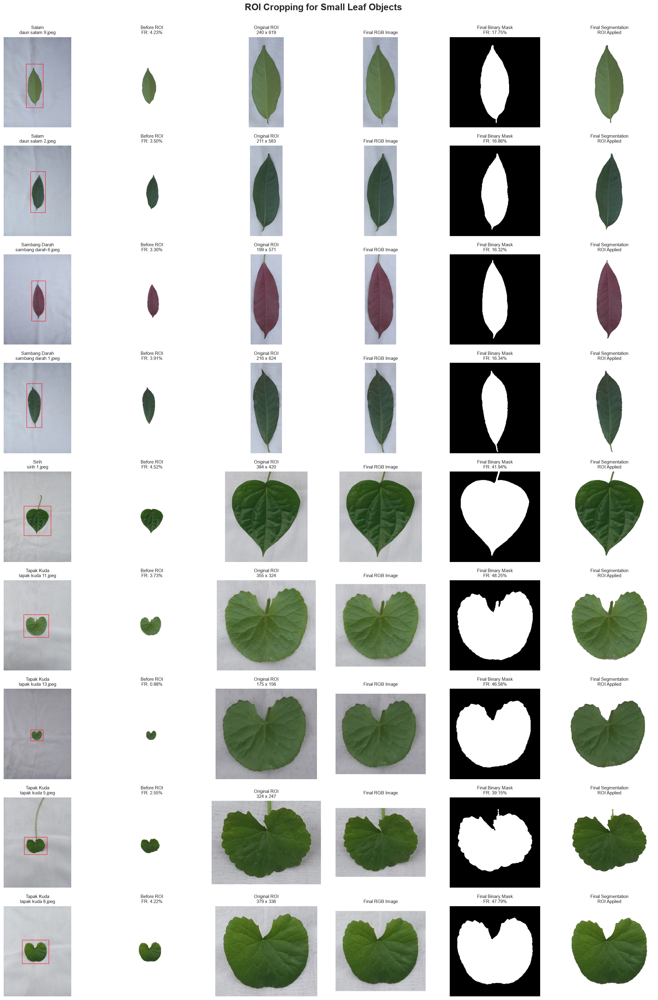


5. FINAL PREPROCESSING PER CLASS


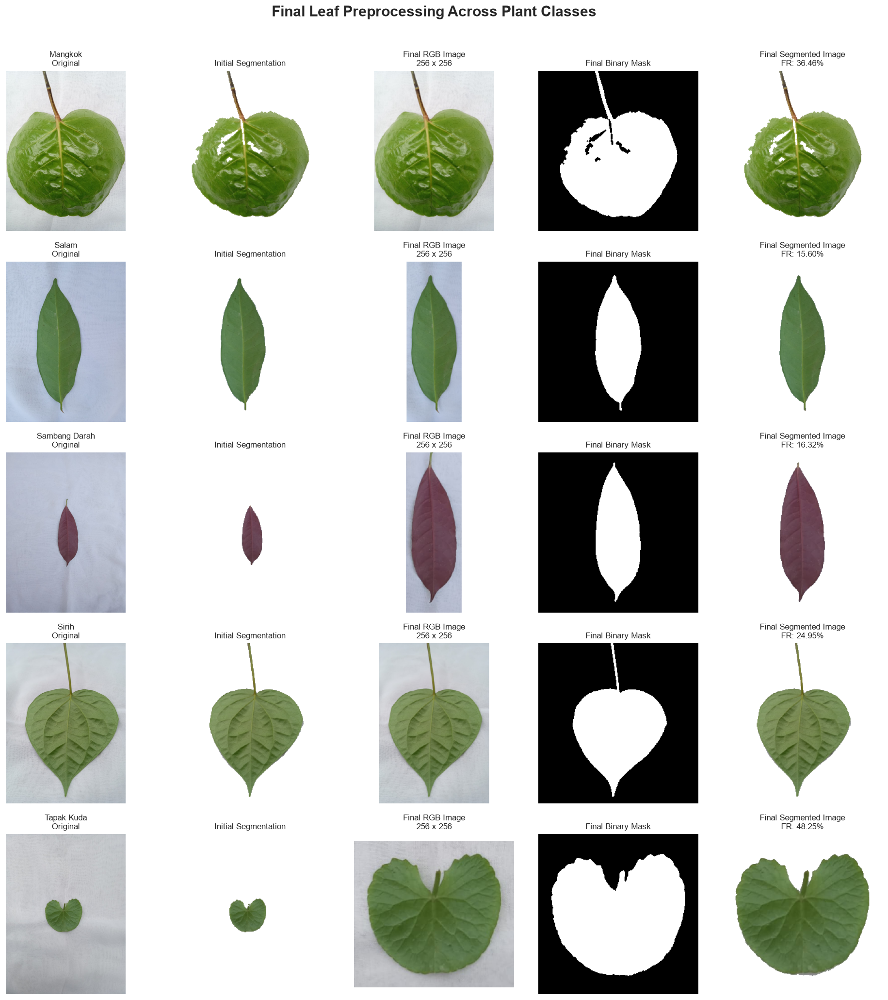


6. ROI ANALYSIS SUMMARY


,Indicator,Result
0,Total tested images,19.0000
1,ROI applied,19.0000
2,ROI not applied or rejected,0.0000
3,Technically valid outputs,19.0000
4,Technically invalid outputs,0.0000
5,Small foreground before ROI,9.0000
6,Small foreground after ROI,0.0000
7,Mean foreground ratio before,0.1359
8,Mean foreground ratio after,0.2940


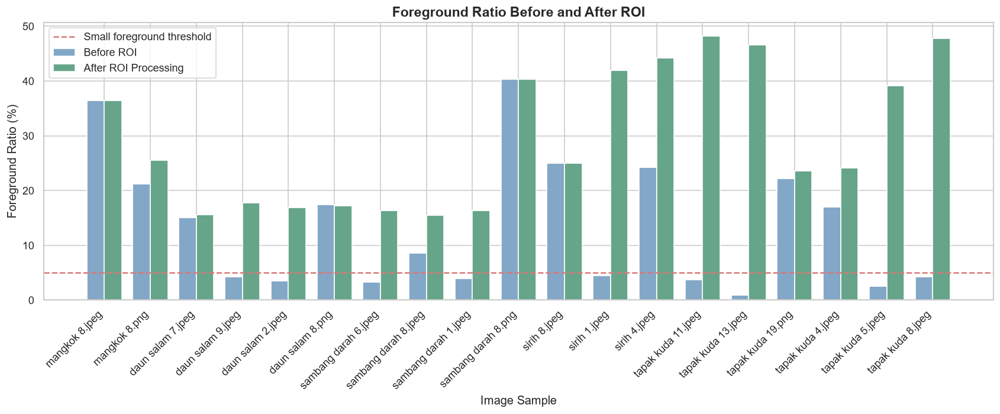


7. FINAL PREPROCESSING TEST SUMMARY
Total tested images       : 19
ROI successfully applied  : 19
ROI not applied/rejected : 0
Technically valid outputs: 19
Small foreground before  : 9
Small foreground after   : 0

Proposed configuration saved to:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\preprocessing_config_final.json

[INFO] Original dataset remains unchanged.
[INFO] ROI results require visual verification.
[INFO] Batch preprocessing has not been performed.

ROI cropping and final preprocessing test completed!


In [11]:
# ==================================================
# ROI CROPPING & FINAL PREPROCESSING VISUALIZATION
# ==================================================

print("ROI CROPPING & FINAL PREPROCESSING VISUALIZATION")
print("=" * 60)


# ==================================================
# 1. ROI CROPPING CONFIGURATION
# ==================================================

APPLY_ROI_CROPPING = True

# Add margin around the detected leaf
ROI_MARGIN_RATIO = 0.10

# Minimum acceptable ROI dimensions
MIN_ROI_WIDTH = 16
MIN_ROI_HEIGHT = 16

# Minimum foreground pixels
ROI_MIN_MASK_PIXELS = 100

# Minimum overlap with projected initial mask
ROI_MIN_MASK_OVERLAP = 0.60

# Number of samples per class
FINAL_PREVIEW_SAMPLES_PER_CLASS = 2


# ==================================================
# 2. GET FOREGROUND BOUNDING BOX
# ==================================================

def get_foreground_bbox(mask):

    foreground_points = cv2.findNonZero(
        mask.astype(np.uint8)
    )

    if foreground_points is None:
        return None

    x, y, width, height = cv2.boundingRect(
        foreground_points
    )

    return (
        int(x),
        int(y),
        int(width),
        int(height)
    )


# ==================================================
# 3. MAP BOUNDING BOX TO ORIGINAL IMAGE
# ==================================================

def map_bbox_to_original(
    bbox,
    resize_info,
    original_image_shape,
    margin_ratio=ROI_MARGIN_RATIO
):

    x, y, width, height = bbox

    original_height, original_width = (
        original_image_shape[:2]
    )

    pad_left = resize_info["pad_left"]
    pad_top = resize_info["pad_top"]

    # Use actual horizontal and vertical scale
    # to account for dimension rounding
    scale_x = (
        resize_info["resized_width"]
        / original_width
    )

    scale_y = (
        resize_info["resized_height"]
        / original_height
    )

    # Remove padding and map coordinates
    x1 = int(
        np.floor(
            (x - pad_left) / scale_x
        )
    )

    y1 = int(
        np.floor(
            (y - pad_top) / scale_y
        )
    )

    x2 = int(
        np.ceil(
            (x + width - pad_left) / scale_x
        )
    )

    y2 = int(
        np.ceil(
            (y + height - pad_top) / scale_y
        )
    )

    # Calculate ROI dimensions
    roi_width = x2 - x1
    roi_height = y2 - y1

    # Add margin around the leaf
    margin_x = int(
        np.ceil(roi_width * margin_ratio)
    )

    margin_y = int(
        np.ceil(roi_height * margin_ratio)
    )

    # Keep coordinates within image boundaries
    x1 = max(0, x1 - margin_x)
    y1 = max(0, y1 - margin_y)

    x2 = min(
        original_width,
        x2 + margin_x
    )

    y2 = min(
        original_height,
        y2 + margin_y
    )

    return x1, y1, x2, y2


# ==================================================
# 4. PROJECT INITIAL MASK TO ROI
# ==================================================

def project_mask_to_roi(
    initial_mask,
    resize_info,
    original_shape,
    roi_bbox,
    roi_resize_info
):

    original_height, original_width = (
        original_shape[:2]
    )

    # Remove artificial padding
    left = resize_info["pad_left"]
    top = resize_info["pad_top"]

    right = (
        left + resize_info["resized_width"]
    )

    bottom = (
        top + resize_info["resized_height"]
    )

    mask_without_padding = initial_mask[
        top:bottom,
        left:right
    ]

    # Map mask back to original resolution
    original_resolution_mask = cv2.resize(
        mask_without_padding,
        (original_width, original_height),
        interpolation=cv2.INTER_NEAREST
    )

    # Crop projected mask
    x1, y1, x2, y2 = roi_bbox

    cropped_mask = original_resolution_mask[
        y1:y2,
        x1:x2
    ]

    # Resize mask using the same ROI dimensions
    resized_mask = cv2.resize(
        cropped_mask,
        (
            roi_resize_info["resized_width"],
            roi_resize_info["resized_height"]
        ),
        interpolation=cv2.INTER_NEAREST
    )

    # Add black padding to the mask
    projected_mask = cv2.copyMakeBorder(
        resized_mask,

        roi_resize_info["pad_top"],
        roi_resize_info["pad_bottom"],
        roi_resize_info["pad_left"],
        roi_resize_info["pad_right"],

        borderType=cv2.BORDER_CONSTANT,
        value=0
    )

    # Ensure binary format
    projected_mask = np.where(
        projected_mask > 0,
        255,
        0
    ).astype(np.uint8)

    return projected_mask


# ==================================================
# 5. CALCULATE MASK OVERLAP
# ==================================================

def calculate_mask_iou(mask_a, mask_b):

    binary_a = mask_a > 0
    binary_b = mask_b > 0

    intersection = np.logical_and(
        binary_a,
        binary_b
    ).sum()

    union = np.logical_or(
        binary_a,
        binary_b
    ).sum()

    if union == 0:
        return 0.0

    return float(
        intersection / union
    )


# ==================================================
# 6. CREATE SEGMENTED RGB IMAGE
# ==================================================

def apply_leaf_mask(image, mask):

    segmented_image = np.full_like(
        image,
        255
    )

    segmented_image[mask > 0] = (
        image[mask > 0]
    )

    return segmented_image


# ==================================================
# 7. FINAL IMAGE PREPROCESSING FUNCTION
# ==================================================

def preprocess_leaf_image(
    original_image,
    apply_roi=APPLY_ROI_CROPPING
):

    # Preserve original RGB image
    working_image = original_image.copy()

    # Optional noise filtering
    if APPLY_DENOISING:

        working_image = cv2.medianBlur(
            working_image,
            MEDIAN_KERNEL_SIZE
        )

    # ----------------------------------------------
    # Initial resizing
    # ----------------------------------------------

    initial_resized, resize_info = (
        resize_with_padding(
            working_image
        )
    )

    # ----------------------------------------------
    # Initial refined segmentation
    # ----------------------------------------------

    (
        initial_segmented,
        initial_mask,
        initial_info,
        _
    ) = segment_leaf_refined(
        initial_resized,
        resize_info
    )

    # Initialize final outputs
    final_rgb = initial_resized.copy()

    final_mask = initial_mask.copy()

    final_segmented = (
        initial_segmented.copy()
    )

    final_info = initial_info.copy()

    roi_image = None
    roi_bbox = None
    roi_resize_info = None

    roi_applied = False

    roi_mask_overlap = np.nan

    roi_status = "ROI Disabled"

    # ----------------------------------------------
    # ROI cropping
    # ----------------------------------------------

    if apply_roi:

        roi_status = "ROI Not Applied"

        bbox = get_foreground_bbox(
            initial_mask
        )

        # Do not crop unreliable initial masks
        if not initial_info["eligible_mask"]:

            roi_status = "Initial Mask Ineligible"

        elif bbox is None:

            roi_status = "Empty Initial Mask"

        else:

            roi_bbox = map_bbox_to_original(
                bbox,
                resize_info,
                working_image.shape
            )

            x1, y1, x2, y2 = roi_bbox

            roi_width = x2 - x1

            roi_height = y2 - y1

            # Validate ROI dimensions
            if (
                roi_width < MIN_ROI_WIDTH
                or roi_height < MIN_ROI_HEIGHT
            ):

                roi_status = "ROI Too Small"

            else:

                # Crop from original-resolution image
                roi_image = working_image[
                    y1:y2,
                    x1:x2
                ].copy()

                # Resize cropped image
                roi_resized, roi_resize_info = (
                    resize_with_padding(
                        roi_image
                    )
                )

                # Project the initial mask
                projected_mask = (
                    project_mask_to_roi(
                        initial_mask,
                        resize_info,
                        working_image.shape,
                        roi_bbox,
                        roi_resize_info
                    )
                )

                # Re-segment the cropped image
                (
                    roi_segmented,
                    roi_mask,
                    roi_seg_info,
                    _
                ) = segment_leaf_refined(
                    roi_resized,
                    roi_resize_info
                )

                # Compare the new mask with
                # the projected initial mask
                roi_mask_overlap = (
                    calculate_mask_iou(
                        projected_mask,
                        roi_mask
                    )
                )

                # Validate ROI re-segmentation
                valid_roi_segmentation = (

                    roi_seg_info["eligible_mask"]

                    and np.count_nonzero(
                        roi_mask
                    ) >= ROI_MIN_MASK_PIXELS

                    and roi_mask_overlap
                    >= ROI_MIN_MASK_OVERLAP
                )

                if valid_roi_segmentation:

                    final_rgb = roi_resized

                    final_mask = roi_mask

                    final_segmented = (
                        roi_segmented
                    )

                    final_info = roi_seg_info

                    roi_applied = True

                    roi_status = (
                        "ROI Applied - Re-segmented"
                    )

                else:

                    # Preserve the original refined
                    # segmentation when ROI validation
                    # does not pass
                    roi_status = (
                        "ROI Rejected - Initial Mask Retained"
                    )

    # ----------------------------------------------
    # Final structural validation
    # ----------------------------------------------

    valid_output_dimensions = (
        final_rgb.shape[:2]
        == (TARGET_HEIGHT, TARGET_WIDTH)
    )

    valid_mask_dimensions = (
        final_mask.shape
        == (TARGET_HEIGHT, TARGET_WIDTH)
    )

    valid_binary_mask = set(
        np.unique(final_mask)
    ).issubset({0, 255})

    final_foreground_pixels = int(
        np.count_nonzero(final_mask)
    )

    final_foreground_ratio = (
        final_foreground_pixels
        / final_mask.size
    )

    technical_valid = (
        valid_output_dimensions

        and valid_mask_dimensions

        and valid_binary_mask

        and final_foreground_pixels
        >= ROI_MIN_MASK_PIXELS

        and final_info["eligible_mask"]
    )

    # ----------------------------------------------
    # Store preprocessing information
    # ----------------------------------------------

    preprocessing_info = {

        "original_width": (
            original_image.shape[1]
        ),

        "original_height": (
            original_image.shape[0]
        ),

        "output_width": (
            final_rgb.shape[1]
        ),

        "output_height": (
            final_rgb.shape[0]
        ),

        "initial_method": (
            initial_info["selected_method"]
        ),

        "final_method": (
            final_info["selected_method"]
        ),

        "initial_foreground_ratio": (
            initial_info["foreground_ratio"]
        ),

        "final_foreground_ratio": (
            float(final_foreground_ratio)
        ),

        "final_foreground_pixels": (
            final_foreground_pixels
        ),

        "final_border_ratio": (
            final_info["border_ratio"]
        ),

        "roi_applied": roi_applied,

        "roi_status": roi_status,

        "roi_mask_overlap": (
            roi_mask_overlap
        ),

        "roi_width": (
            roi_image.shape[1]
            if roi_image is not None
            else np.nan
        ),

        "roi_height": (
            roi_image.shape[0]
            if roi_image is not None
            else np.nan
        ),

        "valid_output_dimensions": (
            valid_output_dimensions
        ),

        "valid_mask_dimensions": (
            valid_mask_dimensions
        ),

        "valid_binary_mask": (
            valid_binary_mask
        ),

        "technical_valid": (
            technical_valid
        )
    }

    # Store intermediate outputs
    intermediate_results = {

        "original_image": (
            original_image
        ),

        "initial_resized": (
            initial_resized
        ),

        "initial_mask": (
            initial_mask
        ),

        "initial_segmented": (
            initial_segmented
        ),

        "roi_bbox": roi_bbox,

        "roi_image": roi_image,

        "roi_resize_info": (
            roi_resize_info
        ),

        "final_rgb": final_rgb,

        "final_mask": final_mask,

        "final_segmented": (
            final_segmented
        )
    }

    return (
        final_rgb,
        final_mask,
        final_segmented,
        preprocessing_info,
        intermediate_results
    )


# ==================================================
# 8. SELECT ROI TEST SAMPLES
# ==================================================

print("\n1. SELECTING ROI TEST SAMPLES")

# Prioritize all images with small foreground
small_foreground_df = refined_quality_df[
    refined_quality_df["foreground_ratio"]
    .lt(SMALL_FOREGROUND_REVIEW_RATIO)
].copy()

small_foreground_paths = (
    small_foreground_df["image_path"]
    .tolist()
)

# Select representative samples from each class
representative_samples = []

for plant_class in sorted(
    df_clean["kelas"].unique()
):

    class_subset = df_clean[
        df_clean["kelas"].eq(plant_class)
    ]

    # Select one front-view and one back-view image
    for leaf_view in ["depan", "belakang"]:

        view_subset = class_subset[
            class_subset["tampilan_daun"]
            .eq(leaf_view)
        ]

        if not view_subset.empty:

            sample = view_subset.sample(
                n=1,
                random_state=RANDOM_STATE
            ).iloc[0]

            representative_samples.append(
                sample["image_path"]
            )

# Combine both groups without duplicates
test_image_paths = list(
    dict.fromkeys(
        small_foreground_paths
        + representative_samples
    )
)

roi_test_samples = df_clean[
    df_clean["image_path"]
    .isin(test_image_paths)
].copy()

print(
    f"Small foreground images : "
    f"{len(small_foreground_df)}"
)

print(
    f"Total unique test images: "
    f"{len(roi_test_samples)}"
)


# ==================================================
# 9. TEST ROI PREPROCESSING
# ==================================================

print("\n2. TESTING ROI PREPROCESSING")

roi_test_records = []

roi_visual_results = {}

for _, row in tqdm(
    roi_test_samples.iterrows(),
    total=len(roi_test_samples),
    desc="Testing ROI preprocessing"
):

    try:

        original_image = load_image(
            row["absolute_image_path"]
        )

        (
            final_rgb,
            final_mask,
            final_segmented,
            preprocessing_info,
            intermediates
        ) = preprocess_leaf_image(
            original_image,
            apply_roi=True
        )

        # Calculate final image quality
        final_quality = (
            calculate_image_quality(
                final_rgb,
                final_mask
            )
        )

        roi_test_records.append({

            "nama_file": row["nama_file"],

            "image_path": row["image_path"],

            "kelas": row["kelas"],

            "tampilan_daun": (
                row["tampilan_daun"]
            ),

            **preprocessing_info,

            "final_blur_score": (
                final_quality["blur_score"]
            ),

            "final_brightness": (
                final_quality["mean_brightness"]
            ),

            "final_contrast": (
                final_quality["contrast"]
            ),

            "error": ""
        })

        roi_visual_results[
            row["image_path"]
        ] = {

            "nama_file": row["nama_file"],

            "kelas": row["kelas"],

            "tampilan_daun": (
                row["tampilan_daun"]
            ),

            "info": preprocessing_info,

            **intermediates
        }

    except Exception as error:

        roi_test_records.append({

            "nama_file": row["nama_file"],

            "image_path": row["image_path"],

            "kelas": row["kelas"],

            "roi_applied": False,

            "roi_status": "Processing Failed",

            "technical_valid": False,

            "error": str(error)
        })


roi_test_df = pd.DataFrame(
    roi_test_records
)

# Ensure required columns exist
expected_result_columns = [
    "initial_foreground_ratio",
    "final_foreground_ratio",
    "final_foreground_pixels",
    "final_border_ratio",
    "roi_mask_overlap",
    "roi_width",
    "roi_height",
    "final_blur_score",
    "final_brightness",
    "final_contrast"
]

for column in expected_result_columns:

    if column not in roi_test_df.columns:

        roi_test_df[column] = np.nan


# ==================================================
# 10. DISPLAY ROI TEST RESULTS
# ==================================================

print("\n3. ROI PREPROCESSING TEST RESULTS")

display(
    roi_test_df[
        [
            "nama_file",
            "kelas",
            "initial_foreground_ratio",
            "final_foreground_ratio",
            "roi_mask_overlap",
            "roi_applied",
            "roi_status",
            "technical_valid"
        ]
    ].round(4)
)


# ==================================================
# 11. VISUALIZE SMALL FOREGROUND IMAGES
# ==================================================

print("\n4. SMALL FOREGROUND ROI COMPARISON")

small_roi_results = [

    result

    for image_path, result
    in roi_visual_results.items()

    if image_path in small_foreground_paths
]

n_small_images = len(
    small_roi_results
)

if n_small_images > 0:

    fig, axes = plt.subplots(
        n_small_images,
        6,
        figsize=(19, 3.1 * n_small_images),
        squeeze=False
    )

    for row_index, result in enumerate(
        small_roi_results
    ):

        info = result["info"]

        # Original image with ROI bounding box
        original_preview = result[
            "original_image"
        ].copy()

        if result["roi_bbox"] is not None:

            x1, y1, x2, y2 = (
                result["roi_bbox"]
            )

            thickness = max(
                2,
                int(
                    max(
                        original_preview.shape[:2]
                    ) / 300
                )
            )

            cv2.rectangle(
                original_preview,
                (x1, y1),
                (x2 - 1, y2 - 1),
                (255, 0, 0),
                thickness
            )

        axes[row_index, 0].imshow(
            original_preview
        )

        axes[row_index, 0].set_title(
            f"{result['kelas']}\n"
            f"{result['nama_file']}",
            fontsize=9
        )

        # Initial segmentation
        axes[row_index, 1].imshow(
            result["initial_segmented"]
        )

        axes[row_index, 1].set_title(
            "Before ROI\n"
            f"FR: "
            f"{info['initial_foreground_ratio']:.2%}",
            fontsize=9
        )

        # Cropped original image
        if result["roi_image"] is not None:

            axes[row_index, 2].imshow(
                result["roi_image"]
            )

            axes[row_index, 2].set_title(
                "Original ROI\n"
                f"{result['roi_image'].shape[1]} x "
                f"{result['roi_image'].shape[0]}",
                fontsize=9
            )

        else:

            axes[row_index, 2].text(
                0.5,
                0.5,
                "ROI Not Available",
                ha="center",
                va="center"
            )

        # Final RGB image
        axes[row_index, 3].imshow(
            result["final_rgb"]
        )

        axes[row_index, 3].set_title(
            "Final RGB Image",
            fontsize=9
        )

        # Final binary mask
        axes[row_index, 4].imshow(
            result["final_mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row_index, 4].set_title(
            "Final Binary Mask\n"
            f"FR: "
            f"{info['final_foreground_ratio']:.2%}",
            fontsize=9
        )

        # Final segmented image
        axes[row_index, 5].imshow(
            result["final_segmented"]
        )

        roi_label = (
            "ROI Applied"
            if info["roi_applied"]
            else "Initial Result Retained"
        )

        axes[row_index, 5].set_title(
            f"Final Segmentation\n{roi_label}",
            fontsize=9
        )

        for ax in axes[row_index]:

            ax.axis("off")

    fig.suptitle(
        "ROI Cropping for Small Leaf Objects",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.98]
    )

    plt.savefig(
        FIGURES_DIR /
        "16_roi_small_foreground_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ==================================================
# 12. FINAL PREPROCESSING VISUALIZATION
# ==================================================

print("\n5. FINAL PREPROCESSING PER CLASS")

# One representative image per class
final_preview_results = []

for plant_class in sorted(
    df_clean["kelas"].unique()
):

    class_results = [

        result

        for result
        in roi_visual_results.values()

        if result["kelas"] == plant_class
    ]

    if class_results:

        # Prefer a technically valid result
        valid_results = [

            result

            for result in class_results

            if result["info"]["technical_valid"]
        ]

        available_results = (
            valid_results
            if valid_results
            else class_results
        )

        final_preview_results.append(
            available_results[0]
        )


if final_preview_results:

    fig, axes = plt.subplots(
        len(final_preview_results),
        5,
        figsize=(
            16,
            3.5 * len(final_preview_results)
        ),
        squeeze=False
    )

    for row_index, result in enumerate(
        final_preview_results
    ):

        info = result["info"]

        axes[row_index, 0].imshow(
            result["original_image"]
        )

        axes[row_index, 0].set_title(
            f"{result['kelas']}\nOriginal",
            fontsize=10
        )

        axes[row_index, 1].imshow(
            result["initial_segmented"]
        )

        axes[row_index, 1].set_title(
            "Initial Segmentation",
            fontsize=10
        )

        axes[row_index, 2].imshow(
            result["final_rgb"]
        )

        axes[row_index, 2].set_title(
            "Final RGB Image\n256 x 256",
            fontsize=10
        )

        axes[row_index, 3].imshow(
            result["final_mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row_index, 3].set_title(
            "Final Binary Mask",
            fontsize=10
        )

        axes[row_index, 4].imshow(
            result["final_segmented"]
        )

        axes[row_index, 4].set_title(
            "Final Segmented Image\n"
            f"FR: "
            f"{info['final_foreground_ratio']:.2%}",
            fontsize=10
        )

        for ax in axes[row_index]:

            ax.axis("off")

    fig.suptitle(
        "Final Leaf Preprocessing Across Plant Classes",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.97]
    )

    plt.savefig(
        FIGURES_DIR /
        "17_final_preprocessing_per_class.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ==================================================
# 13. ANALYZE ROI RESULTS
# ==================================================

print("\n6. ROI ANALYSIS SUMMARY")

roi_applied_count = int(
    roi_test_df["roi_applied"]
    .eq(True)
    .sum()
)

technical_valid_count = int(
    roi_test_df["technical_valid"]
    .eq(True)
    .sum()
)

small_before_count = int(
    roi_test_df[
        "initial_foreground_ratio"
    ].lt(
        SMALL_FOREGROUND_REVIEW_RATIO
    ).sum()
)

small_after_count = int(
    roi_test_df[
        "final_foreground_ratio"
    ].lt(
        SMALL_FOREGROUND_REVIEW_RATIO
    ).sum()
)

roi_test_df["foreground_ratio_change"] = (

    roi_test_df["final_foreground_ratio"]

    - roi_test_df["initial_foreground_ratio"]
)

roi_summary = pd.DataFrame({

    "Indicator": [

        "Total tested images",

        "ROI applied",

        "ROI not applied or rejected",

        "Technically valid outputs",

        "Technically invalid outputs",

        "Small foreground before ROI",

        "Small foreground after ROI",

        "Mean foreground ratio before",

        "Mean foreground ratio after"
    ],

    "Result": [

        len(roi_test_df),

        roi_applied_count,

        len(roi_test_df)
        - roi_applied_count,

        technical_valid_count,

        len(roi_test_df)
        - technical_valid_count,

        small_before_count,

        small_after_count,

        roi_test_df[
            "initial_foreground_ratio"
        ].mean(),

        roi_test_df[
            "final_foreground_ratio"
        ].mean()
    ]
})

display(
    roi_summary.round(4)
)


# ==================================================
# 14. VISUALIZE FOREGROUND RATIO COMPARISON
# ==================================================

plot_df = roi_test_df.dropna(
    subset=[
        "initial_foreground_ratio",
        "final_foreground_ratio"
    ]
).copy()

if not plot_df.empty:

    x_positions = np.arange(
        len(plot_df)
    )

    bar_width = 0.38

    fig, ax = plt.subplots(
        figsize=(
            max(13, len(plot_df) * 0.75),
            6
        )
    )

    ax.bar(
        x_positions - bar_width / 2,
        plot_df[
            "initial_foreground_ratio"
        ] * 100,
        bar_width,
        label="Before ROI",
        color="#83A7C7"
    )

    ax.bar(
        x_positions + bar_width / 2,
        plot_df[
            "final_foreground_ratio"
        ] * 100,
        bar_width,
        label="After ROI Processing",
        color="#66A58A"
    )

    ax.axhline(
        SMALL_FOREGROUND_REVIEW_RATIO * 100,
        color="#D97878",
        linestyle="--",
        label="Small foreground threshold"
    )

    ax.set_title(
        "Foreground Ratio Before and After ROI",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Foreground Ratio (%)"
    )

    ax.set_xlabel(
        "Image Sample"
    )

    ax.set_xticks(
        x_positions
    )

    ax.set_xticklabels(
        plot_df["nama_file"],
        rotation=45,
        ha="right"
    )

    ax.legend()

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR /
        "18_roi_foreground_ratio_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ==================================================
# 15. SAVE ROI TEST RESULTS
# ==================================================

roi_test_df.to_csv(
    METRICS_DIR /
    "40_roi_preprocessing_test.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_summary.to_csv(
    METRICS_DIR /
    "41_roi_preprocessing_summary.csv",
    index=False
)

roi_review_df = roi_test_df[
    ~roi_test_df["roi_applied"].eq(True)

    | ~roi_test_df["technical_valid"].eq(True)
].copy()

roi_review_df.to_csv(
    METRICS_DIR /
    "42_roi_review_records.csv",
    index=False,
    encoding="utf-8-sig"
)


# ==================================================
# 16. SAVE PROPOSED FINAL CONFIGURATION
# ==================================================

final_preprocessing_config = {

    **refined_config,

    "apply_roi_cropping": (
        APPLY_ROI_CROPPING
    ),

    "roi_margin_ratio": (
        ROI_MARGIN_RATIO
    ),

    "min_roi_width": (
        MIN_ROI_WIDTH
    ),

    "min_roi_height": (
        MIN_ROI_HEIGHT
    ),

    "roi_min_mask_pixels": (
        ROI_MIN_MASK_PIXELS
    ),

    "roi_min_mask_overlap": (
        ROI_MIN_MASK_OVERLAP
    ),

    "roi_source": (
        "Original Resolution"
    ),

    "roi_mask_interpolation": (
        "INTER_NEAREST"
    ),

    "roi_resegmentation": True,

    "roi_fallback": (
        "Retain Initial Refined Segmentation"
    ),

    "configuration_status": (
        "Pending Visual Verification"
    )
}

FINAL_CONFIG_PATH = (
    PROCESSED_DIR /
    "preprocessing_config_final.json"
)

with open(
    FINAL_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        final_preprocessing_config,
        file,
        indent=4
    )


# ==================================================
# 17. FINAL SUMMARY
# ==================================================

print("\n7. FINAL PREPROCESSING TEST SUMMARY")
print("=" * 60)

print(
    f"Total tested images       : "
    f"{len(roi_test_df)}"
)

print(
    f"ROI successfully applied  : "
    f"{roi_applied_count}"
)

print(
    f"ROI not applied/rejected : "
    f"{len(roi_test_df) - roi_applied_count}"
)

print(
    f"Technically valid outputs: "
    f"{technical_valid_count}"
)

print(
    f"Small foreground before  : "
    f"{small_before_count}"
)

print(
    f"Small foreground after   : "
    f"{small_after_count}"
)

print("\nProposed configuration saved to:")

print(FINAL_CONFIG_PATH)

print(
    "\n[INFO] Original dataset remains unchanged."
)

print(
    "[INFO] ROI results require visual verification."
)

print(
    "[INFO] Batch preprocessing has not been performed."
)

print(
    "\nROI cropping and final preprocessing test completed!"
)

BATCH IMAGE PREPROCESSING

1. BATCH PROCESSING CONFIGURATION
Candidate images : 104
Target size      : (256, 256)
ROI cropping     : True
Mask hole filling: True

2. PROCESSING ALL CANDIDATE IMAGES


Batch preprocessing:   0%|          | 0/104 [00:00<?, ?it/s]

C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(



3. BATCH PROCESSING RESULTS


C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21256\2403794674.py:303: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(


,nama_file,kelas,roi_applied,final_foreground_ratio,hole_filling_applied,processing_success,batch_status
0,mangkok 10.jpeg,Mangkok,True,0.4201,False,True,Passed Initial Check
1,mangkok 11.png,Mangkok,True,0.2509,False,True,Passed Initial Check
2,mangkok 12.png,Mangkok,True,0.2539,False,True,Passed Initial Check
3,mangkok 13.png,Mangkok,True,0.2849,False,True,Passed Initial Check
4,mangkok 14.png,Mangkok,True,0.2592,False,True,Passed Initial Check
5,mangkok 15.png,Mangkok,True,0.2709,False,True,Passed Initial Check
6,mangkok 6.jpeg,Mangkok,True,0.2106,False,True,Passed Initial Check
7,mangkok 7.jpeg,Mangkok,True,0.4885,False,True,Passed Initial Check
8,mangkok 8.jpeg,Mangkok,True,0.3671,True,True,Needs Review
9,mangkok 9.jpeg,Mangkok,True,0.4744,True,True,Needs Review


... (2 outputs left out)


5. BATCH PREPROCESSING SUMMARY


,Indicator,Result
0,Total candidate images,104.0
1,Successfully processed images,104.0
2,Failed processing,0.0
3,Passed initial check,54.0
4,Images requiring review,50.0
5,ROI applied,103.0
6,Images with hole filling,8.0
7,Total internal holes filled,21.0
8,Images with remaining internal holes,3.0
9,Small foreground images,0.0



6. PREPROCESSING RESULTS PER CLASS


batch_status,Passed Initial Check,Needs Review,Failed,Total
kelas,,,,
Mangkok,14,6,0,20
Salam,9,10,0,19
Sambang Darah,7,13,0,20
Sirih,13,7,0,20
Tapak Kuda,11,14,0,25


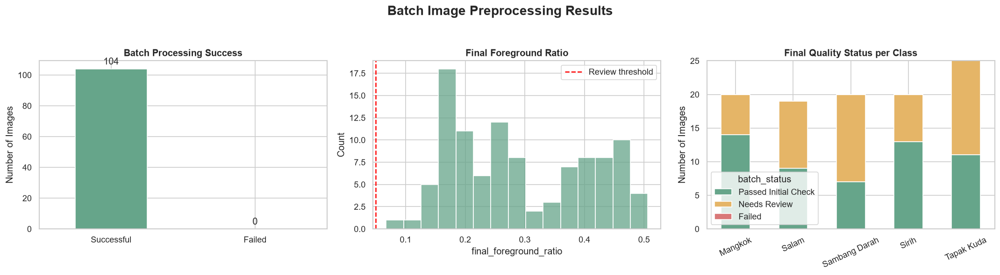


7. GENERATING VISUAL REVIEW PAGES


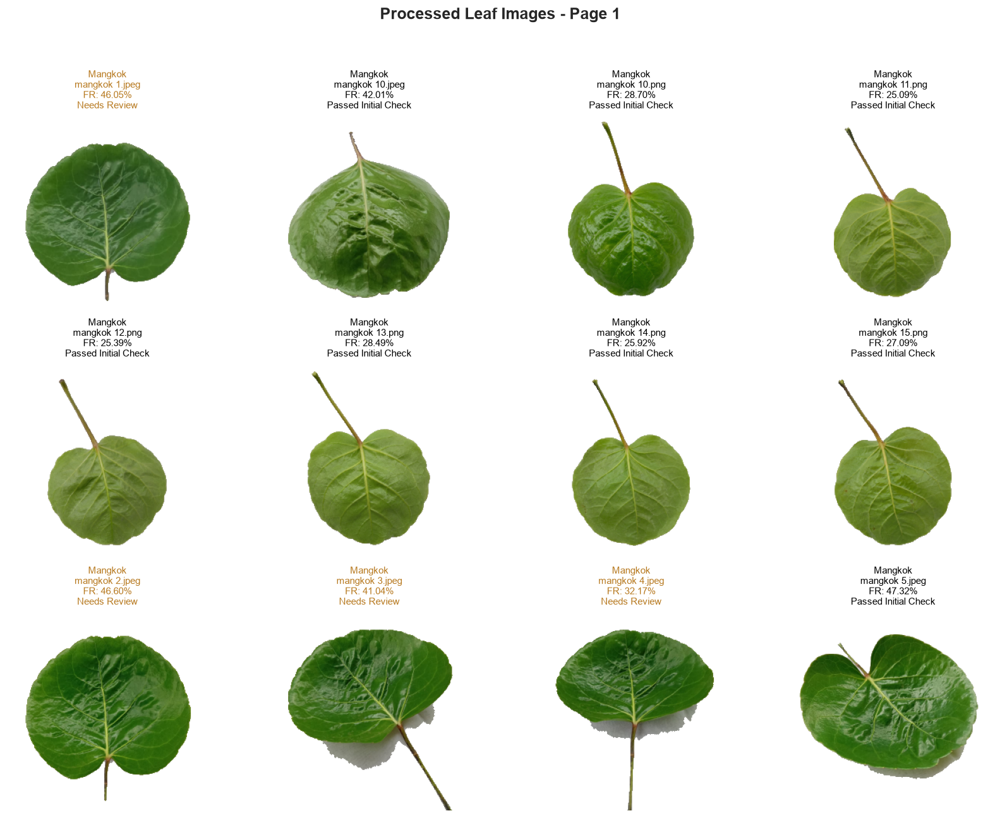

Visualization pages generated: 9

8. FINAL BATCH PREPROCESSING SUMMARY
Total candidates       : 104
Successfully processed : 104
Failed processing      : 0
Success rate           : 100.00%
Passed initial check   : 54
Needs review           : 50
ROI applied            : 103
Hole filling applied   : 8
Remaining mask holes   : 3 images
Small foreground       : 0
Excessive border ratio : 0
Visualization pages    : 9

Processed metadata:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_image_processed.csv

Processed images:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\images

Binary masks:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\masks

[PASS] All candidate images were successfully processed.
[REVIEW] Some outputs require manual visual inspection.

Original dataset has not been modified.

Batch image preprocessing completed!

Next cell: Cell 12 - Text Cleaning and Case Folding


In [12]:
# ==================================================
# BATCH IMAGE PREPROCESSING
# ==================================================

print("BATCH IMAGE PREPROCESSING")
print("=" * 60)


# ==================================================
# 1. FINAL MASK REFINEMENT CONFIGURATION
# ==================================================

APPLY_CONTROLLED_HOLE_FILLING = True

# Maximum size of an individual hole
MAX_INTERNAL_HOLE_PIXELS = 128

# Maximum individual hole relative to leaf area
MAX_INTERNAL_HOLE_RATIO = 0.01

# Maximum total area that may be filled
MAX_TOTAL_FILL_RATIO = 0.02

# Number of images per visualization page
BATCH_PREVIEW_SIZE = 12


# ==================================================
# 2. CONTROLLED INTERNAL HOLE FILLING
# ==================================================

def refine_internal_mask_holes(mask):

    binary_mask = np.where(
        mask > 0, 255, 0
    ).astype(np.uint8)

    refined_mask = binary_mask.copy()

    foreground_pixels = int(
        np.count_nonzero(binary_mask)
    )

    # Identify background components
    inverse_mask = (
        binary_mask == 0
    ).astype(np.uint8)

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            inverse_mask,
            connectivity=8
        )
    )

    # Background components touching image boundaries
    # are not considered internal holes
    boundary_labels = set(
        np.concatenate([
            labels[0, :],
            labels[-1, :],
            labels[:, 0],
            labels[:, -1]
        ]).tolist()
    )

    internal_holes = []

    for label in range(1, num_labels):

        if label not in boundary_labels:

            hole_area = int(
                stats[label, cv2.CC_STAT_AREA]
            )

            internal_holes.append(
                (label, hole_area)
            )

    # Fill smaller holes first
    internal_holes.sort(
        key=lambda item: item[1]
    )

    max_single_hole = min(
        MAX_INTERNAL_HOLE_PIXELS,
        int(
            foreground_pixels
            * MAX_INTERNAL_HOLE_RATIO
        )
    )

    max_total_fill = int(
        foreground_pixels
        * MAX_TOTAL_FILL_RATIO
    )

    filled_holes = 0
    filled_pixels = 0

    for label, hole_area in internal_holes:

        if (
            APPLY_CONTROLLED_HOLE_FILLING

            and hole_area <= max_single_hole

            and filled_pixels + hole_area
            <= max_total_fill
        ):

            refined_mask[
                labels == label
            ] = 255

            filled_holes += 1
            filled_pixels += hole_area

    remaining_holes = (
        len(internal_holes) - filled_holes
    )

    hole_info = {

        "internal_holes_before": (
            len(internal_holes)
        ),

        "internal_holes_filled": (
            filled_holes
        ),

        "filled_hole_pixels": (
            filled_pixels
        ),

        "remaining_internal_holes": (
            remaining_holes
        ),

        "hole_filling_applied": (
            filled_holes > 0
        )
    }

    return refined_mask, hole_info


# ==================================================
# 3. FINAL PREPROCESSING WRAPPER
# ==================================================

def preprocess_leaf_image_final(original_image):

    # Apply the pipeline developed in Cell 10C
    (
        final_rgb,
        final_mask,
        final_segmented,
        preprocessing_info,
        intermediates
    ) = preprocess_leaf_image(
        original_image,
        apply_roi=APPLY_ROI_CROPPING
    )

    # Inspect and refine internal mask holes
    refined_mask, hole_info = (
        refine_internal_mask_holes(
            final_mask
        )
    )

    # Determine the valid image region
    if preprocessing_info["roi_applied"]:

        final_resize_info = intermediates[
            "roi_resize_info"
        ]

    else:

        _, final_resize_info = (
            resize_with_padding(
                original_image
            )
        )

    valid_region = create_valid_region(
        final_rgb,
        final_resize_info
    )

    # Ensure artificial padding remains excluded
    refined_mask = cv2.bitwise_and(
        refined_mask,
        valid_region
    )

    # Recalculate mask quality
    final_mask_quality = (
        calculate_refined_mask_quality(
            refined_mask,
            valid_region
        )
    )

    # Create final segmented preview
    final_segmented = apply_leaf_mask(
        final_rgb,
        refined_mask
    )

    # Calculate final image quality
    final_image_quality = (
        calculate_image_quality(
            final_rgb,
            refined_mask
        )
    )

    # Validate dimensions
    valid_image_dimensions = (
        final_rgb.shape
        == (TARGET_HEIGHT, TARGET_WIDTH, 3)
    )

    valid_mask_dimensions = (
        refined_mask.shape
        == (TARGET_HEIGHT, TARGET_WIDTH)
    )

    valid_binary_mask = set(
        np.unique(refined_mask)
    ).issubset({0, 255})

    # Determine technical validity
    image_preprocessing_valid = (

        preprocessing_info["technical_valid"]

        and valid_image_dimensions

        and valid_mask_dimensions

        and valid_binary_mask

        and final_mask_quality["eligible_mask"]
    )

    # Collect final review indicators
    quality_issues = []

    if not image_preprocessing_valid:

        quality_issues.append(
            "Invalid preprocessing output"
        )

    if (
        final_mask_quality["foreground_ratio"]
        < SMALL_FOREGROUND_REVIEW_RATIO
    ):

        quality_issues.append(
            "Small foreground"
        )

    if (
        APPLY_ROI_CROPPING
        and not preprocessing_info["roi_applied"]
    ):

        quality_issues.append(
            "ROI not applied or rejected"
        )

    if hole_info["remaining_internal_holes"] > 0:

        quality_issues.append(
            "Remaining internal mask holes"
        )

    if hole_info["hole_filling_applied"]:

        quality_issues.append(
            "Mask hole filling requires review"
        )

    if final_image_quality["is_blurry"]:

        quality_issues.append(
            "Potential blur"
        )

    if final_image_quality["is_low_contrast"]:

        quality_issues.append(
            "Low contrast"
        )

    if final_image_quality["is_dark"]:

        quality_issues.append(
            "Low brightness"
        )

    if final_image_quality["is_bright"]:

        quality_issues.append(
            "High brightness"
        )

    if not final_image_quality["quality_measurable"]:

        quality_issues.append(
            "Insufficient quality measurement pixels"
        )

    # Assign batch processing status
    if not image_preprocessing_valid:

        batch_status = "Failed"

    elif quality_issues:

        batch_status = "Needs Review"

    else:

        batch_status = "Passed Initial Check"

    # Combine preprocessing information
    final_info = {

        **preprocessing_info,

        **hole_info,

        "final_foreground_ratio": (
            final_mask_quality["foreground_ratio"]
        ),

        "final_foreground_pixels": (
            final_mask_quality["foreground_pixels"]
        ),

        "final_border_ratio": (
            final_mask_quality["border_ratio"]
        ),

        "final_valid_region_ratio": (
            final_mask_quality["valid_region_ratio"]
        ),

        "final_mask_eligible": (
            final_mask_quality["eligible_mask"]
        ),

        "final_blur_score": (
            final_image_quality["blur_score"]
        ),

        "final_brightness": (
            final_image_quality["mean_brightness"]
        ),

        "final_contrast": (
            final_image_quality["contrast"]
        ),

        "valid_output_dimensions": (
            valid_image_dimensions
        ),

        "valid_mask_dimensions": (
            valid_mask_dimensions
        ),

        "valid_binary_mask": (
            valid_binary_mask
        ),

        "technical_valid": (
            image_preprocessing_valid
        ),

        "batch_status": batch_status,

        "image_quality_issues": (
            "; ".join(quality_issues)
            if quality_issues
            else "None"
        )
    }

    return (
        final_rgb,
        refined_mask,
        final_segmented,
        final_info
    )


# ==================================================
# 4. PREPARE BATCH OUTPUT DIRECTORIES
# ==================================================

BATCH_PREVIEW_DIR = (
    FIGURES_DIR / "batch_preprocessing"
)

BATCH_PREVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PROCESSED_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MASK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\n1. BATCH PROCESSING CONFIGURATION")

print(f"Candidate images : {len(df_clean)}")
print(f"Target size      : {TARGET_SIZE}")
print(f"ROI cropping     : {APPLY_ROI_CROPPING}")

print(
    "Mask hole filling: "
    f"{APPLY_CONTROLLED_HOLE_FILLING}"
)

# Ensure each metadata record has a unique source path
assert df_clean["image_path"].is_unique, (
    "Duplicate image paths detected."
)


# ==================================================
# 5. PROCESS ALL CANDIDATE IMAGES
# ==================================================

print("\n2. PROCESSING ALL CANDIDATE IMAGES")

batch_records = []

for _, row in tqdm(
    df_clean.iterrows(),
    total=len(df_clean),
    desc="Batch preprocessing"
):

    # Initialize output record
    record = {

        "nama_file": row["nama_file"],

        "image_path": row["image_path"],

        "kelas": row["kelas"],

        "tampilan_daun": (
            row["tampilan_daun"]
        ),

        "processed_image_path": "",

        "mask_path": "",

        "processing_success": False,

        "batch_status": "Failed",

        "roi_applied": False,

        "hole_filling_applied": False,

        "internal_holes_filled": 0,

        "remaining_internal_holes": np.nan,

        "final_foreground_ratio": np.nan,

        "final_foreground_pixels": np.nan,

        "final_border_ratio": np.nan,

        "image_quality_issues": "",

        "error": ""
    }

    try:

        # Load original image
        original_image = load_image(
            row["absolute_image_path"]
        )

        # Apply final preprocessing pipeline
        (
            processed_rgb,
            binary_mask,
            segmented_preview,
            final_info
        ) = preprocess_leaf_image_final(
            original_image
        )

        record.update(final_info)

        # Do not save invalid outputs
        if not final_info["technical_valid"]:

            raise ValueError(
                "Image or mask failed final validation."
            )

        # Preserve original directory structure
        source_path = Path(
            row["absolute_image_path"]
        ).resolve()

        relative_source = source_path.relative_to(
            RAW_DIR.resolve()
        )

        # Preserve original extension in output name
        # to prevent JPEG/PNG filename collisions
        output_filename = (
            relative_source.name + ".png"
        )

        image_output_path = (

            PROCESSED_IMAGE_DIR

            / relative_source.parent

            / output_filename
        )

        mask_output_path = (

            MASK_DIR

            / relative_source.parent

            / output_filename
        )

        # Create parent directories
        image_output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        mask_output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        # Save unmasked RGB image
        Image.fromarray(
            processed_rgb.astype(np.uint8)
        ).save(
            image_output_path,
            format="PNG"
        )

        # Save binary mask separately
        Image.fromarray(
            binary_mask.astype(np.uint8)
        ).save(
            mask_output_path,
            format="PNG"
        )

        # Verify saved RGB image
        with Image.open(
            image_output_path
        ) as saved_image:

            saved_rgb = np.array(
                saved_image.convert("RGB")
            )

        # Verify saved mask
        with Image.open(
            mask_output_path
        ) as saved_mask:

            saved_binary_mask = np.array(
                saved_mask.convert("L")
            )

        if not np.array_equal(
            saved_rgb,
            processed_rgb
        ):

            raise ValueError(
                "Saved RGB image verification failed."
            )

        if not np.array_equal(
            saved_binary_mask,
            binary_mask
        ):

            raise ValueError(
                "Saved mask verification failed."
            )

        # Store portable relative paths
        record["processed_image_path"] = (
            image_output_path
            .relative_to(PROJECT_ROOT)
            .as_posix()
        )

        record["mask_path"] = (
            mask_output_path
            .relative_to(PROJECT_ROOT)
            .as_posix()
        )

        record["processing_success"] = True

    except Exception as error:

        record["processing_success"] = False

        record["batch_status"] = "Failed"

        record["processed_image_path"] = ""

        record["mask_path"] = ""

        record["error"] = str(error)

    batch_records.append(record)


# ==================================================
# 6. CREATE BATCH RESULTS DATAFRAME
# ==================================================

batch_results_df = pd.DataFrame(
    batch_records
)

successful_batch_df = batch_results_df[
    batch_results_df["processing_success"]
    .eq(True)
].copy()

failed_batch_df = batch_results_df[
    ~batch_results_df["processing_success"]
    .eq(True)
].copy()

batch_review_df = batch_results_df[
    batch_results_df["batch_status"]
    .eq("Needs Review")
].copy()

print("\n3. BATCH PROCESSING RESULTS")

display(
    batch_results_df[
        [
            "nama_file",
            "kelas",
            "roi_applied",
            "final_foreground_ratio",
            "hole_filling_applied",
            "processing_success",
            "batch_status"
        ]
    ].head(10).round(4)
)


# ==================================================
# 7. MERGE RESULTS WITH MULTIMODAL METADATA
# ==================================================

batch_metadata_columns = [
    "image_path",
    "processed_image_path",
    "mask_path",
    "processing_success",
    "batch_status",
    "roi_applied",
    "final_foreground_ratio",
    "final_foreground_pixels",
    "final_border_ratio",
    "hole_filling_applied",
    "remaining_internal_holes",
    "image_quality_issues"
]

df_batch = df_clean.merge(

    batch_results_df[
        batch_metadata_columns
    ],

    on="image_path",

    how="left",

    validate="one_to_one"
)

# Retain successfully processed image-text pairs
df_image_processed = df_batch[
    df_batch["processing_success"]
    .eq(True)
].copy().reset_index(drop=True)

assert len(df_batch) == len(df_clean)

assert len(df_image_processed) == len(
    successful_batch_df
)

print("\n4. PROCESSED MULTIMODAL METADATA")

display(
    df_image_processed[
        [
            "nama_file",
            "kelas",
            "tampilan_daun",
            "processed_image_path",
            "mask_path",
            "batch_status"
        ]
    ].head()
)


# ==================================================
# 8. BATCH PREPROCESSING STATISTICS
# ==================================================

total_candidates = len(df_clean)

successful_count = len(successful_batch_df)

failed_count = len(failed_batch_df)

batch_passed_count = int(
    batch_results_df["batch_status"]
    .eq("Passed Initial Check")
    .sum()
)

batch_review_count = len(batch_review_df)

roi_success_count = int(
    successful_batch_df["roi_applied"]
    .eq(True)
    .sum()
)

hole_filling_count = int(
    successful_batch_df["hole_filling_applied"]
    .eq(True)
    .sum()
)

remaining_hole_count = int(
    successful_batch_df[
        "remaining_internal_holes"
    ].gt(0).sum()
)

small_foreground_count = int(
    successful_batch_df[
        "final_foreground_ratio"
    ].lt(
        SMALL_FOREGROUND_REVIEW_RATIO
    ).sum()
)

excessive_border_count = int(
    successful_batch_df[
        "final_border_ratio"
    ].gt(
        REFINED_MAX_BORDER_RATIO
    ).sum()
)

success_rate = (
    successful_count / total_candidates * 100
    if total_candidates > 0
    else 0
)

batch_summary = pd.DataFrame({

    "Indicator": [
        "Total candidate images",
        "Successfully processed images",
        "Failed processing",
        "Passed initial check",
        "Images requiring review",
        "ROI applied",
        "Images with hole filling",
        "Total internal holes filled",
        "Images with remaining internal holes",
        "Small foreground images",
        "Excessive border ratio",
        "Processing success rate (%)"
    ],

    "Result": [
        total_candidates,
        successful_count,
        failed_count,
        batch_passed_count,
        batch_review_count,
        roi_success_count,
        hole_filling_count,

        successful_batch_df[
            "internal_holes_filled"
        ].sum(),

        remaining_hole_count,
        small_foreground_count,
        excessive_border_count,
        round(success_rate, 2)
    ]
})

print("\n5. BATCH PREPROCESSING SUMMARY")

display(batch_summary)


# ==================================================
# 9. CLASS DISTRIBUTION AFTER PREPROCESSING
# ==================================================

batch_class_summary = pd.crosstab(

    batch_results_df["kelas"],

    batch_results_df["batch_status"]

).reindex(

    columns=[
        "Passed Initial Check",
        "Needs Review",
        "Failed"
    ],

    fill_value=0
)

batch_class_summary["Total"] = (
    batch_class_summary.sum(axis=1)
)

print("\n6. PREPROCESSING RESULTS PER CLASS")

display(batch_class_summary)


# ==================================================
# 10. VISUALIZE BATCH SUMMARY
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# Processing success distribution
processing_counts = pd.Series({
    "Successful": successful_count,
    "Failed": failed_count
})

processing_counts.plot(
    kind="bar",
    color=["#66A58A", "#D97878"],
    rot=0,
    ax=axes[0]
)

axes[0].set_title(
    "Batch Processing Success",
    fontweight="bold"
)

axes[0].set_ylabel(
    "Number of Images"
)

for container in axes[0].containers:

    axes[0].bar_label(
        container,
        padding=3
    )


# Final foreground distribution
sns.histplot(
    data=successful_batch_df,
    x="final_foreground_ratio",
    bins=15,
    color="#66A58A",
    ax=axes[1]
)

axes[1].axvline(
    SMALL_FOREGROUND_REVIEW_RATIO,
    color="red",
    linestyle="--",
    label="Review threshold"
)

axes[1].set_title(
    "Final Foreground Ratio",
    fontweight="bold"
)

axes[1].legend()


# Quality status per class
batch_class_summary[
    [
        "Passed Initial Check",
        "Needs Review",
        "Failed"
    ]
].plot(

    kind="bar",

    stacked=True,

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=25,

    ax=axes[2]
)

axes[2].set_title(
    "Final Quality Status per Class",
    fontweight="bold"
)

axes[2].set_ylabel(
    "Number of Images"
)

axes[2].set_xlabel("")

fig.suptitle(
    "Batch Image Preprocessing Results",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.savefig(
    FIGURES_DIR /
    "19_batch_preprocessing_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 11. VISUALIZE ALL PROCESSED IMAGES
# ==================================================

print("\n7. GENERATING VISUAL REVIEW PAGES")

preview_df = successful_batch_df.sort_values(
    ["kelas", "nama_file"]
).reset_index(drop=True)

total_preview_pages = 0

for start in range(
    0,
    len(preview_df),
    BATCH_PREVIEW_SIZE
):

    page_number = (
        start // BATCH_PREVIEW_SIZE + 1
    )

    page_df = preview_df.iloc[
        start:start + BATCH_PREVIEW_SIZE
    ]

    fig, axes = plt.subplots(
        3, 4,
        figsize=(14, 11)
    )

    axes = axes.ravel()

    for ax in axes:

        ax.axis("off")

    for ax, (_, row) in zip(
        axes,
        page_df.iterrows()
    ):

        image_path = (
            PROJECT_ROOT
            / row["processed_image_path"]
        )

        mask_path = (
            PROJECT_ROOT
            / row["mask_path"]
        )

        with Image.open(image_path) as image:

            rgb = np.array(
                image.convert("RGB")
            )

        with Image.open(mask_path) as image:

            mask = np.array(
                image.convert("L")
            )

        # Display only the segmented leaf
        segmented = apply_leaf_mask(
            rgb,
            mask
        )

        ax.imshow(segmented)

        title_color = (
            "#B7791F"
            if row["batch_status"] == "Needs Review"
            else "black"
        )

        ax.set_title(
            f"{row['kelas']}\n"
            f"{row['nama_file']}\n"
            f"FR: {row['final_foreground_ratio']:.2%}\n"
            f"{row['batch_status']}",
            fontsize=9,
            color=title_color
        )

    fig.suptitle(
        f"Processed Leaf Images - Page {page_number}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    plt.savefig(
        BATCH_PREVIEW_DIR /
        f"batch_preview_{page_number:02d}.png",
        dpi=200,
        bbox_inches="tight"
    )

    # Display the first page only
    # Other pages are available in the output folder
    if page_number == 1:

        plt.show()

    plt.close(fig)

    total_preview_pages += 1

print(
    f"Visualization pages generated: "
    f"{total_preview_pages}"
)


# ==================================================
# 12. SAVE BATCH PREPROCESSING REPORTS
# ==================================================

batch_results_df.to_csv(
    METRICS_DIR /
    "43_batch_preprocessing_details.csv",
    index=False,
    encoding="utf-8-sig"
)

batch_summary.to_csv(
    METRICS_DIR /
    "44_batch_preprocessing_summary.csv",
    index=False
)

batch_review_df.to_csv(
    METRICS_DIR /
    "45_batch_preprocessing_review.csv",
    index=False,
    encoding="utf-8-sig"
)

failed_batch_df.to_csv(
    METRICS_DIR /
    "46_batch_preprocessing_failed.csv",
    index=False,
    encoding="utf-8-sig"
)

batch_class_summary.to_csv(
    METRICS_DIR /
    "47_batch_preprocessing_per_class.csv"
)


# ==================================================
# 13. SAVE INTERMEDIATE PROCESSED METADATA
# ==================================================

IMAGE_PROCESSED_METADATA = (

    PROCESSED_DIR

    / "metadata_image_processed.csv"
)

df_image_processed.drop(

    columns=["absolute_image_path"],

    errors="ignore"

).to_csv(

    IMAGE_PROCESSED_METADATA,

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 14. UPDATE PREPROCESSING CONFIGURATION
# ==================================================

final_preprocessing_config.update({

    "apply_controlled_hole_filling": (
        APPLY_CONTROLLED_HOLE_FILLING
    ),

    "max_internal_hole_pixels": (
        MAX_INTERNAL_HOLE_PIXELS
    ),

    "max_internal_hole_ratio": (
        MAX_INTERNAL_HOLE_RATIO
    ),

    "max_total_fill_ratio": (
        MAX_TOTAL_FILL_RATIO
    ),

    "processed_image_type": "RGB",

    "processed_mask_type": "Binary",

    "configuration_status": (
        "Batch Tested - Pending Visual Review"
    )
})

with open(
    FINAL_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        final_preprocessing_config,
        file,
        indent=4
    )


# ==================================================
# 15. FINAL BATCH PREPROCESSING SUMMARY
# ==================================================

print("\n8. FINAL BATCH PREPROCESSING SUMMARY")
print("=" * 60)

print(f"Total candidates       : {total_candidates}")

print(f"Successfully processed : {successful_count}")

print(f"Failed processing      : {failed_count}")

print(f"Success rate           : {success_rate:.2f}%")

print(f"Passed initial check   : {batch_passed_count}")

print(f"Needs review           : {batch_review_count}")

print(f"ROI applied            : {roi_success_count}")

print(f"Hole filling applied   : {hole_filling_count}")

print(f"Remaining mask holes   : {remaining_hole_count} images")

print(f"Small foreground       : {small_foreground_count}")

print(f"Excessive border ratio : {excessive_border_count}")

print(
    "Visualization pages    : "
    f"{total_preview_pages}"
)

print("\nProcessed metadata:")
print(IMAGE_PROCESSED_METADATA)

print("\nProcessed images:")
print(PROCESSED_IMAGE_DIR)

print("\nBinary masks:")
print(MASK_DIR)

if successful_count == 0:

    raise RuntimeError(
        "No images were successfully processed."
    )

if failed_count == 0:

    print(
        "\n[PASS] All candidate images "
        "were successfully processed."
    )

else:

    print(
        "\n[WARNING] Some images failed preprocessing."
    )

if batch_review_count > 0:

    print(
        "[REVIEW] Some outputs require "
        "manual visual inspection."
    )

print("\nOriginal dataset has not been modified.")

print("\nBatch image preprocessing completed!")

print(
    "\nNext cell: "
    "Cell 12 - Text Cleaning and Case Folding"
)

TEXT CLEANING AND CASE FOLDING

1. TEXT DATASET INFORMATION
Total image-text pairs : 104
Total classes          : 5

2. APPLYING TEXT PREPROCESSING


  0%|          | 0/104 [00:00<?, ?it/s]

  0%|          | 0/104 [00:00<?, ?it/s]


3. DUPLICATE TEXT INSPECTION
Records with identical cleaned text : 17


,nama_file,kelas,cleaned_description
13,mangkok 3.jpeg,Mangkok,daun berwarna hijau tua berbentuk membulat leb...
14,mangkok 4.jpeg,Mangkok,daun berwarna hijau tua berbentuk membulat leb...
70,Hijau_Sehat3.jpg,Sirih,daun berwarna hijau tua berbentuk bulat telur ...
73,Hijau_Sehat9.jpg,Sirih,daun berwarna hijau tua berbentuk bulat telur ...
81,tapak kuda 13.jpeg,Tapak Kuda,daun berwarna hijau tua berbentuk menyerupai g...
85,tapak kuda 17.png,Tapak Kuda,daun berwarna hijau kekuningan berbentuk menye...
87,tapak kuda 19.png,Tapak Kuda,daun berwarna hijau kekuningan berbentuk menye...
89,tapak kuda 1.jpeg,Tapak Kuda,daun berwarna hijau tua berbentuk menyerupai g...
90,tapak kuda 10.jpeg,Tapak Kuda,daun berwarna hijau tua berbentuk menyerupai g...
91,tapak kuda 10.png,Tapak Kuda,daun berwarna hijau sedang berbentuk menyerupa...



4. TEXT PREPROCESSING COMPARISON


... (3 outputs left out)


6. TEXT QUALITY PER CLASS


text_quality_status,Passed Initial Check,Needs Review,Failed,Total
kelas,,,,
Mangkok,18,2,0,20
Salam,19,0,0,19
Sambang Darah,20,0,0,20
Sirih,18,2,0,20
Tapak Kuda,12,13,0,25



7. TEXT RECORDS REQUIRING REVIEW


,nama_file,kelas,original_description,cleaned_description,text_quality_issues
13,mangkok 3.jpeg,Mangkok,"Daun berwarna hijau tua, berbentuk membulat lebar, dengan tepi bergelombang halus dan ujung membulat. Permukaan tampak mengilap, berkerut, permukaan melengkung.",daun berwarna hijau tua berbentuk membulat lebar dengan tepi bergelombang halus dan ujung membulat permukaan tampak mengilap berkerut permukaan melengkung,Identical cleaned description
14,mangkok 4.jpeg,Mangkok,"Daun berwarna hijau tua, berbentuk membulat lebar, dengan tepi bergelombang halus dan ujung membulat. Permukaan tampak mengilap, berkerut, permukaan melengkung.",daun berwarna hijau tua berbentuk membulat lebar dengan tepi bergelombang halus dan ujung membulat permukaan tampak mengilap berkerut permukaan melengkung,Identical cleaned description
70,Hijau_Sehat3.jpg,Sirih,"Daun berwarna hijau tua, berbentuk bulat telur memanjang terlipat, dengan tepi rata dan ujung meruncing. Permukaan tampak mengilap, lipatan memanjang jelas.",daun berwarna hijau tua berbentuk bulat telur memanjang terlipat dengan tepi rata dan ujung meruncing permukaan tampak mengilap lipatan memanjang jelas,Identical cleaned description
73,Hijau_Sehat9.jpg,Sirih,"Daun berwarna hijau tua, berbentuk bulat telur memanjang terlipat, dengan tepi rata dan ujung meruncing. Permukaan tampak mengilap, lipatan memanjang jelas.",daun berwarna hijau tua berbentuk bulat telur memanjang terlipat dengan tepi rata dan ujung meruncing permukaan tampak mengilap lipatan memanjang jelas,Identical cleaned description
81,tapak kuda 13.jpeg,Tapak Kuda,"Daun berwarna hijau tua, berbentuk menyerupai ginjal, dengan tepi daun tidak terlihat jelas dan ujung membulat. Permukaan tampak detail tekstur tidak terlihat jelas.",daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi daun tidak terlihat jelas dan ujung membulat permukaan tampak detail tekstur tidak terlihat jelas,Identical cleaned description
85,tapak kuda 17.png,Tapak Kuda,"Daun berwarna hijau kekuningan, berbentuk menyerupai ginjal, dengan tepi berlekuk membulat dan ujung membulat. Permukaan tampak kusam, urat menjari terang.",daun berwarna hijau kekuningan berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampak kusam urat menjari terang,Identical cleaned description
87,tapak kuda 19.png,Tapak Kuda,"Daun berwarna hijau kekuningan, berbentuk menyerupai ginjal, dengan tepi berlekuk membulat dan ujung membulat. Permukaan tampak kusam, urat menjari terang.",daun berwarna hijau kekuningan berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampak kusam urat menjari terang,Identical cleaned description
89,tapak kuda 1.jpeg,Tapak Kuda,"Daun berwarna hijau tua, berbentuk menyerupai ginjal, dengan tepi berlekuk membulat dan ujung membulat. Permukaan tampak berkerut, urat menjari samar.",daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampak berkerut urat menjari samar,Identical cleaned description
90,tapak kuda 10.jpeg,Tapak Kuda,"Daun berwarna hijau tua, berbentuk menyerupai ginjal, dengan tepi bergelombang halus dan ujung membulat. Permukaan tampak sedikit berkerut, detail halus kurang jelas.",daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi bergelombang halus dan ujung membulat permukaan tampak sedikit berkerut detail halus kurang jelas,Identical cleaned description
91,tapak kuda 10.png,Tapak Kuda,"Daun berwarna hijau sedang, berbentuk menyerupai ginjal, dengan tepi berlekuk membulat dan ujung membulat. Permukaan tampak berkerut halus, urat menjari terlihat.",daun berwarna hijau sedang berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampak berkerut halus urat menjari terlihat,Identical cleaned description


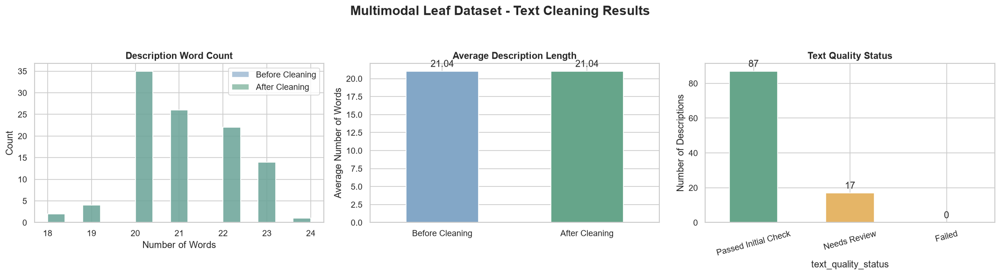


8. FINAL TEXT CLEANING SUMMARY
Total image-text pairs       : 104
Cleaned descriptions         : 104
Empty cleaned descriptions   : 0
Class mentions before        : 0
Class mentions after         : 0
Duplicate text records       : 17
Average words before         : 21.04
Average words after          : 21.04
Passed initial check         : 87
Needs review                 : 17
Failed preprocessing         : 0

[PASS] Image-text alignment preserved.
[PASS] All cleaned descriptions are non-empty.
[PASS] No configured class-name mentions remain in the cleaned text.

Original descriptions remain unchanged.

Intermediate metadata saved to:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_text_cleaned.csv

Text configuration saved to:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\text_preprocessing_config.json

Text cleaning completed successfully!

Next cell: Cell 13 - Text Tokenization


In [13]:
# ==================================================
# TEXT CLEANING AND CASE FOLDING
# ==================================================

print("TEXT CLEANING AND CASE FOLDING")
print("=" * 60)


# ==================================================
# 1. TEXT PREPROCESSING CONFIGURATION
# ==================================================

APPLY_UNICODE_NORMALIZATION = True

APPLY_CASE_FOLDING = True

REMOVE_PUNCTUATION = True

NORMALIZE_WHITESPACE = True

REMOVE_NUMBERS = False

REMOVE_STOPWORDS = False

APPLY_STEMMING = False

REMOVE_CLASS_NAMES = True

MIN_DESCRIPTION_WORDS = 5


# ==================================================
# 2. PREPARE WORKING TEXT DATASET
# ==================================================

df_text = (
    df_image_processed
    .copy()
    .reset_index(drop=True)
)

required_text_columns = [
    "nama_file",
    "image_path",
    "kelas",
    "deskripsi_lengkap"
]

missing_columns = [
    column
    for column in required_text_columns
    if column not in df_text.columns
]

if missing_columns:

    raise ValueError(
        f"Missing text columns: {missing_columns}"
    )

print("\n1. TEXT DATASET INFORMATION")

print(f"Total image-text pairs : {len(df_text)}")

print(
    f"Total classes          : "
    f"{df_text['kelas'].nunique()}"
)


# ==================================================
# 3. PRESERVE ORIGINAL TEXT
# ==================================================

df_text["original_description"] = (

    df_text["deskripsi_lengkap"]

    .fillna("")

    .astype(str)

    .str.strip()
)


# ==================================================
# 4. DEFINE BASIC TEXT CLEANING FUNCTION
# ==================================================

def clean_text_basic(text):

    if pd.isna(text):

        return ""

    text = str(text)

    # Unicode normalization
    if APPLY_UNICODE_NORMALIZATION:

        text = unicodedata.normalize(
            "NFKC",
            text
        )

    # Convert text to lowercase
    if APPLY_CASE_FOLDING:

        text = text.casefold()

    # Remove invisible formatting characters
    text = "".join(

        character

        for character in text

        if unicodedata.category(character)
        != "Cf"
    )

    # Replace punctuation and symbols with spaces
    if REMOVE_PUNCTUATION:

        text = "".join(

            " "
            if unicodedata.category(character)
            .startswith(("P", "S"))

            else character

            for character in text
        )

    # Optional number removal
    if REMOVE_NUMBERS:

        text = re.sub(
            r"\d+",
            " ",
            text
        )

    # Normalize whitespace
    if NORMALIZE_WHITESPACE:

        text = re.sub(
            r"\s+",
            " ",
            text
        )

    return text.strip()


# ==================================================
# 5. DEFINE CLASS NAME PATTERNS
# ==================================================

# Plant class names and spelling variations
class_name_aliases = {

    "Mangkok": [
        "daun mangkok",
        "mangkok",
        "mangkuk"
    ],

    "Salam": [
        "daun salam",
        "salam"
    ],

    "Sambang Darah": [
        "daun sambang darah",
        "sambang darah"
    ],

    "Sirih": [
        "daun sirih",
        "sirih"
    ],

    "Tapak Kuda": [
        "daun tapak kuda",
        "tapak kuda"
    ]
}

all_class_aliases = sorted(

    {
        clean_text_basic(alias)

        for aliases in class_name_aliases.values()

        for alias in aliases
    },

    key=lambda alias: (-len(alias), alias)
)

class_name_pattern = re.compile(

    r"(?<!\w)(?:"

    + "|".join(
        re.escape(alias)
        for alias in all_class_aliases
    )

    + r")(?!\w)",

    flags=re.IGNORECASE
)


# ==================================================
# 6. LABEL LEAKAGE DETECTION
# ==================================================

def detect_class_names(text):

    normalized_text = clean_text_basic(text)

    matches = class_name_pattern.findall(
        normalized_text
    )

    unique_matches = sorted(
        set(matches)
    )

    return unique_matches


# ==================================================
# 7. FINAL TEXT CLEANING FUNCTION
# ==================================================

def preprocess_text(text):

    # Basic text cleaning
    cleaned_text = clean_text_basic(
        text
    )

    # Remove direct class-name mentions
    if REMOVE_CLASS_NAMES:

        cleaned_text = (
            class_name_pattern.sub(
                " ",
                cleaned_text
            )
        )

    # Normalize whitespace again
    cleaned_text = re.sub(
        r"\s+",
        " ",
        cleaned_text
    ).strip()

    return cleaned_text


# ==================================================
# 8. APPLY TEXT CLEANING
# ==================================================

print("\n2. APPLYING TEXT PREPROCESSING")

# Basic cleaning before class-name removal
df_text["basic_cleaned_description"] = (

    df_text["original_description"]

    .progress_apply(clean_text_basic)
)

# Detect class-name mentions
df_text["detected_class_names"] = (

    df_text["original_description"]

    .apply(detect_class_names)
)

df_text["class_name_detected"] = (

    df_text["detected_class_names"]

    .apply(lambda matches: len(matches) > 0)
)

# Apply final text preprocessing
df_text["cleaned_description"] = (

    df_text["original_description"]

    .progress_apply(preprocess_text)
)

# Check class names after preprocessing
df_text["remaining_class_name"] = (

    df_text["cleaned_description"]

    .apply(
        lambda text:
        len(detect_class_names(text)) > 0
    )
)


# ==================================================
# 9. CALCULATE TEXT STATISTICS
# ==================================================

df_text["original_character_count"] = (

    df_text["original_description"]

    .str.len()
)

df_text["cleaned_character_count"] = (

    df_text["cleaned_description"]

    .str.len()
)

df_text["original_word_count"] = (

    df_text["original_description"]

    .apply(
        lambda text: len(text.split())
    )
)

df_text["cleaned_word_count"] = (

    df_text["cleaned_description"]

    .apply(
        lambda text: len(text.split())
    )
)

df_text["character_count_change"] = (

    df_text["cleaned_character_count"]

    - df_text["original_character_count"]
)

df_text["word_count_change"] = (

    df_text["cleaned_word_count"]

    - df_text["original_word_count"]
)

df_text["text_modified"] = (

    df_text["original_description"]

    != df_text["cleaned_description"]
)


# ==================================================
# 10. VALIDATE CLEANED TEXT
# ==================================================

df_text["empty_original_text"] = (

    df_text["original_description"]

    .eq("")
)

df_text["empty_cleaned_text"] = (

    df_text["cleaned_description"]

    .eq("")
)

df_text["short_description"] = (

    df_text["cleaned_word_count"]

    .lt(MIN_DESCRIPTION_WORDS)
)

df_text["contains_uppercase"] = (

    df_text["cleaned_description"]

    .apply(
        lambda text:
        any(character.isupper()
            for character in text)
    )
)

df_text["contains_punctuation"] = (

    df_text["cleaned_description"]

    .apply(

        lambda text: any(

            unicodedata.category(character)
            .startswith(("P", "S"))

            for character in text
        )
    )
)

df_text["excessive_whitespace"] = (

    df_text["cleaned_description"]

    .str.contains(
        r"\s{2,}",
        regex=True
    )
)


# ==================================================
# 11. INSPECT DUPLICATE TEXT DESCRIPTIONS
# ==================================================

df_text["duplicate_cleaned_description"] = (

    df_text["cleaned_description"]
    .ne("")

    & df_text["cleaned_description"]
    .duplicated(keep=False)
)

duplicate_text_df = df_text[

    df_text["duplicate_cleaned_description"]

].copy()

print("\n3. DUPLICATE TEXT INSPECTION")

print(
    f"Records with identical cleaned text : "
    f"{len(duplicate_text_df)}"
)

if not duplicate_text_df.empty:

    display(

        duplicate_text_df[
            [
                "nama_file",
                "kelas",
                "cleaned_description"
            ]
        ].head(10)
    )

else:

    print(
        "[OK] No identical non-empty "
        "cleaned descriptions detected."
    )


# ==================================================
# 12. ASSIGN TEXT QUALITY STATUS
# ==================================================

def inspect_text_quality(row):

    issues = []

    if row["empty_original_text"]:

        issues.append(
            "Empty original description"
        )

    if row["empty_cleaned_text"]:

        issues.append(
            "Empty cleaned description"
        )

    if row["short_description"]:

        issues.append(
            "Short description"
        )

    if row["class_name_detected"]:

        issues.append(
            "Original class-name mention"
        )

    if row["remaining_class_name"]:

        issues.append(
            "Remaining class name"
        )

    if row["contains_uppercase"]:

        issues.append(
            "Uppercase characters"
        )

    if row["contains_punctuation"]:

        issues.append(
            "Remaining punctuation"
        )

    if row["excessive_whitespace"]:

        issues.append(
            "Excessive whitespace"
        )

    if row["duplicate_cleaned_description"]:

        issues.append(
            "Identical cleaned description"
        )

    # Empty text cannot be used directly
    # for meaningful TF-IDF matching

    if row["empty_cleaned_text"]:

        status = "Failed"

    elif issues:

        status = "Needs Review"

    else:

        status = "Passed Initial Check"

    return pd.Series({

        "text_quality_status": status,

        "text_quality_issues": (

            "; ".join(issues)

            if issues

            else "None"
        )
    })


text_quality_results = df_text.apply(

    inspect_text_quality,

    axis=1
)

df_text[
    [
        "text_quality_status",
        "text_quality_issues"
    ]
] = text_quality_results


# ==================================================
# 13. DISPLAY BEFORE AND AFTER COMPARISON
# ==================================================

print("\n4. TEXT PREPROCESSING COMPARISON")

text_comparison_columns = [
    "nama_file",
    "kelas",
    "original_description",
    "cleaned_description",
    "original_word_count",
    "cleaned_word_count"
]

sample_text_df = (

    df_text

    .groupby(
        "kelas",
        group_keys=False
    )

    .sample(
        n=1,
        random_state=RANDOM_STATE
    )
)

with pd.option_context(
    "display.max_colwidth",
    None
):

    display(

        sample_text_df[
            text_comparison_columns
        ]
    )


# ==================================================
# 14. CREATE TEXT QUALITY SUMMARY
# ==================================================

text_quality_counts = (

    df_text["text_quality_status"]

    .value_counts()

    .reindex(

        [
            "Passed Initial Check",
            "Needs Review",
            "Failed"
        ],

        fill_value=0
    )
)

text_cleaning_summary = pd.DataFrame({

    "Indicator": [

        "Total image-text pairs",

        "Available original descriptions",

        "Available cleaned descriptions",

        "Modified descriptions",

        "Empty original descriptions",

        "Empty cleaned descriptions",

        "Class-name mentions before cleaning",

        "Class-name mentions after cleaning",

        "Short descriptions",

        "Records with duplicate descriptions",

        "Average words before cleaning",

        "Average words after cleaning",

        "Average characters before cleaning",

        "Average characters after cleaning",

        "Passed initial check",

        "Needs review",

        "Failed preprocessing"
    ],

    "Result": [

        len(df_text),

        (~df_text["empty_original_text"]).sum(),

        (~df_text["empty_cleaned_text"]).sum(),

        df_text["text_modified"].sum(),

        df_text["empty_original_text"].sum(),

        df_text["empty_cleaned_text"].sum(),

        df_text["class_name_detected"].sum(),

        df_text["remaining_class_name"].sum(),

        df_text["short_description"].sum(),

        df_text[
            "duplicate_cleaned_description"
        ].sum(),

        df_text["original_word_count"].mean(),

        df_text["cleaned_word_count"].mean(),

        df_text[
            "original_character_count"
        ].mean(),

        df_text[
            "cleaned_character_count"
        ].mean(),

        text_quality_counts[
            "Passed Initial Check"
        ],

        text_quality_counts[
            "Needs Review"
        ],

        text_quality_counts[
            "Failed"
        ]
    ]
})

print("\n5. TEXT CLEANING SUMMARY")

display(
    text_cleaning_summary.round(2)
)


# ==================================================
# 15. ANALYZE TEXT QUALITY PER CLASS
# ==================================================

text_class_summary = pd.crosstab(

    df_text["kelas"],

    df_text["text_quality_status"]

).reindex(

    columns=[
        "Passed Initial Check",
        "Needs Review",
        "Failed"
    ],

    fill_value=0
)

text_class_summary["Total"] = (

    text_class_summary.sum(axis=1)
)

print("\n6. TEXT QUALITY PER CLASS")

display(text_class_summary)


# ==================================================
# 16. IDENTIFY TEXT RECORDS REQUIRING REVIEW
# ==================================================

text_review_df = df_text[

    df_text["text_quality_status"]

    .ne("Passed Initial Check")

].copy()

print("\n7. TEXT RECORDS REQUIRING REVIEW")

if text_review_df.empty:

    print(
        "[OK] No text quality issues detected "
        "by the initial inspection rules."
    )

else:

    with pd.option_context(
        "display.max_colwidth",
        None
    ):

        display(

            text_review_df[
                [
                    "nama_file",
                    "kelas",
                    "original_description",
                    "cleaned_description",
                    "text_quality_issues"
                ]
            ].head(10)
        )


# ==================================================
# 17. VISUALIZE TEXT CLEANING RESULTS
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(18, 5)
)

# Word count distribution before cleaning
sns.histplot(

    df_text["original_word_count"],

    bins=15,

    color="#83A7C7",

    alpha=0.65,

    label="Before Cleaning",

    ax=axes[0]
)

# Word count distribution after cleaning
sns.histplot(

    df_text["cleaned_word_count"],

    bins=15,

    color="#66A58A",

    alpha=0.65,

    label="After Cleaning",

    ax=axes[0]
)

axes[0].set_title(

    "Description Word Count",

    fontweight="bold"
)

axes[0].set_xlabel(
    "Number of Words"
)

axes[0].legend()


# Average word count comparison
average_words = pd.Series({

    "Before Cleaning": (

        df_text["original_word_count"]
        .mean()
    ),

    "After Cleaning": (

        df_text["cleaned_word_count"]
        .mean()
    )
})

average_words.plot(

    kind="bar",

    color=[
        "#83A7C7",
        "#66A58A"
    ],

    rot=0,

    ax=axes[1]
)

axes[1].set_title(

    "Average Description Length",

    fontweight="bold"
)

axes[1].set_ylabel(
    "Average Number of Words"
)

for container in axes[1].containers:

    axes[1].bar_label(

        container,

        fmt="%.2f",

        padding=3
    )


# Text quality status distribution
text_quality_counts.plot(

    kind="bar",

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=15,

    ax=axes[2]
)

axes[2].set_title(

    "Text Quality Status",

    fontweight="bold"
)

axes[2].set_ylabel(
    "Number of Descriptions"
)

for container in axes[2].containers:

    axes[2].bar_label(

        container,

        padding=3
    )


fig.suptitle(

    "Multimodal Leaf Dataset - Text Cleaning Results",

    fontsize=17,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.93]
)

plt.savefig(

    FIGURES_DIR /
    "20_text_cleaning_results.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ==================================================
# 18. SAVE TEXT CLEANING REPORTS
# ==================================================

text_report_columns = [

    "nama_file",
    "image_path",
    "kelas",
    "original_description",
    "basic_cleaned_description",
    "cleaned_description",
    "original_character_count",
    "cleaned_character_count",
    "original_word_count",
    "cleaned_word_count",
    "character_count_change",
    "word_count_change",
    "class_name_detected",
    "detected_class_names",
    "remaining_class_name",
    "duplicate_cleaned_description",
    "text_quality_status",
    "text_quality_issues"
]

df_text[text_report_columns].to_csv(

    METRICS_DIR /
    "48_text_cleaning_details.csv",

    index=False,

    encoding="utf-8-sig"
)

text_cleaning_summary.to_csv(

    METRICS_DIR /
    "49_text_cleaning_summary.csv",

    index=False
)

text_review_df.to_csv(

    METRICS_DIR /
    "50_text_cleaning_review.csv",

    index=False,

    encoding="utf-8-sig"
)

text_class_summary.to_csv(

    METRICS_DIR /
    "51_text_quality_per_class.csv"
)

duplicate_text_df.to_csv(

    METRICS_DIR /
    "52_duplicate_text_descriptions.csv",

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 19. SAVE INTERMEDIATE TEXT METADATA
# ==================================================

TEXT_CLEANED_METADATA = (

    PROCESSED_DIR /

    "metadata_text_cleaned.csv"
)

df_text.drop(

    columns=["absolute_image_path"],

    errors="ignore"

).to_csv(

    TEXT_CLEANED_METADATA,

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 20. SAVE TEXT PREPROCESSING CONFIGURATION
# ==================================================

text_preprocessing_config = {

    "unicode_normalization": (
        APPLY_UNICODE_NORMALIZATION
    ),

    "unicode_normalization_form": "NFKC",

    "case_folding": APPLY_CASE_FOLDING,

    "remove_punctuation": REMOVE_PUNCTUATION,

    "normalize_whitespace": NORMALIZE_WHITESPACE,

    "remove_numbers": REMOVE_NUMBERS,

    "remove_stopwords": REMOVE_STOPWORDS,

    "apply_stemming": APPLY_STEMMING,

    "remove_class_names": REMOVE_CLASS_NAMES,

    "class_name_aliases": class_name_aliases,

    "minimum_description_words": (
        MIN_DESCRIPTION_WORDS
    ),

    "source_text_column": "deskripsi_lengkap",

    "output_text_column": "cleaned_description"
}

TEXT_CONFIG_PATH = (

    PROCESSED_DIR /

    "text_preprocessing_config.json"
)

with open(

    TEXT_CONFIG_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        text_preprocessing_config,

        file,

        indent=4,

        ensure_ascii=False
    )


# ==================================================
# 21. FINAL TEXT CLEANING SUMMARY
# ==================================================

print("\n8. FINAL TEXT CLEANING SUMMARY")

print("=" * 60)

print(

    f"Total image-text pairs       : "
    f"{len(df_text)}"
)

print(

    f"Cleaned descriptions         : "
    f"{(~df_text['empty_cleaned_text']).sum()}"
)

print(

    f"Empty cleaned descriptions   : "
    f"{df_text['empty_cleaned_text'].sum()}"
)

print(

    f"Class mentions before        : "
    f"{df_text['class_name_detected'].sum()}"
)

print(

    f"Class mentions after         : "
    f"{df_text['remaining_class_name'].sum()}"
)

print(

    f"Duplicate text records       : "
    f"{df_text['duplicate_cleaned_description'].sum()}"
)

print(

    f"Average words before         : "
    f"{df_text['original_word_count'].mean():.2f}"
)

print(

    f"Average words after          : "
    f"{df_text['cleaned_word_count'].mean():.2f}"
)

print(

    f"Passed initial check         : "
    f"{text_quality_counts['Passed Initial Check']}"
)

print(

    f"Needs review                 : "
    f"{text_quality_counts['Needs Review']}"
)

print(

    f"Failed preprocessing         : "
    f"{text_quality_counts['Failed']}"
)

# Ensure image-text alignment remains unchanged
assert len(df_text) == len(df_image_processed)

assert df_text["image_path"].is_unique

print(
    "\n[PASS] Image-text alignment preserved."
)

if text_quality_counts["Failed"] > 0:

    print(

        "[WARNING] Empty descriptions must "
        "be reviewed before TF-IDF extraction."
    )

else:

    print(

        "[PASS] All cleaned descriptions "
        "are non-empty."
    )

if df_text["remaining_class_name"].any():

    print(

        "[WARNING] Some configured class-name "
        "mentions remain in the cleaned text."
    )

else:

    print(

        "[PASS] No configured class-name "
        "mentions remain in the cleaned text."
    )

print("\nOriginal descriptions remain unchanged.")

print("\nIntermediate metadata saved to:")

print(TEXT_CLEANED_METADATA)

print("\nText configuration saved to:")

print(TEXT_CONFIG_PATH)

print("\nText cleaning completed successfully!")

print(

    "\nNext cell: "
    "Cell 13 - Text Tokenization"
)

TEXT TOKENIZATION

1. TOKENIZATION DATASET INFORMATION
Total descriptions : 104
Total classes      : 5
Token pattern      : (?u)\b\w\w+\b

2. APPLYING TEXT TOKENIZATION


  0%|          | 0/104 [00:00<?, ?it/s]


3. TOKENIZATION EXAMPLES


,nama_file,kelas,cleaned_description,tokens,token_count,unique_token_count
0,mangkok 10.jpeg,Mangkok,daun berwarna hijau tua berbentuk membulat dengan tepi bergelombang halus dan ujung membulat permukaan tampak mengilap berkerut tulang daun tampak,"[daun, berwarna, hijau, tua, berbentuk, membulat, dengan, tepi, bergelombang, halus, dan, ujung, membulat, permukaan, tampak, mengilap, berkerut, tulang, daun, tampak]",20,17
38,daun salam 9.png,Salam,daun berwarna hijau tua berbentuk lonjong memanjang dengan tepi bergelombang halus dan ujung meruncing permukaan tampak mengilap tulang tengah dan urat menyirip jelas,"[daun, berwarna, hijau, tua, berbentuk, lonjong, memanjang, dengan, tepi, bergelombang, halus, dan, ujung, meruncing, permukaan, tampak, mengilap, tulang, tengah, dan, urat, menyirip, jelas]",23,22
49,sambang darah 1.jpeg,Sambang Darah,daun berwarna hijau tua berbentuk lonjong memanjang dengan tepi rata dan ujung runcing permukaan tampak kusam urat samar detail halus kurang jelas,"[daun, berwarna, hijau, tua, berbentuk, lonjong, memanjang, dengan, tepi, rata, dan, ujung, runcing, permukaan, tampak, kusam, urat, samar, detail, halus, kurang, jelas]",22,22
59,Hijau_Sehat1.jpg,Sirih,daun berwarna hijau zaitun berbentuk bulat telur agak asimetris dengan tepi rata dan ujung runcing permukaan tampak kusam urat daun jelas dari pangkal,"[daun, berwarna, hijau, zaitun, berbentuk, bulat, telur, agak, asimetris, dengan, tepi, rata, dan, ujung, runcing, permukaan, tampak, kusam, urat, daun, jelas, dari, pangkal]",23,22
96,tapak kuda 2.jpeg,Tapak Kuda,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampak berkerut urat menjari terlihat,"[daun, berwarna, hijau, tua, berbentuk, menyerupai, ginjal, dengan, tepi, berlekuk, membulat, dan, ujung, membulat, permukaan, tampak, berkerut, urat, menjari, terlihat]",20,19



4. VOCABULARY ANALYSIS
Total tokens      : 2188
Vocabulary size   : 68
Average tokens    : 21.04
Minimum tokens    : 18
Maximum tokens    : 24

Most frequent tokens:


,token,term_frequency,document_frequency,document_percentage
0,daun,121,104,100.00
1,berbentuk,114,104,100.00
2,dan,114,104,100.00
3,permukaan,110,104,100.00
4,tampak,105,104,100.00
5,berwarna,104,104,100.00
6,dengan,104,104,100.00
7,tepi,104,104,100.00
8,ujung,104,104,100.00
9,hijau,100,99,95.19


... (2 outputs left out)


6. TOKENIZATION SUMMARY


,Indicator,Result
0,Total descriptions,104.0000
1,Successfully tokenized descriptions,104.0000
2,Total tokens,2188.0000
3,Vocabulary size,68.0000
4,Minimum tokens per description,18.0000
5,Maximum tokens per description,24.0000
6,Average tokens per description,21.0385
7,Average unique tokens,20.0577
8,Average lexical diversity,0.9543
9,Empty token sequences,0.0000



7. TOKENIZATION REVIEW


,nama_file,kelas,token_count,tokenization_status,tokenization_issues
13,mangkok 3.jpeg,Mangkok,20,Needs Review,Identical token sequence
14,mangkok 4.jpeg,Mangkok,20,Needs Review,Identical token sequence
70,Hijau_Sehat3.jpg,Sirih,21,Needs Review,Identical token sequence
73,Hijau_Sehat9.jpg,Sirih,21,Needs Review,Identical token sequence
81,tapak kuda 13.jpeg,Tapak Kuda,23,Needs Review,Identical token sequence
85,tapak kuda 17.png,Tapak Kuda,20,Needs Review,Identical token sequence
87,tapak kuda 19.png,Tapak Kuda,20,Needs Review,Identical token sequence
89,tapak kuda 1.jpeg,Tapak Kuda,20,Needs Review,Identical token sequence
90,tapak kuda 10.jpeg,Tapak Kuda,22,Needs Review,Identical token sequence
91,tapak kuda 10.png,Tapak Kuda,21,Needs Review,Identical token sequence


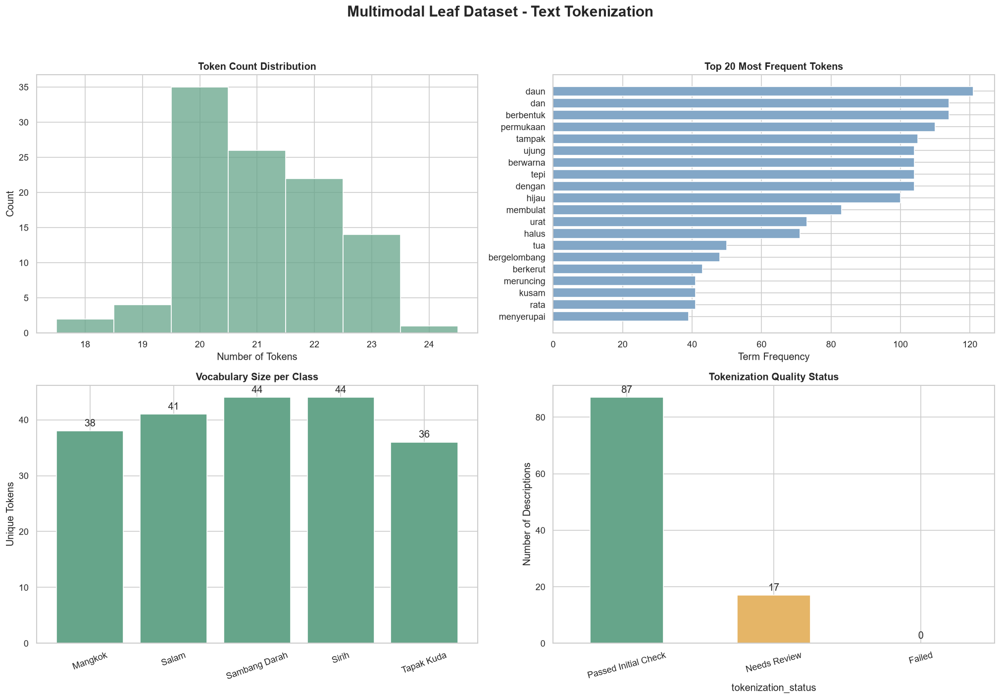


8. FINAL TOKENIZATION SUMMARY
Total descriptions     : 104
Total tokens           : 2188
Vocabulary size        : 68
Average tokens         : 21.04
Empty token sequences  : 0
Duplicate sequences    : 17
Passed initial check   : 87
Needs review           : 17
Failed tokenization    : 0

[PASS] Image-text alignment preserved.
[PASS] All descriptions passed technical tokenization checks.

Tokenized metadata saved to:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_text_tokenized.csv

[INFO] TF-IDF has not been fitted.
[INFO] Original descriptions remain unchanged.

Text tokenization completed!

Next cell: Cell 14 - Save Processed Metadata


In [14]:
# ==================================================
# TEXT TOKENIZATION
# ==================================================

print("TEXT TOKENIZATION")
print("=" * 60)


# ==================================================
# 1. TOKENIZATION CONFIGURATION
# ==================================================

# Compatible with sklearn TfidfVectorizer
TOKEN_PATTERN = r"(?u)\b\w\w+\b"

TOKEN_REGEX = re.compile(TOKEN_PATTERN)

MIN_TOKENS = 5

TOP_N_WORDS = 20


# ==================================================
# 2. PREPARE TOKENIZATION DATASET
# ==================================================

df_tokenized = (
    df_text.copy()
    .reset_index(drop=True)
)

assert not df_tokenized.empty

assert "cleaned_description" in df_tokenized.columns

assert df_tokenized["image_path"].is_unique

print("\n1. TOKENIZATION DATASET INFORMATION")

print(f"Total descriptions : {len(df_tokenized)}")

print(
    f"Total classes      : "
    f"{df_tokenized['kelas'].nunique()}"
)

print(f"Token pattern      : {TOKEN_PATTERN}")


# ==================================================
# 3. DEFINE TOKENIZATION FUNCTION
# ==================================================

def tokenize_text(text):

    if pd.isna(text):

        return []

    text = str(text).strip()

    if not text:

        return []

    tokens = TOKEN_REGEX.findall(text)

    return tokens


# ==================================================
# 4. APPLY TOKENIZATION
# ==================================================

print("\n2. APPLYING TEXT TOKENIZATION")

df_tokenized["tokens"] = (

    df_tokenized["cleaned_description"]

    .progress_apply(tokenize_text)
)

# Convert tokens into text representation
df_tokenized["tokenized_description"] = (

    df_tokenized["tokens"]

    .apply(lambda tokens: " ".join(tokens))
)

# Store token lists in JSON format
df_tokenized["tokens_json"] = (

    df_tokenized["tokens"]

    .apply(
        lambda tokens:
        json.dumps(
            tokens,
            ensure_ascii=False
        )
    )
)


# ==================================================
# 5. CALCULATE TOKEN STATISTICS
# ==================================================

df_tokenized["token_count"] = (

    df_tokenized["tokens"]

    .apply(len)
)

df_tokenized["unique_token_count"] = (

    df_tokenized["tokens"]

    .apply(lambda tokens: len(set(tokens)))
)

df_tokenized["repeated_token_count"] = (

    df_tokenized["token_count"]

    - df_tokenized["unique_token_count"]
)

# Lexical diversity per description
df_tokenized["lexical_diversity"] = (

    df_tokenized["unique_token_count"]

    .div(
        df_tokenized["token_count"]
        .replace(0, np.nan)
    )

    .fillna(0)
)

# Compare word count and token count
df_tokenized["token_count_difference"] = (

    df_tokenized["token_count"]

    - df_tokenized["cleaned_word_count"]
)


# ==================================================
# 6. DISPLAY TOKENIZATION EXAMPLES
# ==================================================

print("\n3. TOKENIZATION EXAMPLES")

sample_tokenized_df = (

    df_tokenized

    .groupby(
        "kelas",
        group_keys=False
    )

    .sample(
        n=1,
        random_state=RANDOM_STATE
    )
)

with pd.option_context(
    "display.max_colwidth",
    None
):

    display(

        sample_tokenized_df[
            [
                "nama_file",
                "kelas",
                "cleaned_description",
                "tokens",
                "token_count",
                "unique_token_count"
            ]
        ]
    )


# ==================================================
# 7. BUILD EXPLORATORY VOCABULARY
# ==================================================

print("\n4. VOCABULARY ANALYSIS")

# Collect all tokens from the dataset
all_tokens = [

    token

    for tokens in df_tokenized["tokens"]

    for token in tokens
]

# Count total occurrences of each token
token_frequency = Counter(all_tokens)

# Count documents containing each token
document_frequency = Counter(

    token

    for tokens in df_tokenized["tokens"]

    for token in set(tokens)
)

# Create exploratory vocabulary
vocabulary = sorted(
    token_frequency.keys()
)

vocabulary_size = len(vocabulary)

total_tokens = len(all_tokens)

# Create vocabulary frequency table
vocabulary_df = pd.DataFrame({

    "token": vocabulary,

    "term_frequency": [

        token_frequency[token]

        for token in vocabulary
    ],

    "document_frequency": [

        document_frequency[token]

        for token in vocabulary
    ]
})

vocabulary_df["document_percentage"] = (

    vocabulary_df["document_frequency"]

    / len(df_tokenized) * 100
).round(2)

vocabulary_df = vocabulary_df.sort_values(

    ["term_frequency", "token"],

    ascending=[False, True]

).reset_index(drop=True)

print(f"Total tokens      : {total_tokens}")

print(f"Vocabulary size   : {vocabulary_size}")

print(
    f"Average tokens    : "
    f"{df_tokenized['token_count'].mean():.2f}"
)

print(
    f"Minimum tokens    : "
    f"{df_tokenized['token_count'].min()}"
)

print(
    f"Maximum tokens    : "
    f"{df_tokenized['token_count'].max()}"
)

print("\nMost frequent tokens:")

display(
    vocabulary_df.head(TOP_N_WORDS)
)


# ==================================================
# 8. ANALYZE VOCABULARY PER CLASS
# ==================================================

print("\n5. VOCABULARY PER CLASS")

class_vocabulary_records = []

for plant_class, group in df_tokenized.groupby("kelas"):

    class_tokens = [

        token

        for tokens in group["tokens"]

        for token in tokens
    ]

    class_counter = Counter(
        class_tokens
    )

    unique_class_tokens = len(
        class_counter
    )

    class_vocabulary_records.append({

        "kelas": plant_class,

        "total_descriptions": len(group),

        "total_tokens": len(class_tokens),

        "vocabulary_size": unique_class_tokens,

        "average_tokens": (
            group["token_count"].mean()
        ),

        "average_unique_tokens": (
            group["unique_token_count"].mean()
        ),

        "most_frequent_tokens": ", ".join(

            token

            for token, count
            in class_counter.most_common(10)
        )
    })


class_vocabulary_df = pd.DataFrame(
    class_vocabulary_records
)

display(
    class_vocabulary_df.round(2)
)


# ==================================================
# 9. VALIDATE TOKENIZATION RESULTS
# ==================================================

df_tokenized["empty_tokens"] = (

    df_tokenized["token_count"].eq(0)
)

df_tokenized["insufficient_tokens"] = (

    df_tokenized["token_count"].lt(
        MIN_TOKENS
    )
)

df_tokenized["valid_token_format"] = (

    df_tokenized["tokens"]

    .apply(

        lambda tokens:

        all(

            TOKEN_REGEX.fullmatch(token)
            is not None

            for token in tokens
        )
    )
)

# Check tokenization consistency
df_tokenized["tokenization_consistent"] = (

    df_tokenized["tokenized_description"]

    .apply(tokenize_text)

    .eq(df_tokenized["tokens"])
)

# Check remaining class names
df_tokenized["class_name_in_tokens"] = (

    df_tokenized["tokenized_description"]

    .apply(

        lambda text:

        len(detect_class_names(text)) > 0
    )
)

# Detect identical token sequences
df_tokenized["duplicate_token_sequence"] = (

    df_tokenized["tokenized_description"].ne("")

    & df_tokenized["tokenized_description"]
    .duplicated(keep=False)
)


# ==================================================
# 10. ASSIGN TOKENIZATION STATUS
# ==================================================

def inspect_tokenization(row):

    issues = []

    if row["empty_tokens"]:

        issues.append(
            "Empty token sequence"
        )

    if row["insufficient_tokens"]:

        issues.append(
            "Insufficient tokens"
        )

    if not row["valid_token_format"]:

        issues.append(
            "Invalid token format"
        )

    if not row["tokenization_consistent"]:

        issues.append(
            "Inconsistent tokenization"
        )

    if row["class_name_in_tokens"]:

        issues.append(
            "Class name detected"
        )

    if row["duplicate_token_sequence"]:

        issues.append(
            "Identical token sequence"
        )

    if (
        row["empty_tokens"]

        or not row["valid_token_format"]

        or not row["tokenization_consistent"]
    ):

        status = "Failed"

    elif issues:

        status = "Needs Review"

    else:

        status = "Passed Initial Check"

    return pd.Series({

        "tokenization_status": status,

        "tokenization_issues": (

            "; ".join(issues)

            if issues

            else "None"
        )
    })


df_tokenized[
    [
        "tokenization_status",
        "tokenization_issues"
    ]
] = df_tokenized.apply(

    inspect_tokenization,

    axis=1
)


# ==================================================
# 11. CREATE TOKENIZATION SUMMARY
# ==================================================

tokenization_counts = (

    df_tokenized["tokenization_status"]

    .value_counts()

    .reindex(

        [
            "Passed Initial Check",
            "Needs Review",
            "Failed"
        ],

        fill_value=0
    )
)

tokenization_summary = pd.DataFrame({

    "Indicator": [

        "Total descriptions",

        "Successfully tokenized descriptions",

        "Total tokens",

        "Vocabulary size",

        "Minimum tokens per description",

        "Maximum tokens per description",

        "Average tokens per description",

        "Average unique tokens",

        "Average lexical diversity",

        "Empty token sequences",

        "Insufficient token sequences",

        "Invalid token formats",

        "Inconsistent tokenization",

        "Class names in tokens",

        "Duplicate token sequences",

        "Passed initial check",

        "Needs review",

        "Failed tokenization"
    ],

    "Result": [

        len(df_tokenized),

        (
            ~df_tokenized["empty_tokens"]
            & df_tokenized["valid_token_format"]
            & df_tokenized["tokenization_consistent"]
        ).sum(),

        total_tokens,

        vocabulary_size,

        df_tokenized["token_count"].min(),

        df_tokenized["token_count"].max(),

        df_tokenized["token_count"].mean(),

        df_tokenized["unique_token_count"].mean(),

        df_tokenized["lexical_diversity"].mean(),

        df_tokenized["empty_tokens"].sum(),

        df_tokenized["insufficient_tokens"].sum(),

        (~df_tokenized["valid_token_format"]).sum(),

        (~df_tokenized["tokenization_consistent"]).sum(),

        df_tokenized["class_name_in_tokens"].sum(),

        df_tokenized["duplicate_token_sequence"].sum(),

        tokenization_counts["Passed Initial Check"],

        tokenization_counts["Needs Review"],

        tokenization_counts["Failed"]
    ]
})

print("\n6. TOKENIZATION SUMMARY")

display(
    tokenization_summary.round(4)
)


# ==================================================
# 12. IDENTIFY RECORDS REQUIRING REVIEW
# ==================================================

tokenization_review_df = df_tokenized[

    df_tokenized["tokenization_status"]

    .ne("Passed Initial Check")

].copy()

print("\n7. TOKENIZATION REVIEW")

if tokenization_review_df.empty:

    print(
        "[OK] No tokenization issues detected."
    )

else:

    display(

        tokenization_review_df[
            [
                "nama_file",
                "kelas",
                "token_count",
                "tokenization_status",
                "tokenization_issues"
            ]
        ]
    )


# ==================================================
# 13. VISUALIZE TOKENIZATION RESULTS
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(17, 12)
)

# Token count distribution
sns.histplot(

    data=df_tokenized,

    x="token_count",

    discrete=True,

    color="#66A58A",

    ax=axes[0, 0]
)

axes[0, 0].set_title(

    "Token Count Distribution",

    fontweight="bold"
)

axes[0, 0].set_xlabel(
    "Number of Tokens"
)


# Most frequent tokens
top_words = (

    vocabulary_df.head(TOP_N_WORDS)

    .sort_values("term_frequency")
)

axes[0, 1].barh(

    top_words["token"],

    top_words["term_frequency"],

    color="#83A7C7"
)

axes[0, 1].set_title(

    "Top 20 Most Frequent Tokens",

    fontweight="bold"
)

axes[0, 1].set_xlabel(
    "Term Frequency"
)


# Vocabulary size per class
axes[1, 0].bar(

    class_vocabulary_df["kelas"],

    class_vocabulary_df["vocabulary_size"],

    color="#66A58A"
)

axes[1, 0].set_title(

    "Vocabulary Size per Class",

    fontweight="bold"
)

axes[1, 0].set_ylabel(
    "Unique Tokens"
)

axes[1, 0].tick_params(
    axis="x",
    rotation=20
)

for container in axes[1, 0].containers:

    axes[1, 0].bar_label(
        container,
        padding=3
    )


# Tokenization status
tokenization_counts.plot(

    kind="bar",

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=15,

    ax=axes[1, 1]
)

axes[1, 1].set_title(

    "Tokenization Quality Status",

    fontweight="bold"
)

axes[1, 1].set_ylabel(
    "Number of Descriptions"
)

for container in axes[1, 1].containers:

    axes[1, 1].bar_label(
        container,
        padding=3
    )


fig.suptitle(

    "Multimodal Leaf Dataset - Text Tokenization",

    fontsize=18,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(

    FIGURES_DIR /
    "21_text_tokenization_results.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# 14. SAVE TOKENIZATION REPORTS
# ==================================================

tokenization_report_columns = [

    "nama_file",
    "image_path",
    "kelas",
    "cleaned_description",
    "tokens_json",
    "tokenized_description",
    "token_count",
    "unique_token_count",
    "repeated_token_count",
    "lexical_diversity",
    "token_count_difference",
    "duplicate_token_sequence",
    "tokenization_status",
    "tokenization_issues"
]

df_tokenized[
    tokenization_report_columns
].to_csv(

    METRICS_DIR /
    "53_tokenization_details.csv",

    index=False,

    encoding="utf-8-sig"
)

vocabulary_df.to_csv(

    METRICS_DIR /
    "54_vocabulary_frequency.csv",

    index=False,

    encoding="utf-8-sig"
)

class_vocabulary_df.to_csv(

    METRICS_DIR /
    "55_vocabulary_per_class.csv",

    index=False,

    encoding="utf-8-sig"
)

tokenization_summary.to_csv(

    METRICS_DIR /
    "56_tokenization_summary.csv",

    index=False
)

tokenization_review_df.drop(

    columns=["tokens", "absolute_image_path"],

    errors="ignore"

).to_csv(

    METRICS_DIR /
    "57_tokenization_review.csv",

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 15. SAVE INTERMEDIATE TOKENIZED METADATA
# ==================================================

TOKENIZED_METADATA = (

    PROCESSED_DIR /

    "metadata_text_tokenized.csv"
)

df_tokenized.drop(

    columns=[
        "absolute_image_path",
        "tokens"
    ],

    errors="ignore"

).to_csv(

    TOKENIZED_METADATA,

    index=False,

    encoding="utf-8-sig"
)


# ==================================================
# 16. UPDATE TEXT PREPROCESSING CONFIGURATION
# ==================================================

text_preprocessing_config.update({

    "tokenization_method": "Regex Tokenization",

    "token_pattern": TOKEN_PATTERN,

    "minimum_tokens": MIN_TOKENS,

    "remove_stopwords": False,

    "apply_stemming": False,

    "tokenized_text_column": (
        "tokenized_description"
    ),

    "token_list_column": "tokens_json",

    "exploratory_vocabulary_size": (
        vocabulary_size
    ),

    "tfidf_fitted": False
})

with open(

    TEXT_CONFIG_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        text_preprocessing_config,

        file,

        indent=4,

        ensure_ascii=False
    )


# ==================================================
# 17. FINAL TOKENIZATION SUMMARY
# ==================================================

print("\n8. FINAL TOKENIZATION SUMMARY")
print("=" * 60)

print(f"Total descriptions     : {len(df_tokenized)}")

print(f"Total tokens           : {total_tokens}")

print(f"Vocabulary size        : {vocabulary_size}")

print(

    f"Average tokens         : "
    f"{df_tokenized['token_count'].mean():.2f}"
)

print(

    f"Empty token sequences  : "
    f"{df_tokenized['empty_tokens'].sum()}"
)

print(

    f"Duplicate sequences    : "
    f"{df_tokenized['duplicate_token_sequence'].sum()}"
)

print(

    f"Passed initial check   : "
    f"{tokenization_counts['Passed Initial Check']}"
)

print(

    f"Needs review           : "
    f"{tokenization_counts['Needs Review']}"
)

print(

    f"Failed tokenization    : "
    f"{tokenization_counts['Failed']}"
)

# Validate image-text alignment
assert len(df_tokenized) == len(df_text)

assert df_tokenized["image_path"].is_unique

assert (

    df_tokenized["image_path"]

    .reset_index(drop=True)

    .equals(

        df_text["image_path"]

        .reset_index(drop=True)
    )
)

print(
    "\n[PASS] Image-text alignment preserved."
)

if tokenization_counts["Failed"] == 0:

    print(

        "[PASS] All descriptions passed "
        "technical tokenization checks."
    )

else:

    print(

        "[WARNING] Some token sequences "
        "require correction."
    )

print("\nTokenized metadata saved to:")
print(TOKENIZED_METADATA)

print("\n[INFO] TF-IDF has not been fitted.")

print(
    "[INFO] Original descriptions remain unchanged."
)

print("\nText tokenization completed!")

print(
    "\nNext cell: "
    "Cell 14 - Save Processed Metadata"
)

SAVE PROCESSED METADATA

1. FINAL DATASET INFORMATION
Total records : 104
Total classes : 5

2. METADATA STRUCTURE VALIDATION
[OK] All required columns are available.
[OK] Source image paths are unique.
[OK] Processed image paths are unique.
[OK] Mask paths are unique.

3. SAMPLE IDENTIFIER VALIDATION
Unique sample IDs : 104


,sample_id,nama_file,kelas
0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok
1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok
2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok
3,leaf_0ebc8f4f3ee9c8d5,mangkok 13.png,Mangkok
4,leaf_b0c5f55e42499cae,mangkok 14.png,Mangkok



4. VALIDATING PROCESSED IMAGE FILES


Validating RGB images:   0%|          | 0/104 [00:00<?, ?it/s]


5. VALIDATING BINARY MASK FILES


Validating binary masks:   0%|          | 0/104 [00:00<?, ?it/s]

... (3 outputs left out)

,sample_id,nama_file,kelas,processed_image_path,mask_path,token_count,final_dataset_status
0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,20,Ready - Pending Review
1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,23,Ready - Initial Checks Passed
2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,21,Ready - Initial Checks Passed
3,leaf_0ebc8f4f3ee9c8d5,mangkok 13.png,Mangkok,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,21,Ready - Initial Checks Passed
4,leaf_b0c5f55e42499cae,mangkok 14.png,Mangkok,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,22,Ready - Initial Checks Passed



10. SAVING FINAL METADATA
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv

11. SAVED METADATA VERIFICATION
[OK] Final metadata file is readable.
[OK] Number of records is preserved.
[OK] Sample identifiers are preserved.
[OK] Image and text alignment is preserved.

12. FINAL CLASS DISTRIBUTION


final_dataset_status,Ready - Initial Checks Passed,Ready - Pending Review,Failed,Total
kelas,,,,
Mangkok,11,9,0,20
Salam,9,10,0,19
Sambang Darah,4,16,0,20
Sirih,10,10,0,20
Tapak Kuda,0,25,0,25



13. FINAL REVIEW RECORDS
Records requiring review : 70


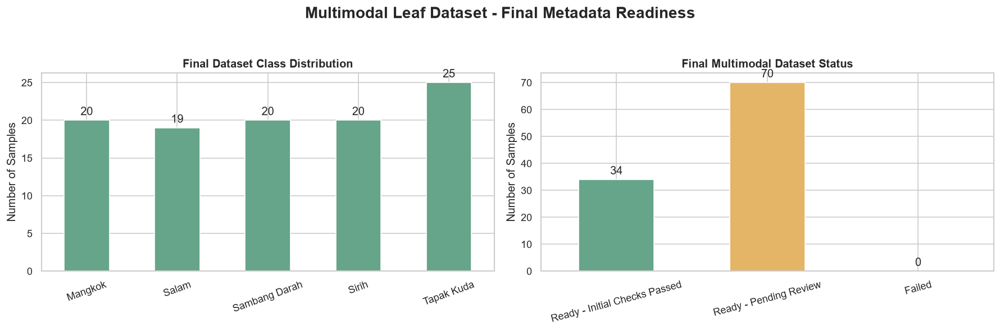


14. FINAL METADATA SAVE SUMMARY
Total candidate records  : 104
Final multimodal records : 104
Valid RGB images         : 104
Valid binary masks       : 104
Valid text descriptions  : 104
Total classes            : 5
Initial checks passed    : 34
Pending quality review   : 70
Invalid multimodal pairs : 0

Final metadata:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv

Dataset manifest:
D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\dataset_manifest.json

[PASS] All multimodal pairs passed technical validation.
[REVIEW] Manual quality review is still required before final evaluation.
[INFO] Feature extraction has not been performed.
[INFO] TF-IDF has not been fitted.

Final processed metadata saved successfully!

Next cell: Cell 15 - Preprocessing Summary


In [15]:
# ==================================================
# SAVE PROCESSED METADATA
# ==================================================

print("SAVE PROCESSED METADATA")
print("=" * 60)


# ==================================================
# 1. PREPARE FINAL MULTIMODAL DATASET
# ==================================================

df_final = (
    df_tokenized.copy()
    .reset_index(drop=True)
)

initial_records = len(df_final)

print("\n1. FINAL DATASET INFORMATION")

print(f"Total records : {initial_records}")
print(f"Total classes : {df_final['kelas'].nunique()}")


# ==================================================
# 2. VALIDATE REQUIRED METADATA COLUMNS
# ==================================================

required_columns = [

    "nama_file",
    "image_path",
    "processed_image_path",
    "mask_path",

    "kelas",
    "tampilan_daun",

    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur",

    "original_description",
    "cleaned_description",
    "tokenized_description",
    "tokens_json",

    "token_count",

    "processing_success",
    "batch_status",
    "text_quality_status",
    "tokenization_status"
]

missing_columns = [

    column

    for column in required_columns

    if column not in df_final.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

assert not df_final.empty, "Dataset is empty."

assert df_final["image_path"].is_unique, (
    "Duplicate source image paths detected."
)

assert df_final["processed_image_path"].is_unique, (
    "Duplicate processed image paths detected."
)

assert df_final["mask_path"].is_unique, (
    "Duplicate mask paths detected."
)

print("\n2. METADATA STRUCTURE VALIDATION")

print("[OK] All required columns are available.")
print("[OK] Source image paths are unique.")
print("[OK] Processed image paths are unique.")
print("[OK] Mask paths are unique.")


# ==================================================
# 3. GENERATE STABLE SAMPLE IDENTIFIERS
# ==================================================

def generate_sample_id(image_path):

    normalized_path = Path(
        str(image_path)
    ).as_posix()

    path_hash = hashlib.sha256(
        normalized_path.encode("utf-8")
    ).hexdigest()

    return f"leaf_{path_hash[:16]}"


df_final["sample_id"] = (

    df_final["image_path"]

    .apply(generate_sample_id)
)

assert df_final["sample_id"].is_unique, (
    "Duplicate sample identifiers detected."
)

print("\n3. SAMPLE IDENTIFIER VALIDATION")

print(
    f"Unique sample IDs : "
    f"{df_final['sample_id'].nunique()}"
)

display(
    df_final[
        [
            "sample_id",
            "nama_file",
            "kelas"
        ]
    ].head()
)


# ==================================================
# 4. DEFINE PROCESSED IMAGE VALIDATION
# ==================================================

def validate_processed_image(image_path):

    try:

        full_path = (
            PROJECT_ROOT / Path(str(image_path))
        )

        if not full_path.is_file():

            return False, "Processed image not found"

        with Image.open(full_path) as image:

            image_format = image.format

            image_mode = image.mode

            image_array = np.array(image)

        if image_format != "PNG":

            return False, "Invalid image format"

        if image_mode != "RGB":

            return False, "Invalid image mode"

        if image_array.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH,
            3
        ):

            return False, "Invalid RGB dimensions"

        if image_array.dtype != np.uint8:

            return False, "Invalid image data type"

        return True, ""

    except Exception as error:

        return False, str(error)


# ==================================================
# 5. DEFINE BINARY MASK VALIDATION
# ==================================================

def validate_processed_mask(mask_path):

    try:

        full_path = (
            PROJECT_ROOT / Path(str(mask_path))
        )

        if not full_path.is_file():

            return False, "Binary mask not found"

        with Image.open(full_path) as image:

            mask_format = image.format

            mask_mode = image.mode

            mask_array = np.array(image)

        if mask_format != "PNG":

            return False, "Invalid mask format"

        if mask_mode != "L":

            return False, "Invalid mask mode"

        if mask_array.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH
        ):

            return False, "Invalid mask dimensions"

        if mask_array.dtype != np.uint8:

            return False, "Invalid mask data type"

        unique_values = set(
            np.unique(mask_array).tolist()
        )

        if unique_values != {0, 255}:

            return False, "Invalid binary mask values"

        foreground_pixels = np.count_nonzero(
            mask_array
        )

        if foreground_pixels < ROI_MIN_MASK_PIXELS:

            return False, "Insufficient foreground pixels"

        return True, ""

    except Exception as error:

        return False, str(error)


# ==================================================
# 6. VALIDATE ALL IMAGE AND MASK FILES
# ==================================================

print("\n4. VALIDATING PROCESSED IMAGE FILES")

image_validation_results = [

    validate_processed_image(path)

    for path in tqdm(
        df_final["processed_image_path"],
        desc="Validating RGB images"
    )
]

df_final[
    [
        "processed_image_valid",
        "processed_image_error"
    ]
] = pd.DataFrame(
    image_validation_results,
    index=df_final.index
)


print("\n5. VALIDATING BINARY MASK FILES")

mask_validation_results = [

    validate_processed_mask(path)

    for path in tqdm(
        df_final["mask_path"],
        desc="Validating binary masks"
    )
]

df_final[
    [
        "processed_mask_valid",
        "processed_mask_error"
    ]
] = pd.DataFrame(
    mask_validation_results,
    index=df_final.index
)


# ==================================================
# 7. VALIDATE IMAGE-MASK ALIGNMENT
# ==================================================

def validate_image_mask_pair(row):

    try:

        image_path = (
            PROJECT_ROOT /
            Path(row["processed_image_path"])
        ).resolve()

        mask_path = (
            PROJECT_ROOT /
            Path(row["mask_path"])
        ).resolve()

        relative_image = image_path.relative_to(
            PROCESSED_IMAGE_DIR.resolve()
        )

        relative_mask = mask_path.relative_to(
            MASK_DIR.resolve()
        )

        # Both files must refer to the same source
        return relative_image == relative_mask

    except (ValueError, TypeError):

        return False


df_final["image_mask_aligned"] = (

    df_final.apply(
        validate_image_mask_pair,
        axis=1
    )
)


# ==================================================
# 8. VALIDATE TEXT FEATURES INPUT
# ==================================================

def validate_text_record(row):

    issues = []

    cleaned_text = str(
        row["cleaned_description"]
    ).strip()

    tokenized_text = str(
        row["tokenized_description"]
    ).strip()

    # Validate cleaned description
    if (
        pd.isna(row["cleaned_description"])
        or not cleaned_text
    ):

        issues.append(
            "Empty cleaned description"
        )

    # Validate tokenized description
    if (
        pd.isna(row["tokenized_description"])
        or not tokenized_text
    ):

        issues.append(
            "Empty tokenized description"
        )

    try:

        tokens = json.loads(
            row["tokens_json"]
        )

        if not isinstance(tokens, list):

            issues.append("Invalid token list")

        elif not tokens:

            issues.append("Empty token list")

        elif not all(
            isinstance(token, str)
            for token in tokens
        ):

            issues.append("Invalid token data type")

        else:

            # Validate token count
            if len(tokens) != row["token_count"]:

                issues.append(
                    "Token count mismatch"
                )

            # Validate tokenized description
            if " ".join(tokens) != tokenized_text:

                issues.append(
                    "Token sequence mismatch"
                )

            # Validate consistency with Cell 13
            if tokenize_text(cleaned_text) != tokens:

                issues.append(
                    "Tokenization mismatch"
                )

    except (ValueError, TypeError):

        issues.append("Invalid token JSON")

    # Check configured class-name mentions
    if detect_class_names(tokenized_text):

        issues.append(
            "Configured class name detected"
        )

    return pd.Series({

        "processed_text_valid": (
            len(issues) == 0
        ),

        "processed_text_error": (
            "; ".join(issues)
        )
    })


print("\n6. VALIDATING TEXT DESCRIPTIONS")

df_final[
    [
        "processed_text_valid",
        "processed_text_error"
    ]
] = df_final.apply(

    validate_text_record,

    axis=1
)


# ==================================================
# 9. VALIDATE CLASS AND VIEW LABELS
# ==================================================

EXPECTED_CLASS_LABELS = {

    "Mangkok",
    "Salam",
    "Sambang Darah",
    "Sirih",
    "Tapak Kuda"
}

EXPECTED_LEAF_VIEWS = {

    "depan",
    "belakang"
}

df_final["final_class_valid"] = (

    df_final["kelas"]

    .isin(EXPECTED_CLASS_LABELS)
)

df_final["final_view_valid"] = (

    df_final["tampilan_daun"]

    .isin(EXPECTED_LEAF_VIEWS)
)


# ==================================================
# 10. DETERMINE MULTIMODAL DATA VALIDITY
# ==================================================

df_final["multimodal_valid"] = (

    df_final["processed_image_valid"]

    & df_final["processed_mask_valid"]

    & df_final["image_mask_aligned"]

    & df_final["processed_text_valid"]

    & df_final["final_class_valid"]

    & df_final["final_view_valid"]

    & df_final["processing_success"].eq(True)

    & df_final["batch_status"].ne("Failed")

    & df_final["text_quality_status"].ne("Failed")

    & df_final["tokenization_status"].ne("Failed")
)


# ==================================================
# 11. COMBINE ALL QUALITY REVIEW INDICATORS
# ==================================================

def determine_final_status(row):

    issues = []

    if not row["multimodal_valid"]:

        issues.append(
            "Technical validation failed"
        )

    # Preserve manual review flags from EDA
    if row.get("manual_review_required", False) == True:

        issues.append(
            "EDA manual review pending"
        )

    # Image preprocessing review
    if row["batch_status"] == "Needs Review":

        issues.append(
            "Image quality review"
        )

    # Text cleaning review
    if row["text_quality_status"] == "Needs Review":

        issues.append(
            "Text quality review"
        )

    # Tokenization review
    if row["tokenization_status"] == "Needs Review":

        issues.append(
            "Tokenization review"
        )

    if not row["multimodal_valid"]:

        status = "Failed"

    elif issues:

        status = "Ready - Pending Review"

    else:

        status = "Ready - Initial Checks Passed"

    return pd.Series({

        "final_dataset_status": status,

        "final_review_notes": (

            "; ".join(issues)

            if issues

            else "None"
        )
    })


df_final[
    [
        "final_dataset_status",
        "final_review_notes"
    ]
] = df_final.apply(

    determine_final_status,

    axis=1
)


# ==================================================
# 12. CREATE FINAL VALIDATION SUMMARY
# ==================================================

valid_records = int(
    df_final["multimodal_valid"].sum()
)

invalid_records = int(
    (~df_final["multimodal_valid"]).sum()
)

final_status_counts = (

    df_final["final_dataset_status"]

    .value_counts()

    .reindex(

        [
            "Ready - Initial Checks Passed",
            "Ready - Pending Review",
            "Failed"
        ],

        fill_value=0
    )
)

final_metadata_summary = pd.DataFrame({

    "Indicator": [

        "Total candidate records",

        "Unique sample IDs",

        "Valid processed RGB images",

        "Valid binary masks",

        "Aligned image-mask pairs",

        "Valid text descriptions",

        "Valid class labels",

        "Valid leaf view labels",

        "Valid multimodal pairs",

        "Invalid multimodal pairs",

        "Ready - Initial Checks Passed",

        "Ready - Pending Review",

        "Failed",

        "Total classes"
    ],

    "Result": [

        initial_records,

        df_final["sample_id"].nunique(),

        df_final["processed_image_valid"].sum(),

        df_final["processed_mask_valid"].sum(),

        df_final["image_mask_aligned"].sum(),

        df_final["processed_text_valid"].sum(),

        df_final["final_class_valid"].sum(),

        df_final["final_view_valid"].sum(),

        valid_records,

        invalid_records,

        final_status_counts[
            "Ready - Initial Checks Passed"
        ],

        final_status_counts[
            "Ready - Pending Review"
        ],

        final_status_counts[
            "Failed"
        ],

        df_final["kelas"].nunique()
    ]
})

print("\n7. FINAL METADATA VALIDATION SUMMARY")

display(final_metadata_summary)


# ==================================================
# 13. INSPECT INVALID RECORDS
# ==================================================

invalid_metadata_df = df_final[

    ~df_final["multimodal_valid"]

].copy()

print("\n8. INVALID MULTIMODAL RECORDS")

if invalid_metadata_df.empty:

    print(
        "[OK] No invalid multimodal pairs detected."
    )

else:

    display(

        invalid_metadata_df[
            [
                "sample_id",
                "nama_file",
                "kelas",
                "processed_image_error",
                "processed_mask_error",
                "processed_text_error",
                "image_mask_aligned",
                "final_class_valid",
                "final_view_valid"
            ]
        ]
    )


# ==================================================
# 14. PREPARE FINAL METADATA COLUMNS
# ==================================================

final_metadata_columns = [

    # Sample identity
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",

    # Image paths
    "image_path",
    "processed_image_path",
    "mask_path",

    # Morphological attributes
    "warna",
    "bentuk",
    "tepi",
    "ujung",
    "tekstur",

    # Text preprocessing
    "original_description",
    "cleaned_description",
    "tokenized_description",
    "tokens_json",

    # Text statistics
    "token_count",
    "unique_token_count",
    "lexical_diversity",
    "duplicate_token_sequence",

    # Image preprocessing information
    "roi_applied",
    "final_foreground_ratio",
    "final_foreground_pixels",
    "final_border_ratio",
    "hole_filling_applied",
    "remaining_internal_holes",

    # Quality indicators
    "batch_status",
    "image_quality_issues",
    "text_quality_status",
    "text_quality_issues",
    "tokenization_status",
    "tokenization_issues",

    # Final technical validation
    "processed_image_valid",
    "processed_mask_valid",
    "processed_text_valid",
    "image_mask_aligned",
    "multimodal_valid",

    # Final dataset status
    "final_dataset_status",
    "final_review_notes"
]

# Preserve useful original EDA information
optional_columns = [

    "image_hash",
    "quality_status",
    "review_candidate",
    "manual_review_required",
    "catatan_verifikasi"
]

final_metadata_columns.extend([

    column

    for column in optional_columns

    if column in df_final.columns
])

missing_final_columns = [

    column

    for column in final_metadata_columns

    if column not in df_final.columns
]

if missing_final_columns:

    raise ValueError(
        f"Missing final metadata columns: "
        f"{missing_final_columns}"
    )


# ==================================================
# 15. SAVE VALIDATION REPORTS
# ==================================================

final_metadata_summary.to_csv(

    METRICS_DIR /
    "58_final_metadata_validation_summary.csv",

    index=False,

    encoding="utf-8-sig"
)

invalid_metadata_df.drop(

    columns=["tokens", "absolute_image_path"],

    errors="ignore"

).to_csv(

    METRICS_DIR /
    "59_invalid_multimodal_records.csv",

    index=False,

    encoding="utf-8-sig"
)


# Stop before publishing final metadata
# if technical validation fails
if invalid_records > 0:

    raise RuntimeError(

        f"{invalid_records} invalid multimodal "
        "records detected. Inspect validation "
        "reports before saving final metadata."
    )


# ==================================================
# 16. CREATE FINAL PROCESSED METADATA
# ==================================================

df_processed = (

    df_final[final_metadata_columns]

    .copy()

    .reset_index(drop=True)
)

# Preserve image-text alignment
assert len(df_processed) == len(df_tokenized)

assert df_processed["sample_id"].is_unique

assert df_processed["image_path"].is_unique

assert df_processed["multimodal_valid"].all()

assert df_processed["image_path"].equals(

    df_tokenized["image_path"]
    .reset_index(drop=True)
)

print("\n9. FINAL PROCESSED METADATA")

print(f"Dataset shape : {df_processed.shape}")

display(

    df_processed[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "processed_image_path",
            "mask_path",
            "token_count",
            "final_dataset_status"
        ]
    ].head()
)


# ==================================================
# 17. SAVE FINAL METADATA CSV
# ==================================================

FINAL_METADATA_PATH = (

    PROCESSED_DIR /

    "metadata_processed.csv"
)

df_processed.to_csv(

    FINAL_METADATA_PATH,

    index=False,

    encoding="utf-8-sig"
)

print("\n10. SAVING FINAL METADATA")

print(FINAL_METADATA_PATH)


# ==================================================
# 18. VERIFY SAVED METADATA
# ==================================================

saved_metadata = pd.read_csv(

    FINAL_METADATA_PATH,

    encoding="utf-8-sig",

    keep_default_na=False
)

assert len(saved_metadata) == len(df_processed)

assert saved_metadata.columns.tolist() == (
    df_processed.columns.tolist()
)

assert saved_metadata["sample_id"].is_unique

verification_columns = [

    "sample_id",
    "image_path",
    "processed_image_path",
    "mask_path",
    "tokenized_description",
    "tokens_json"
]

for column in verification_columns:

    assert (

        saved_metadata[column].astype(str).tolist()

        == df_processed[column].astype(str).tolist()

    ), f"Saved metadata mismatch: {column}"

print("\n11. SAVED METADATA VERIFICATION")

print("[OK] Final metadata file is readable.")
print("[OK] Number of records is preserved.")
print("[OK] Sample identifiers are preserved.")
print("[OK] Image and text alignment is preserved.")


# ==================================================
# 19. SAVE FINAL CLASS DISTRIBUTION
# ==================================================

final_class_distribution = pd.crosstab(

    df_processed["kelas"],

    df_processed["final_dataset_status"]

).reindex(

    columns=[
        "Ready - Initial Checks Passed",
        "Ready - Pending Review",
        "Failed"
    ],

    fill_value=0
)

final_class_distribution["Total"] = (

    final_class_distribution.sum(axis=1)
)

print("\n12. FINAL CLASS DISTRIBUTION")

display(final_class_distribution)

final_class_distribution.to_csv(

    METRICS_DIR /
    "60_final_processed_class_distribution.csv"
)


# ==================================================
# 20. SAVE RECORDS REQUIRING REVIEW
# ==================================================

final_review_df = df_processed[

    df_processed["final_dataset_status"]

    .eq("Ready - Pending Review")

].copy()

final_review_df.to_csv(

    METRICS_DIR /
    "61_final_multimodal_review_records.csv",

    index=False,

    encoding="utf-8-sig"
)

print("\n13. FINAL REVIEW RECORDS")

print(

    f"Records requiring review : "
    f"{len(final_review_df)}"
)


# ==================================================
# 21. SAVE DATASET MANIFEST
# ==================================================

dataset_manifest = {

    "dataset_name": (
        "Multimodal Medicinal Plant Leaf Dataset"
    ),

    "total_samples": int(
        len(df_processed)
    ),

    "total_classes": int(
        df_processed["kelas"].nunique()
    ),

    "classes": sorted(
        df_processed["kelas"].unique().tolist()
    ),

    "modalities": [
        "image",
        "text"
    ],

    "image_size": [
        TARGET_WIDTH,
        TARGET_HEIGHT
    ],

    "image_format": "PNG",

    "image_mode": "RGB",

    "mask_format": "PNG",

    "mask_values": [
        0,
        255
    ],

    "text_token_pattern": TOKEN_PATTERN,

    "exploratory_vocabulary_size": int(
        vocabulary_size
    ),

    "total_tokens": int(
        total_tokens
    ),

    "metadata_path": (

        FINAL_METADATA_PATH

        .relative_to(PROJECT_ROOT)

        .as_posix()
    ),

    "image_directory": (

        PROCESSED_IMAGE_DIR

        .relative_to(PROJECT_ROOT)

        .as_posix()
    ),

    "mask_directory": (

        MASK_DIR

        .relative_to(PROJECT_ROOT)

        .as_posix()
    ),

    "image_config_path": (

        FINAL_CONFIG_PATH

        .relative_to(PROJECT_ROOT)

        .as_posix()
    ),

    "text_config_path": (

        TEXT_CONFIG_PATH

        .relative_to(PROJECT_ROOT)

        .as_posix()
    ),

    "feature_extraction": {

        "image": [
            "HSV Histogram",
            "GLCM",
            "Hu Moments"
        ],

        "text": [
            "TF-IDF"
        ]
    },

    "feature_extraction_completed": False,

    "tfidf_fitted": False,

    "fusion_completed": False,

    "technical_validation_passed": True,

    "records_pending_review": int(
        len(final_review_df)
    ),

    "dataset_status": (

        "Technically Valid - Pending Quality Review"

        if not final_review_df.empty

        else "Technically Valid - Initial Checks Passed"
    )
}

DATASET_MANIFEST_PATH = (

    PROCESSED_DIR /

    "dataset_manifest.json"
)

with open(

    DATASET_MANIFEST_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        dataset_manifest,

        file,

        indent=4,

        ensure_ascii=False
    )


# ==================================================
# 22. VISUALIZE FINAL METADATA READINESS
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(15, 5)
)

# Final class distribution
class_counts = (

    df_processed["kelas"]

    .value_counts()

    .sort_index()
)

class_counts.plot(

    kind="bar",

    color="#66A58A",

    rot=20,

    ax=axes[0]
)

axes[0].set_title(

    "Final Dataset Class Distribution",

    fontweight="bold"
)

axes[0].set_ylabel(
    "Number of Samples"
)

axes[0].set_xlabel("")

for container in axes[0].containers:

    axes[0].bar_label(
        container,
        padding=3
    )


# Final dataset quality status
final_status_counts.plot(

    kind="bar",

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=15,

    ax=axes[1]
)

axes[1].set_title(

    "Final Multimodal Dataset Status",

    fontweight="bold"
)

axes[1].set_ylabel(
    "Number of Samples"
)

axes[1].set_xlabel("")

for container in axes[1].containers:

    axes[1].bar_label(
        container,
        padding=3
    )

fig.suptitle(

    "Multimodal Leaf Dataset - Final Metadata Readiness",

    fontsize=17,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.savefig(

    FIGURES_DIR /
    "22_final_metadata_readiness.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ==================================================
# 23. FINAL METADATA SAVE SUMMARY
# ==================================================

print("\n14. FINAL METADATA SAVE SUMMARY")

print("=" * 60)

print(

    f"Total candidate records  : "
    f"{initial_records}"
)

print(

    f"Final multimodal records : "
    f"{len(df_processed)}"
)

print(

    f"Valid RGB images         : "
    f"{df_processed['processed_image_valid'].sum()}"
)

print(

    f"Valid binary masks       : "
    f"{df_processed['processed_mask_valid'].sum()}"
)

print(

    f"Valid text descriptions  : "
    f"{df_processed['processed_text_valid'].sum()}"
)

print(

    f"Total classes            : "
    f"{df_processed['kelas'].nunique()}"
)

print(

    f"Initial checks passed    : "
    f"{final_status_counts['Ready - Initial Checks Passed']}"
)

print(

    f"Pending quality review   : "
    f"{len(final_review_df)}"
)

print(

    f"Invalid multimodal pairs : "
    f"{invalid_records}"
)

print("\nFinal metadata:")

print(FINAL_METADATA_PATH)

print("\nDataset manifest:")

print(DATASET_MANIFEST_PATH)

print(
    "\n[PASS] All multimodal pairs "
    "passed technical validation."
)

if not final_review_df.empty:

    print(
        "[REVIEW] Manual quality review "
        "is still required before final evaluation."
    )

print(
    "[INFO] Feature extraction has not been performed."
)

print(
    "[INFO] TF-IDF has not been fitted."
)

print(
    "\nFinal processed metadata saved successfully!"
)

print(
    "\nNext cell: "
    "Cell 15 - Preprocessing Summary"
)

PREPROCESSING SUMMARY

1. FINAL DATASET INFORMATION
Dataset name    : Multimodal Medicinal Plant Leaf Dataset
Total samples   : 104
Total classes   : 5
Metadata shape  : (104, 44)


,sample_id,nama_file,kelas,tampilan_daun,image_path,processed_image_path,mask_path,warna,bentuk,tepi,...,processed_text_valid,image_mask_aligned,multimodal_valid,final_dataset_status,final_review_notes,image_hash,quality_status,review_candidate,manual_review_required,catatan_verifikasi
0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,hijau tua,membulat,bergelombang halus,...,True,True,True,Ready - Pending Review,EDA manual review pending,0df6737952fc5e6b8233f11fb9c9703430498efe871cd0...,Needs Review,True,True,Tampilan mengikuti folder; verifikasi sisi dau...
1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,hijau kekuningan,membulat menyerupai hati,bergelombang halus,...,True,True,True,Ready - Initial Checks Passed,NaN,411d9a1803827986b6582769be6dd249c583ab9f5608c5...,Ready,False,False,NaN
2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,hijau zaitun,membulat,bergelombang halus,...,True,True,True,Ready - Initial Checks Passed,NaN,009d6d31df17ea84df73f8673dabe4993021c483a3b052...,Ready,False,False,NaN
3,leaf_0ebc8f4f3ee9c8d5,mangkok 13.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,hijau sedang,membulat menyerupai hati,bergelombang halus,...,True,True,True,Ready - Initial Checks Passed,NaN,60cd68e8d77508e6068a9e874b7ef38e0e28550c528f08...,Ready,False,False,NaN
4,leaf_b0c5f55e42499cae,mangkok 14.png,Mangkok,belakang,dataset/raw/daun_mangkok/foto belakang/mangkok...,dataset/processed/images/daun_mangkok/foto bel...,dataset/processed/masks/daun_mangkok/foto bela...,hijau kekuningan,membulat menyerupai hati,bergelombang halus,...,True,True,True,Ready - Initial Checks Passed,NaN,b6ef2770a81c1952d70556e1ae3f9a0b5a461e7417190d...,Ready,False,False,NaN



2. DATASET DEVELOPMENT SUMMARY


,Stage,Number of Samples,Retention Rate (%)
0,Original Dataset,105,100.00
1,Verified Candidates,104,99.05
2,Image Preprocessing,104,99.05
3,Text Cleaning,104,99.05
4,Text Tokenization,104,99.05
5,Final Metadata,104,99.05



3. IMAGE PREPROCESSING SUMMARY


,Indicator,Result
0,Total candidate images,104.0000
1,Successfully processed images,104.0000
2,Failed image preprocessing,0.0000
3,Valid RGB images,104.0000
4,Valid binary masks,104.0000
5,Aligned image-mask pairs,104.0000
6,ROI successfully applied,103.0000
7,ROI not applied,1.0000
8,Images with controlled hole filling,8.0000
9,Images with remaining internal holes,3.0000


... (10 outputs left out)

Referenced RGB files  : 104
Referenced mask files : 104

9. FEATURE EXTRACTION READINESS


,Component,Ready,Status
0,Processed RGB Images,True,Technically Ready
1,Binary Masks,True,Technically Ready
2,HSV Histogram Input,True,Technically Ready
3,GLCM Input,True,Technically Ready
4,Hu Moments Input,True,Technically Ready
5,TF-IDF Input,True,Technically Ready
6,Multimodal Metadata,True,Technically Ready
7,Feature Extraction,True,Technically Ready



10. FINAL PREPROCESSING SUMMARY


,Category,Indicator,Result
0,Dataset,Original dataset,105.00
1,Dataset,Removed candidates,1.00
2,Dataset,Final samples,104.00
3,Dataset,Total classes,5.00
4,Dataset,Dataset retention rate (%),99.05
5,Image,Valid RGB images,104.00
6,Image,Valid binary masks,104.00
7,Image,Image preprocessing success rate (%),100.00
8,Text,Valid descriptions,104.00
9,Text,Total tokens,2188.00


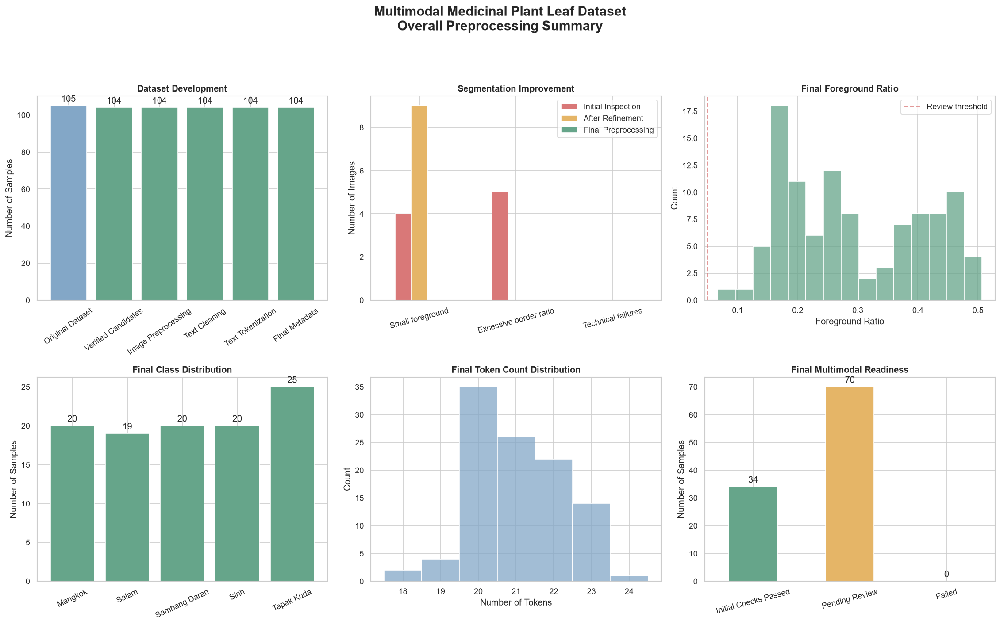


11. FINAL MULTIMODAL SAMPLE VISUALIZATION


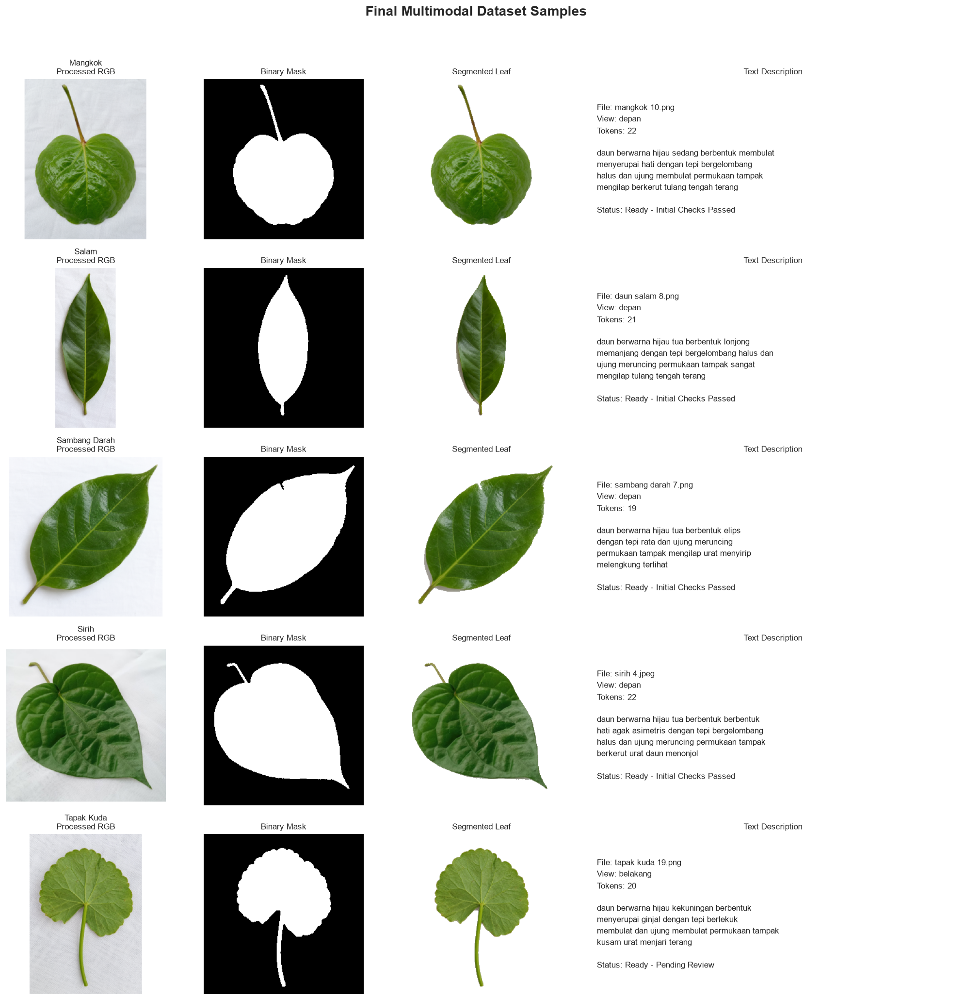


12. PREPROCESSING CONCLUSION

DATASET
Original samples        : 105
Final multimodal samples: 104
Total classes           : 5
Dataset retention rate  : 99.05%

IMAGE PREPROCESSING
Valid RGB images        : 104
Valid binary masks      : 104
ROI applied             : 103
Failed image processing : 0

TEXT PREPROCESSING
Valid text descriptions : 104
Total tokens            : 2188
Exploratory vocabulary  : 68
Average tokens          : 21.04

MULTIMODAL VALIDATION
Valid multimodal pairs  : 104
Initial checks passed   : 34
Pending quality review  : 70
Invalid multimodal pairs: 0

OUTPUT ARTIFACTS
Final metadata : D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv
Manifest       : D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\dataset_manifest.json
Summary report : D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\preprocessing_summary.json

[PASS] Image preprocessing completed.
[PASS] Text preprocessing completed.
[PASS] Multimodal metadata validation 

In [16]:
# ==================================================
# PREPROCESSING SUMMARY
# ==================================================

import json
from pathlib import Path

print("PREPROCESSING SUMMARY")
print("=" * 70)


# ==================================================
# 1. LOAD FINAL PROCESSED METADATA
# ==================================================

FINAL_METADATA_PATH = (
    PROCESSED_DIR / "metadata_processed.csv"
)

DATASET_MANIFEST_PATH = (
    PROCESSED_DIR / "dataset_manifest.json"
)

if not FINAL_METADATA_PATH.is_file():

    raise FileNotFoundError(
        "Final metadata not found. Run Cell 14 first."
    )

if not DATASET_MANIFEST_PATH.is_file():

    raise FileNotFoundError(
        "Dataset manifest not found. Run Cell 14 first."
    )

df_final_summary = pd.read_csv(
    FINAL_METADATA_PATH,
    encoding="utf-8-sig"
)

with open(
    DATASET_MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as file:

    final_manifest = json.load(file)


print("\n1. FINAL DATASET INFORMATION")

print(f"Dataset name    : {final_manifest['dataset_name']}")
print(f"Total samples   : {len(df_final_summary)}")
print(f"Total classes   : {df_final_summary['kelas'].nunique()}")
print(f"Metadata shape  : {df_final_summary.shape}")

display(df_final_summary.head())


# ==================================================
# 2. DEFINE VALIDATION HELPERS
# ==================================================

def count_true(series):

    return int(
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
        .sum()
    )


def count_status(dataframe, column, status):

    return int(
        dataframe[column]
        .eq(status)
        .sum()
    )


def load_metric_value(
    dataframe,
    indicator
):

    matched = dataframe.loc[
        dataframe["Indicator"].eq(indicator),
        "Result"
    ]

    if matched.empty:

        raise ValueError(
            f"Indicator not found: {indicator}"
        )

    return float(matched.iloc[0])


# ==================================================
# 3. COLLECT DATASET STATISTICS
# ==================================================

# Original dataset count from Notebook 01
ORIGINAL_DATASET_COUNT = 105

candidate_count = len(df_clean)

final_sample_count = len(df_final_summary)

class_count = (
    df_final_summary["kelas"].nunique()
)

removed_count = (
    ORIGINAL_DATASET_COUNT - candidate_count
)

dataset_retention_rate = (
    final_sample_count
    / ORIGINAL_DATASET_COUNT
    * 100
)

valid_multimodal_count = count_true(
    df_final_summary["multimodal_valid"]
)

invalid_multimodal_count = (
    final_sample_count
    - valid_multimodal_count
)

ready_count = count_status(
    df_final_summary,
    "final_dataset_status",
    "Ready - Initial Checks Passed"
)

pending_review_count = count_status(
    df_final_summary,
    "final_dataset_status",
    "Ready - Pending Review"
)

final_failed_count = count_status(
    df_final_summary,
    "final_dataset_status",
    "Failed"
)

assert (
    ready_count
    + pending_review_count
    + final_failed_count
    == final_sample_count
)

assert (
    final_sample_count
    == final_manifest["total_samples"]
)


# ==================================================
# 4. DATASET DEVELOPMENT SUMMARY
# ==================================================

dataset_development_df = pd.DataFrame({

    "Stage": [

        "Original Dataset",

        "Verified Candidates",

        "Image Preprocessing",

        "Text Cleaning",

        "Text Tokenization",

        "Final Metadata"
    ],

    "Number of Samples": [

        ORIGINAL_DATASET_COUNT,

        candidate_count,

        len(df_image_processed),

        len(df_text),

        len(df_tokenized),

        final_sample_count
    ]
})

dataset_development_df["Retention Rate (%)"] = (

    dataset_development_df["Number of Samples"]

    / ORIGINAL_DATASET_COUNT

    * 100

).round(2)

print("\n2. DATASET DEVELOPMENT SUMMARY")

display(dataset_development_df)


# ==================================================
# 5. IMAGE PREPROCESSING SUMMARY
# ==================================================

image_preprocessing_summary_df = pd.DataFrame({

    "Indicator": [

        "Total candidate images",

        "Successfully processed images",

        "Failed image preprocessing",

        "Valid RGB images",

        "Valid binary masks",

        "Aligned image-mask pairs",

        "ROI successfully applied",

        "ROI not applied",

        "Images with controlled hole filling",

        "Images with remaining internal holes",

        "Small foreground images",

        "Excessive border ratio",

        "Mean final foreground ratio (%)",

        "Image quality initial checks passed",

        "Image quality pending review"
    ],

    "Result": [

        candidate_count,

        len(df_image_processed),

        int(
            (~batch_results_df["processing_success"]
             .eq(True)).sum()
        ),

        count_true(
            df_final_summary["processed_image_valid"]
        ),

        count_true(
            df_final_summary["processed_mask_valid"]
        ),

        count_true(
            df_final_summary["image_mask_aligned"]
        ),

        count_true(
            df_final_summary["roi_applied"]
        ),

        final_sample_count - count_true(
            df_final_summary["roi_applied"]
        ),

        count_true(
            df_final_summary["hole_filling_applied"]
        ),

        int(
            df_final_summary[
                "remaining_internal_holes"
            ].gt(0).sum()
        ),

        int(
            df_final_summary[
                "final_foreground_ratio"
            ].lt(
                SMALL_FOREGROUND_REVIEW_RATIO
            ).sum()
        ),

        int(
            df_final_summary[
                "final_border_ratio"
            ].gt(
                REFINED_MAX_BORDER_RATIO
            ).sum()
        ),

        round(
            df_final_summary[
                "final_foreground_ratio"
            ].mean() * 100,
            4
        ),

        count_status(
            df_final_summary,
            "batch_status",
            "Passed Initial Check"
        ),

        count_status(
            df_final_summary,
            "batch_status",
            "Needs Review"
        )
    ]
})

print("\n3. IMAGE PREPROCESSING SUMMARY")

display(image_preprocessing_summary_df)


# ==================================================
# 6. SEGMENTATION IMPROVEMENT SUMMARY
# ==================================================

segmentation_progress_df = pd.DataFrame({

    "Indicator": [

        "Small foreground",

        "Excessive border ratio",

        "Technical failures"
    ],

    "Initial Inspection": [

        int(
            image_quality_df["foreground_ratio"]
            .lt(MIN_FOREGROUND_RATIO).sum()
        ),

        int(
            image_quality_df["border_ratio"]
            .gt(MAX_BORDER_RATIO).sum()
        ),

        count_status(
            image_quality_df,
            "inspection_status",
            "Failed"
        )
    ],

    "After Refinement": [

        int(
            refined_quality_df["foreground_ratio"]
            .lt(SMALL_FOREGROUND_REVIEW_RATIO).sum()
        ),

        int(
            refined_quality_df["border_ratio"]
            .gt(REFINED_MAX_BORDER_RATIO).sum()
        ),

        count_status(
            refined_quality_df,
            "inspection_status",
            "Failed"
        )
    ],

    "Final Preprocessing": [

        int(
            df_final_summary["final_foreground_ratio"]
            .lt(SMALL_FOREGROUND_REVIEW_RATIO).sum()
        ),

        int(
            df_final_summary["final_border_ratio"]
            .gt(REFINED_MAX_BORDER_RATIO).sum()
        ),

        int(
            (~batch_results_df["processing_success"]
             .eq(True)).sum()
        )
    ]
})

print("\n4. SEGMENTATION IMPROVEMENT SUMMARY")

display(segmentation_progress_df)


# ==================================================
# 7. TEXT PREPROCESSING SUMMARY
# ==================================================

# Reconstruct token sequences from saved metadata
saved_token_lists = (
    df_final_summary["tokens_json"]
    .apply(json.loads)
)

final_all_tokens = [

    token

    for tokens in saved_token_lists

    for token in tokens
]

final_vocabulary = sorted(
    set(final_all_tokens)
)

final_vocabulary_size = len(
    final_vocabulary
)

final_total_tokens = len(
    final_all_tokens
)

assert final_total_tokens == int(
    df_final_summary["token_count"].sum()
)

text_preprocessing_summary_df = pd.DataFrame({

    "Indicator": [

        "Total text descriptions",

        "Valid text descriptions",

        "Empty cleaned descriptions",

        "Empty tokenized descriptions",

        "Total tokens",

        "Exploratory vocabulary size",

        "Minimum tokens per description",

        "Maximum tokens per description",

        "Average tokens per description",

        "Average lexical diversity",

        "Duplicate token sequences",

        "Configured class-name mentions remaining",

        "Text quality initial checks passed",

        "Text quality pending review",

        "Failed tokenization"
    ],

    "Result": [

        final_sample_count,

        count_true(
            df_final_summary["processed_text_valid"]
        ),

        int(
            df_final_summary["cleaned_description"]
            .fillna("")
            .str.strip()
            .eq("").sum()
        ),

        int(
            df_final_summary["tokenized_description"]
            .fillna("")
            .str.strip()
            .eq("").sum()
        ),

        final_total_tokens,

        final_vocabulary_size,

        int(
            df_final_summary["token_count"].min()
        ),

        int(
            df_final_summary["token_count"].max()
        ),

        round(
            df_final_summary["token_count"].mean(),
            4
        ),

        round(
            df_final_summary["lexical_diversity"].mean(),
            4
        ),

        count_true(
            df_final_summary["duplicate_token_sequence"]
        ),

        int(
            df_final_summary["tokenized_description"]
            .apply(
                lambda text:
                len(detect_class_names(text)) > 0
            ).sum()
        ),

        count_status(
            df_final_summary,
            "text_quality_status",
            "Passed Initial Check"
        ),

        count_status(
            df_final_summary,
            "text_quality_status",
            "Needs Review"
        ),

        count_status(
            df_final_summary,
            "tokenization_status",
            "Failed"
        )
    ]
})

print("\n5. TEXT PREPROCESSING SUMMARY")

display(text_preprocessing_summary_df)


# ==================================================
# 8. FINAL CLASS DISTRIBUTION
# ==================================================

final_class_summary_df = (

    df_final_summary

    .groupby("kelas")

    .agg(

        total_samples=(
            "sample_id",
            "count"
        ),

        average_tokens=(
            "token_count",
            "mean"
        ),

        mean_foreground_ratio=(
            "final_foreground_ratio",
            "mean"
        )
    )
)

final_class_summary_df[
    "percentage"
] = (

    final_class_summary_df["total_samples"]

    / final_sample_count

    * 100
)

final_class_summary_df[
    "mean_foreground_ratio"
] *= 100

final_class_summary_df = (
    final_class_summary_df.reset_index()
)

print("\n6. FINAL CLASS DISTRIBUTION")

display(
    final_class_summary_df.round(4)
)


# ==================================================
# 9. FINAL QUALITY REVIEW SUMMARY
# ==================================================

eda_review_count = 0

if "manual_review_required" in df_final_summary.columns:

    eda_review_count = count_true(
        df_final_summary["manual_review_required"]
    )

image_review_count = count_status(
    df_final_summary,
    "batch_status",
    "Needs Review"
)

text_review_count = count_status(
    df_final_summary,
    "text_quality_status",
    "Needs Review"
)

token_review_count = count_status(
    df_final_summary,
    "tokenization_status",
    "Needs Review"
)

review_summary_df = pd.DataFrame({

    "Review Source": [

        "EDA Manual Review",

        "Image Quality Review",

        "Text Quality Review",

        "Tokenization Review",

        "Unique Samples Pending Review"
    ],

    "Number of Samples": [

        eda_review_count,

        image_review_count,

        text_review_count,

        token_review_count,

        pending_review_count
    ]
})

print("\n7. FINAL QUALITY REVIEW SUMMARY")

display(review_summary_df)

print(
    "[NOTE] Review categories may overlap."
)

print(
    "[NOTE] Pending review does not mean "
    "technical preprocessing failure."
)


# ==================================================
# 10. VALIDATE FINAL DATASET FILES
# ==================================================

print("\n8. FINAL DATASET FILE VALIDATION")

required_artifacts = {

    "Final metadata": FINAL_METADATA_PATH,

    "Dataset manifest": DATASET_MANIFEST_PATH,

    "Image preprocessing configuration": (
        FINAL_CONFIG_PATH
    ),

    "Text preprocessing configuration": (
        TEXT_CONFIG_PATH
    )
}

artifact_validation_records = []

for artifact_name, artifact_path in (
    required_artifacts.items()
):

    artifact_path = Path(artifact_path)

    artifact_validation_records.append({

        "Artifact": artifact_name,

        "Path": str(artifact_path),

        "Available": artifact_path.is_file()
    })

artifact_validation_df = pd.DataFrame(
    artifact_validation_records
)

display(artifact_validation_df)

# Validate referenced image and mask paths
existing_image_count = sum(

    (
        PROJECT_ROOT / Path(path)
    ).is_file()

    for path in df_final_summary[
        "processed_image_path"
    ]
)

existing_mask_count = sum(

    (
        PROJECT_ROOT / Path(path)
    ).is_file()

    for path in df_final_summary["mask_path"]
)

print(f"Referenced RGB files  : {existing_image_count}")
print(f"Referenced mask files : {existing_mask_count}")


# ==================================================
# 11. FEATURE EXTRACTION READINESS
# ==================================================

image_input_ready = (

    existing_image_count == final_sample_count

    and count_true(
        df_final_summary["processed_image_valid"]
    ) == final_sample_count
)

mask_input_ready = (

    existing_mask_count == final_sample_count

    and count_true(
        df_final_summary["processed_mask_valid"]
    ) == final_sample_count

    and count_true(
        df_final_summary["image_mask_aligned"]
    ) == final_sample_count
)

text_input_ready = (

    count_true(
        df_final_summary["processed_text_valid"]
    ) == final_sample_count

    and df_final_summary["token_count"]
    .gt(0).all()
)

metadata_ready = (

    df_final_summary["sample_id"].is_unique

    and df_final_summary["image_path"].is_unique

    and valid_multimodal_count == final_sample_count

    and final_sample_count == candidate_count

    and final_failed_count == 0

    and artifact_validation_df["Available"].all()
)

feature_extraction_ready = bool(

    image_input_ready

    and mask_input_ready

    and text_input_ready

    and metadata_ready
)

readiness_df = pd.DataFrame({

    "Component": [

        "Processed RGB Images",

        "Binary Masks",

        "HSV Histogram Input",

        "GLCM Input",

        "Hu Moments Input",

        "TF-IDF Input",

        "Multimodal Metadata",

        "Feature Extraction"
    ],

    "Ready": [

        image_input_ready,

        mask_input_ready,

        image_input_ready and mask_input_ready,

        image_input_ready and mask_input_ready,

        mask_input_ready,

        text_input_ready,

        metadata_ready,

        feature_extraction_ready
    ]
})

readiness_df["Status"] = np.where(

    readiness_df["Ready"],

    "Technically Ready",

    "Not Ready"
)

print("\n9. FEATURE EXTRACTION READINESS")

display(readiness_df)


# ==================================================
# 12. CREATE FINAL PREPROCESSING SUMMARY
# ==================================================

preprocessing_summary_df = pd.DataFrame({

    "Category": [

        "Dataset",

        "Dataset",

        "Dataset",

        "Dataset",

        "Dataset",

        "Image",

        "Image",

        "Image",

        "Text",

        "Text",

        "Text",

        "Multimodal",

        "Multimodal",

        "Multimodal",

        "Multimodal"
    ],

    "Indicator": [

        "Original dataset",

        "Removed candidates",

        "Final samples",

        "Total classes",

        "Dataset retention rate (%)",

        "Valid RGB images",

        "Valid binary masks",

        "Image preprocessing success rate (%)",

        "Valid descriptions",

        "Total tokens",

        "Exploratory vocabulary size",

        "Valid multimodal pairs",

        "Initial checks passed",

        "Pending quality review",

        "Invalid multimodal pairs"
    ],

    "Result": [

        ORIGINAL_DATASET_COUNT,

        removed_count,

        final_sample_count,

        class_count,

        round(dataset_retention_rate, 2),

        count_true(
            df_final_summary["processed_image_valid"]
        ),

        count_true(
            df_final_summary["processed_mask_valid"]
        ),

        round(
            len(df_image_processed)
            / candidate_count * 100,
            2
        ),

        count_true(
            df_final_summary["processed_text_valid"]
        ),

        final_total_tokens,

        final_vocabulary_size,

        valid_multimodal_count,

        ready_count,

        pending_review_count,

        invalid_multimodal_count
    ]
})

print("\n10. FINAL PREPROCESSING SUMMARY")

display(preprocessing_summary_df)


# ==================================================
# 13. VISUALIZE OVERALL PREPROCESSING RESULTS
# ==================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

# --------------------------------------------------
# A. Dataset development
# --------------------------------------------------

axes[0, 0].bar(

    dataset_development_df["Stage"],

    dataset_development_df["Number of Samples"],

    color=[
        "#83A7C7",
        "#66A58A",
        "#66A58A",
        "#66A58A",
        "#66A58A",
        "#66A58A"
    ]
)

axes[0, 0].set_title(
    "Dataset Development",
    fontweight="bold"
)

axes[0, 0].set_ylabel(
    "Number of Samples"
)

axes[0, 0].tick_params(
    axis="x",
    rotation=35
)

for container in axes[0, 0].containers:

    axes[0, 0].bar_label(
        container,
        padding=3
    )


# --------------------------------------------------
# B. Segmentation improvement
# --------------------------------------------------

segmentation_progress_df.set_index(

    "Indicator"

).plot(

    kind="bar",

    color=[
        "#D97878",
        "#E5B567",
        "#66A58A"
    ],

    rot=15,

    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Segmentation Improvement",
    fontweight="bold"
)

axes[0, 1].set_ylabel(
    "Number of Images"
)

axes[0, 1].set_xlabel("")


# --------------------------------------------------
# C. Final foreground ratio
# --------------------------------------------------

sns.histplot(

    data=df_final_summary,

    x="final_foreground_ratio",

    bins=15,

    color="#66A58A",

    ax=axes[0, 2]
)

axes[0, 2].axvline(

    SMALL_FOREGROUND_REVIEW_RATIO,

    color="#D97878",

    linestyle="--",

    label="Review threshold"
)

axes[0, 2].set_title(
    "Final Foreground Ratio",
    fontweight="bold"
)

axes[0, 2].set_xlabel(
    "Foreground Ratio"
)

axes[0, 2].legend()


# --------------------------------------------------
# D. Final class distribution
# --------------------------------------------------

axes[1, 0].bar(

    final_class_summary_df["kelas"],

    final_class_summary_df["total_samples"],

    color="#66A58A"
)

axes[1, 0].set_title(
    "Final Class Distribution",
    fontweight="bold"
)

axes[1, 0].set_ylabel(
    "Number of Samples"
)

axes[1, 0].tick_params(
    axis="x",
    rotation=25
)

for container in axes[1, 0].containers:

    axes[1, 0].bar_label(
        container,
        padding=3
    )


# --------------------------------------------------
# E. Final token distribution
# --------------------------------------------------

sns.histplot(

    data=df_final_summary,

    x="token_count",

    discrete=True,

    color="#83A7C7",

    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Final Token Count Distribution",
    fontweight="bold"
)

axes[1, 1].set_xlabel(
    "Number of Tokens"
)


# --------------------------------------------------
# F. Final multimodal status
# --------------------------------------------------

final_quality_counts = pd.Series({

    "Initial Checks Passed": ready_count,

    "Pending Review": pending_review_count,

    "Failed": final_failed_count
})

final_quality_counts.plot(

    kind="bar",

    color=[
        "#66A58A",
        "#E5B567",
        "#D97878"
    ],

    rot=15,

    ax=axes[1, 2]
)

axes[1, 2].set_title(
    "Final Multimodal Readiness",
    fontweight="bold"
)

axes[1, 2].set_ylabel(
    "Number of Samples"
)

for container in axes[1, 2].containers:

    axes[1, 2].bar_label(
        container,
        padding=3
    )


fig.suptitle(

    "Multimodal Medicinal Plant Leaf Dataset"
    "\nOverall Preprocessing Summary",

    fontsize=18,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.93]
)

plt.savefig(

    FIGURES_DIR /
    "23_overall_preprocessing_summary.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ==================================================
# 14. VISUALIZE FINAL MULTIMODAL SAMPLES
# ==================================================

print("\n11. FINAL MULTIMODAL SAMPLE VISUALIZATION")

representative_records = []

for plant_class, group in (
    df_final_summary.groupby("kelas")
):

    passed_group = group[

        group["final_dataset_status"]

        .eq("Ready - Initial Checks Passed")
    ]

    available_group = (

        passed_group

        if not passed_group.empty

        else group
    )

    selected_sample = available_group.sample(

        n=1,

        random_state=RANDOM_STATE

    ).iloc[0]

    representative_records.append(
        selected_sample
    )


fig, axes = plt.subplots(

    len(representative_records),

    4,

    figsize=(
        17,
        3.5 * len(representative_records)
    ),

    squeeze=False,

    gridspec_kw={
        "width_ratios": [1, 1, 1, 2]
    }
)

import textwrap

for row_index, row in enumerate(
    representative_records
):

    # Load processed RGB image
    with Image.open(

        PROJECT_ROOT /
        row["processed_image_path"]

    ) as image:

        rgb = np.array(
            image.convert("RGB")
        )

    # Load binary mask
    with Image.open(

        PROJECT_ROOT /
        row["mask_path"]

    ) as image:

        mask = np.array(
            image.convert("L")
        )

    segmented = apply_leaf_mask(
        rgb,
        mask
    )

    # Processed RGB
    axes[row_index, 0].imshow(rgb)

    axes[row_index, 0].set_title(
        f"{row['kelas']}\nProcessed RGB",
        fontsize=10
    )

    # Binary mask
    axes[row_index, 1].imshow(

        mask,

        cmap="gray",

        vmin=0,

        vmax=255
    )

    axes[row_index, 1].set_title(
        "Binary Mask",
        fontsize=10
    )

    # Segmented image
    axes[row_index, 2].imshow(
        segmented
    )

    axes[row_index, 2].set_title(
        "Segmented Leaf",
        fontsize=10
    )

    # Text modality
    wrapped_description = textwrap.fill(

        row["tokenized_description"],

        width=45
    )

    description_text = (

        f"File: {row['nama_file']}\n"

        f"View: {row['tampilan_daun']}\n"

        f"Tokens: {row['token_count']}\n\n"

        f"{wrapped_description}\n\n"

        f"Status: {row['final_dataset_status']}"
    )

    axes[row_index, 3].text(

        0.03,

        0.5,

        description_text,

        transform=axes[row_index, 3].transAxes,

        fontsize=10,

        va="center",

        ha="left",

        linespacing=1.5
    )

    axes[row_index, 3].set_title(
        "Text Description",
        fontsize=10
    )

    for ax in axes[row_index]:

        ax.axis("off")


fig.suptitle(

    "Final Multimodal Dataset Samples",

    fontsize=17,

    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(

    FIGURES_DIR /
    "24_final_multimodal_samples.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ==================================================
# 15. SAVE PREPROCESSING REPORTS
# ==================================================

summary_reports = {

    "62_dataset_development_summary.csv": (
        dataset_development_df
    ),

    "63_image_preprocessing_final_summary.csv": (
        image_preprocessing_summary_df
    ),

    "64_segmentation_improvement_summary.csv": (
        segmentation_progress_df
    ),

    "65_text_preprocessing_final_summary.csv": (
        text_preprocessing_summary_df
    ),

    "66_final_class_summary.csv": (
        final_class_summary_df
    ),

    "67_final_quality_review_summary.csv": (
        review_summary_df
    ),

    "68_feature_extraction_readiness.csv": (
        readiness_df
    ),

    "69_overall_preprocessing_summary.csv": (
        preprocessing_summary_df
    ),

    "70_preprocessing_artifact_validation.csv": (
        artifact_validation_df
    )
}

for filename, dataframe in summary_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig"
    )


# ==================================================
# 16. SAVE PREPROCESSING SUMMARY JSON
# ==================================================

preprocessing_report = {

    "notebook": "02_preprocessing.ipynb",

    "dataset": {

        "original_samples": int(
            ORIGINAL_DATASET_COUNT
        ),

        "verified_candidates": int(
            candidate_count
        ),

        "final_samples": int(
            final_sample_count
        ),

        "total_classes": int(
            class_count
        ),

        "retention_rate_percent": float(
            round(dataset_retention_rate, 2)
        )
    },

    "image_preprocessing": {

        "target_size": [
            TARGET_WIDTH,
            TARGET_HEIGHT
        ],

        "aspect_ratio_preserved": True,

        "segmentation": (
            "Refined Adaptive Selection"
        ),

        "roi_cropping": bool(
            APPLY_ROI_CROPPING
        ),

        "controlled_hole_filling": bool(
            APPLY_CONTROLLED_HOLE_FILLING
        ),

        "denoising": bool(
            APPLY_DENOISING
        ),

        "valid_rgb_images": int(
            count_true(
                df_final_summary["processed_image_valid"]
            )
        ),

        "valid_binary_masks": int(
            count_true(
                df_final_summary["processed_mask_valid"]
            )
        ),

        "failed_processing": int(
            len(failed_batch_df)
        )
    },

    "text_preprocessing": {

        "unicode_normalization": bool(
            APPLY_UNICODE_NORMALIZATION
        ),

        "case_folding": bool(
            APPLY_CASE_FOLDING
        ),

        "punctuation_removal": bool(
            REMOVE_PUNCTUATION
        ),

        "stopword_removal": bool(
            REMOVE_STOPWORDS
        ),

        "stemming": bool(
            APPLY_STEMMING
        ),

        "token_pattern": TOKEN_PATTERN,

        "total_tokens": int(
            final_total_tokens
        ),

        "exploratory_vocabulary_size": int(
            final_vocabulary_size
        )
    },

    "quality_assessment": {

        "initial_checks_passed": int(
            ready_count
        ),

        "pending_review": int(
            pending_review_count
        ),

        "invalid_multimodal_pairs": int(
            invalid_multimodal_count
        ),

        "botanical_labels_verified": False,

        "manual_review_completed": False
    },

    "readiness": {

        "feature_extraction_ready": bool(
            feature_extraction_ready
        ),

        "feature_extraction_completed": False,

        "tfidf_fitted": False,

        "fusion_completed": False,

        "final_evaluation_completed": False
    },

    "next_notebook": (
        "03_image_feature_extraction.ipynb"
    )
}

PREPROCESSING_REPORT_PATH = (

    PROCESSED_DIR /

    "preprocessing_summary.json"
)

with open(

    PREPROCESSING_REPORT_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        preprocessing_report,

        file,

        indent=4,

        ensure_ascii=False
    )


# ==================================================
# 17. UPDATE DATASET MANIFEST
# ==================================================

final_manifest.update({

    "preprocessing_completed": bool(
        feature_extraction_ready
    ),

    "feature_extraction_ready": bool(
        feature_extraction_ready
    ),

    "records_pending_review": int(
        pending_review_count
    ),

    "manual_quality_review_completed": False,

    "botanical_label_verification_completed": False,

    "preprocessing_summary_path": (

        PREPROCESSING_REPORT_PATH

        .relative_to(PROJECT_ROOT)

        .as_posix()
    ),

    "dataset_status": (

        "Technically Ready - Pending Quality Review"

        if feature_extraction_ready
        and pending_review_count > 0

        else "Technically Ready"

        if feature_extraction_ready

        else "Not Ready"
    )
})

with open(

    DATASET_MANIFEST_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        final_manifest,

        file,

        indent=4,

        ensure_ascii=False
    )


# ==================================================
# 18. FINAL PREPROCESSING CONCLUSION
# ==================================================

print("\n12. PREPROCESSING CONCLUSION")

print("=" * 70)

print("\nDATASET")

print(f"Original samples        : {ORIGINAL_DATASET_COUNT}")
print(f"Final multimodal samples: {final_sample_count}")
print(f"Total classes           : {class_count}")
print(f"Dataset retention rate  : {dataset_retention_rate:.2f}%")

print("\nIMAGE PREPROCESSING")

print(f"Valid RGB images        : {existing_image_count}")
print(f"Valid binary masks      : {existing_mask_count}")

print(

    f"ROI applied             : "

    f"{count_true(df_final_summary['roi_applied'])}"
)

print(f"Failed image processing : {len(failed_batch_df)}")

print("\nTEXT PREPROCESSING")

print(

    f"Valid text descriptions : "

    f"{count_true(df_final_summary['processed_text_valid'])}"
)

print(f"Total tokens            : {final_total_tokens}")

print(f"Exploratory vocabulary  : {final_vocabulary_size}")

print(

    f"Average tokens          : "

    f"{df_final_summary['token_count'].mean():.2f}"
)

print("\nMULTIMODAL VALIDATION")

print(f"Valid multimodal pairs  : {valid_multimodal_count}")

print(f"Initial checks passed   : {ready_count}")

print(f"Pending quality review  : {pending_review_count}")

print(f"Invalid multimodal pairs: {invalid_multimodal_count}")

print("\nOUTPUT ARTIFACTS")

print(f"Final metadata : {FINAL_METADATA_PATH}")

print(f"Manifest       : {DATASET_MANIFEST_PATH}")

print(f"Summary report : {PREPROCESSING_REPORT_PATH}")

print("\n" + "=" * 70)


# Stop progression if technical validation fails
if not feature_extraction_ready:

    raise RuntimeError(

        "Dataset is not technically ready. "
        "Inspect feature extraction readiness reports."
    )

print("[PASS] Image preprocessing completed.")

print("[PASS] Text preprocessing completed.")

print("[PASS] Multimodal metadata validation completed.")

print("[PASS] Dataset is technically ready for feature extraction.")

if pending_review_count > 0:

    print(

        f"[REVIEW] {pending_review_count} samples "
        "still require quality review."
    )

print(

    "[REVIEW] Botanical ground-truth labels "
    "must be verified before final evaluation."
)

print("\n[INFO] No additional samples have been removed.")

print("[INFO] Feature extraction has not been performed.")

print("[INFO] TF-IDF has not been fitted.")

print("[INFO] Multimodal fusion has not been performed.")

print("\n" + "=" * 70)

print("NOTEBOOK 02 - PREPROCESSING COMPLETED")

print("=" * 70)

print("\nNext notebook:")

print("03_image_feature_extraction.ipynb")

print("\nPlanned visual feature extraction:")

print("1. HSV Histogram - Color Features")

print("2. GLCM - Texture Features")

print("3. Hu Moments - Shape Features")